# AIFS — Energy Demand Forecasting: Extended Benchmark (v10) — ETTH1 only, STANDARD mode (all data)

**Dataset (current):** UCI Individual Household Electric Power Consumption (IHEPC) · **Task:** hourly Global_active_power forecasting
**Extends:** the earlier 5-model notebook (LSTM, GRU, CNN-LSTM, Prophet, XGBoost) → ~27 models, tuned, evaluated leakage-free.

> **v9:** (1) Diebold–Mariano test now uses a proper autocorrelation correction (the old one inflated false “significant” verdicts at 1 h);
> (2) Prophet's yearly seasonality is switched on explicitly when ≥300 days of training data exist; (3) one-line `PRESET`s in Cell 2 for the recommended runs.

> **v10 — what is new**
> 1. **Apple-GPU / CUDA memory fix and speed-ups** (Cell 10): memory is released after every trial and model, tensor shapes are kept constant,
>    out-of-memory is recovered (retry, then CPU), and a 10-second CPU-vs-GPU test picks the faster device for each network. The v9 PJM run lost
>    11 models to "MPS backend out of memory"; each printed model line now also shows the GPU memory in use so you can see the fix working.
> 2. **Faster foundation models:** Chronos-2 uses the array API (no per-window DataFrames); TimesFM compiles only the context length it needs.
> 3. **More datasets:** `spain` (load + weather, with the operator's day-ahead forecast as a reference baseline) and `etth1`, next to `ihepc` and `pjm`.
>    Weather is a *known-in-advance* covariate; the framework now distinguishes covariates known for the forecast hours from those only observed later.
> 4. **Cross-dataset comparison** (Cell 19): difficulty table, MASE/NRMSE heat-maps, mean rank, relative error, family summary, ensemble gain, LaTeX tables.
>
> **Workflow:** run the notebook once per dataset (set `PRESET` in Cell 2 — e.g. `'ihepc_fast'`, `'pjm_fast'`, `'spain_fast'`, `'etth1_fast'` — restart the kernel
> between datasets), always with the same `RUN_MODE`; results accumulate in `aifs_results_<RUN_MODE>/`. Then run Cell 19.

## What changed vs. the old notebook (and why)
| Old notebook | This notebook |
|---|---|
| Concurrent electrical channels (same hour as target) used as inputs → near-deterministic regression, not forecasting | **Setting A (headline):** only information available at the forecast origin. **Setting B:** old setup, kept only as a labelled reference + leakage ablation |
| LSTM/GRU/CNN-LSTM got sequence length 1 (i.e. MLPs) | Real windows (lookback L, tuned) |
| Target clipped to 1–99 pct on all data; scalers fit on train+test | Target **not** clipped; every scaler/clip bound fit on **train only** |
| Unscaled calendar features, batch_size=1, depth-50 XGBoost | Sin/cos calendar, tuned batch size, tuned tree depth |
| No baselines, 1 seed, no tuning | Persistence / seasonal-naive baselines, Optuna tuning, multi-seed (FULL mode), MASE, Diebold–Mariano tests |
| Imputed hours evaluated as if real | Metrics computed **only on hours where the target was actually observed** |

## Model zoo (32 models)
- **Baselines (5):** Persistence, SeasonalNaive-24, SeasonalNaive-168, Ridge, Prophet
- **Tree/ML (5):** XGBoost, LightGBM, CatBoost, RandomForest, ExtraTrees
- **Deep learning, PyTorch (8):** MLP, LSTM, GRU, BiLSTM, CNN-LSTM, TCN, N-BEATS, N-HiTS
- **Transformers (9):** vanilla Transformer, PatchTST-style, iTransformer-style, DLinear, TSMixer,
  Informer-style (ProbSparse attention), Autoformer-style (series decomposition + autocorrelation),
  TimesNet-style (FFT period detection + inception blocks), a compact Temporal Fusion Transformer
- **Generative (1):** conditional VAE (probabilistic forecaster)
- **Foundation models, zero-shot (5):** Chronos-Bolt-small, Chronos-Bolt-base, TimesFM-2.5, TiRex
  (context-length tuned, univariate), **Chronos-2** (covariate-aware: past covariates + known-future
  calendar features, via its native `predict_df` API)
- **Ensembles (2):** top-3 mean, top-5 inverse-MSE weighted

Every tunable model (all but the baselines and foundation models) is tuned with Optuna against
**rolling-origin cross-validation** inside train+val — `M['cv_folds']` windows (1 for SMOKE/STANDARD,
3 for FULL; fold 0 always equals the plain train/val split, so SMOKE/STANDARD behave exactly as a
single held-out validation set while FULL gets true walk-forward CV). See Cell 6 (`cv_folds`) and
Cell 8 (`get_fold_splits` for tabular models, `cv` list inside `run_nn` for neural models).

## Running on a Mac (Apple Silicon) — read this first
1. **Cell 0 must be the FIRST cell you run after every kernel restart.** It sets the OpenMP guard that stops PyTorch + XGBoost/LightGBM from killing the kernel. If it prints a WARNING, restart the kernel and run it again first.
2. Run Cell 1 (`%pip` installs) only the first time, then restart the kernel. (`libomp` is a Homebrew package, not a pip package — do **not** `pip install libomp`. You only need `brew reinstall libomp` if the preflight in Cell 3 says XGBoost/LightGBM are broken.)
3. Before using XGBoost/LightGBM/CatBoost the notebook tests each in a **separate process**; a broken one is skipped with the fix printed.
4. **Crash recovery:** if the kernel still dies mid-run, just restart it and run Cells 0, 2, 3, … again. The notebook remembers which model was running: a neural net that died on the GPU is retried on CPU; anything that dies on CPU is skipped (listed in `state/skip.json`). Finished models are never recomputed.
5. **GPU:** neural nets use Apple's `mps` when available (each architecture is probed; failures fall back to CPU). To avoid the GPU entirely set `CFG['NN_DEVICE']='cpu'` and `CFG['FM_DEVICE']='cpu'`.
6. Start with `RUN_MODE='SMOKE'` (minutes), then `'LITE'` (laptop-sized). `STANDARD`/`FULL` on all models is hours-to-days on a laptop — use Kaggle GPU for those, or drop the slowest with `CFG['EXCLUDE']=['TimesNet','TFT','Autoformer','Informer']`.
7. Results go to `aifs_results_<RUN_MODE>/` — each mode has its own folder.

## How to run
1. Set `DATA_PATHS['ihepc']` in the CONFIG cell (or leave the filename — the notebook searches the working folder and `/kaggle/input`).
2. **First run with `RUN_MODE='SMOKE'`** (minutes; tiny subset; verifies every model runs).
3. Then `RUN_MODE='STANDARD'` (a few hours on a laptop GPU/CPU mix) or `'FULL'` (long; use Kaggle GPU and re-run cells — finished models are skipped, so a session timeout loses nothing).
4. Everything is written to `OUT_DIR` (results CSV, predictions, tuning logs, figures).

> **Honesty notes:** foundation-model wrappers (Chronos-Bolt, TimesFM-2.5, TiRex) depend on fast-moving third-party APIs. If one fails to load, it is logged and skipped — nothing else breaks. Results will **not** match the paper's numbers, because the paper's setup contained the concurrent-covariate leakage described above.

---
## Changes in this version (v7)
- **TiRex fixed at H=1:** output shapes are now forced to `(B,H)` / `(B,H,9)` (the old code crashed with `IndexError: array is 1-dimensional`), with a one-series-at-a-time fallback.
- **Leaderboard prints as plain text** (full ranking + best model per family + a `beats_snaive24` column), and the styled table is only an extra. CSVs are still saved in the results folder.
- **Default `RUN_MODE` is now `LITE`** (12,000 hours, 15 epochs). Results go to `aifs_results_LITE/`, so the earlier SMOKE results are not mixed in.
- Reminder: SMOKE = pipeline test only. Rankings among the top models are only meaningful from LITE/STANDARD/FULL runs.


---
## Changes in this version (v8)
- **Units are per dataset** (`kW` for IHEPC, `MW` for PJM, `°C` for ETTh1) in every plot label and summary line. The old text said "kW" even for PJM (MW).
- **New baseline `Prophet-Anchored`** next to the unchanged plain `Prophet`. Plain Prophet never sees recent data, so it is compared unfairly against models that do; Anchored carries the current gap between Prophet and reality forward with a validation-chosen decay. Both stay in the tables (Setting A only).
- **New cell "17b — Paper-ready tables":** CSV + Markdown + LaTeX tables (full results with skill score and Diebold–Mariano markers, headline summary, best-per-family) and an auto-written results paragraph, saved in `<results folder>/paper_tables/`.
- Re-running on a dataset you already finished is fast: finished models are skipped, only `Prophet-Anchored` and the new tables are computed.
- **To run your main dataset next:** set `DATASET = 'ihepc'` in the config cell, restart the kernel, run all cells.

In [1]:
# ============================================================
# CELL 0 — RUN THIS FIRST, in a freshly restarted kernel, BEFORE anything else.
# On macOS, PyTorch and XGBoost/LightGBM each bundle their own OpenMP runtime; loading both can kill the kernel.
# These settings must be applied BEFORE numpy/torch/xgboost are imported.
# ============================================================
import os, sys, platform
if platform.system() == 'Darwin':
    os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'      # allow the duplicate libomp
    os.environ['OMP_NUM_THREADS']      = '4'
    os.environ['MKL_NUM_THREADS']      = '4'
    os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'  # unsupported Apple-GPU ops fall back to CPU
    _already = [m for m in ('numpy', 'torch', 'xgboost', 'lightgbm', 'sklearn') if m in sys.modules]
    if _already:
        print(f"WARNING: {_already} were already imported in this kernel, so the settings above may NOT take effect.")
        print("         -> Kernel menu > Restart, then run THIS cell first. (Skip Cell 1 after the first install.)")
    else:
        print("Mac OpenMP guard active (KMP_DUPLICATE_LIB_OK=TRUE, 4 threads).")
else:
    print("Not macOS - no OpenMP guard needed.")

Mac OpenMP guard active (KMP_DUPLICATE_LIB_OK=TRUE, 4 threads).


In [2]:
# # ============================================================
# # CELL 1 — Install libraries.  Run ONCE, then RESTART THE KERNEL, then run from CELL 2.
# # %pip installs into the *running kernel's* Python (a plain "!pip" can hit the wrong Python on a Mac).
# # ============================================================
# %pip install -q optuna xgboost lightgbm catboost prophet holidays seaborn pyarrow
# %pip install -q chronos-forecasting
# %pip install -q tirex-ts
# %pip install -q "timesfm[torch]"
# # (If one of the last three fails on your machine, that is fine — the notebook skips that model.)

# # ---- Mac (Apple Silicon) one-time setup, run in Terminal, NOT here ----
# #   arch -arm64 brew reinstall libomp        # XGBoost/LightGBM need an arm64 libomp
# #   (error "incompatible architecture (have 'x86_64', need 'arm64')" = Intel libomp installed by mistake)
# # PyTorch on Mac: pip install torch   (the Apple GPU "MPS" backend is detected automatically)

In [3]:
# ============================================================
# CELL 2 — CONFIG  (the only cell you normally need to edit)
# ============================================================
import os

CFG = dict(
    RUN_MODE   = 'STANDARD',             # 'SMOKE' (verify, minutes) | 'LITE' (laptop, ~1-3 h) | 'STANDARD' | 'FULL'
                                 # QUICK TiRex CHECK: set RUN_MODE='SMOKE' and MODELS=['TiRex'] -> reruns only TiRex (~2 min)
    DATASET    = 'etth1',            # key in DATASETS registry (see dataset cell)
    DATA_PATHS = {                   # <-- update paths here. Bare filenames are searched for automatically.
        'ihepc': '/Users/akshdharodiya/Desktop/AI MY CLASS WORK /sem_5_my_material/sem5_lab_practical/SEM_5_PROJECT/u23ai031_ds/0_sem_7/household_power_consumption.txt',
        'pjm'  : '/Users/akshdharodiya/Desktop/AI MY CLASS WORK /sem_5_my_material/sem5_lab_practical/SEM_5_PROJECT/u23ai031_ds/0_sem_7/archive/PJMW_hourly.csv',
        'etth1': '/Users/akshdharodiya/Desktop/AI MY CLASS WORK /sem_5_my_material/sem5_lab_practical/SEM_5_PROJECT/u23ai031_ds/0_sem_7/ETDataset-main/ETT-small/ETTh1.csv',
        'spain': 'energy_dataset.csv',    # Kaggle "Hourly energy demand generation and weather"; weather_features.csv in the same folder
    },
    OUT_DIR    = '/kaggle/working/aifs_results' if os.path.isdir('/kaggle/working') else 'aifs_results',
                                     # (suffix _<RUN_MODE> is added automatically so SMOKE/LITE/STANDARD/FULL never mix)
    SETTINGS   = ['A'],              # 'A' = true forecasting (headline). 'B' = concurrent covariates (reference only)
    HORIZONS   = [1, 24],            # forecast horizon in hours: 1-step and day-ahead (24 steps, direct multi-output)
    MODELS     = None,               # None = all available models, or e.g. ['XGBoost','LSTM','PatchTST']
    EXCLUDE    = [],                 # models to skip, e.g. ['TimesNet','TFT'] (the slowest ones) on a laptop
    FM_DEVICE  = 'auto',             # foundation models: 'auto' (cuda > mps > cpu, probed, falls back to cpu) | 'cpu'
    NN_DEVICE  = 'auto',             # neural nets: 'auto' (cuda > mps > cpu, each net probed) | 'cpu'
    AUTO_DEVICE = True,              # v10: time CPU vs GPU for each neural model and use the faster one (cached)
    RUN_FOUNDATION = True,           # Chronos / TimesFM / TiRex (needs internet for weights)
    RUN_PROPHET    = True,
    REFIT_TRAINVAL = True,           # after tuning, refit on train+val for the test predictions
    FORCE_RERUN    = False,          # True = ignore saved results and recompute
    SEED       = 42,
)

# Budget per run mode. trials_* = Optuna trials per model; seeds = repeats of the final fit.
# ---- v9 PRESETS: set PRESET to one name and run all cells (or None to use the CFG above as written) ----
# Restart the kernel between presets / datasets (cached data bundles live in memory).
SLOW_9   = ['TimesFM-2.5', 'BiLSTM', 'TFT', 'Autoformer', 'TimesNet', 'Informer', 'Transformer', 'TiRex', 'Chronos-2']   # ~84% of the PJM LITE runtime
PAPER_5  = ['LSTM', 'GRU', 'CNN-LSTM', 'Prophet', 'XGBoost']                                                               # the models of the original paper
PRESETS = {
    # ---- one dataset at a time (results of all datasets accumulate in the same result folder for a given RUN_MODE) ----
    'paper_repro': dict(DATASET='ihepc', RUN_MODE='STANDARD', SETTINGS=['A', 'B'], RUN_FOUNDATION=False,
                        MODELS=PAPER_5 + ['Ridge', 'Persistence', 'SeasonalNaive-24', 'SeasonalNaive-168']),
    'ihepc_fast':  dict(DATASET='ihepc', RUN_MODE='LITE', SETTINGS=['A'], EXCLUDE=SLOW_9),
    'pjm_fast':    dict(DATASET='pjm',   RUN_MODE='LITE', SETTINGS=['A'], EXCLUDE=SLOW_9),
    'spain_fast':  dict(DATASET='spain', RUN_MODE='LITE', SETTINGS=['A'], EXCLUDE=SLOW_9),
    'etth1_fast':  dict(DATASET='etth1', RUN_MODE='LITE', SETTINGS=['A'], EXCLUDE=SLOW_9),
    # ---- the nine slowest models on one dataset (overnight on a Mac, or Kaggle GPU) ----
    'ihepc_slow':  dict(DATASET='ihepc', RUN_MODE='LITE', SETTINGS=['A'], MODELS=SLOW_9),
    'pjm_slow':    dict(DATASET='pjm',   RUN_MODE='LITE', SETTINGS=['A'], MODELS=SLOW_9),
    'spain_slow':  dict(DATASET='spain', RUN_MODE='LITE', SETTINGS=['A'], MODELS=SLOW_9),
    'etth1_slow':  dict(DATASET='etth1', RUN_MODE='LITE', SETTINGS=['A'], MODELS=SLOW_9),
    # ---- complete a dataset: re-run everything that failed earlier (finished models are skipped automatically) ----
    'pjm_refresh': dict(DATASET='pjm', RUN_MODE='LITE', SETTINGS=['A']),
}
PRESET = None            # e.g. 'ihepc_fast', 'pjm_fast', 'spain_fast', 'etth1_fast' (see PRESETS above) | None
if PRESET: CFG.update(PRESETS[PRESET]); print(f"PRESET '{PRESET}' applied.")

MODES = {
  # LITE = laptop-friendly: ~16 months of data, small budgets. Use on a Mac before committing to STANDARD/FULL.
  'LITE'    : dict(max_hours=12000, trials_gbm=4,  trials_dl=3,  trials_tf=3,  epochs=15, patience=3, seeds=[0],
                   n_est_cap=300,  tune_timeout_min=8,  fm_ctx_grid=[168, 512],         fm_val_stride=8, cvae_samples=30, cv_folds=1),
  'SMOKE'   : dict(max_hours=2500, trials_gbm=2,  trials_dl=2,  trials_tf=2,  epochs=3,  patience=2, seeds=[0],
                   n_est_cap=60,   tune_timeout_min=3,  fm_ctx_grid=[168],              fm_val_stride=8, cvae_samples=20, cv_folds=1),
  'STANDARD': dict(max_hours=None, trials_gbm=10, trials_dl=8,  trials_tf=6,  epochs=30, patience=5, seeds=[0],
                   n_est_cap=500,  tune_timeout_min=25, fm_ctx_grid=[168, 512],         fm_val_stride=6, cvae_samples=50, cv_folds=1),
  'FULL'    : dict(max_hours=None, trials_gbm=40, trials_dl=25, trials_tf=20, epochs=60, patience=8, seeds=[0, 1, 2],
                   n_est_cap=1000, tune_timeout_min=90, fm_ctx_grid=[168, 336, 512, 1024], fm_val_stride=4, cvae_samples=100, cv_folds=3),
}
M = MODES[CFG['RUN_MODE']]
CFG['OUT_DIR'] = CFG['OUT_DIR'] + '_' + CFG['RUN_MODE']
print(f"RUN_MODE = {CFG['RUN_MODE']}  |  dataset = {CFG['DATASET']}  |  horizons = {CFG['HORIZONS']}  |  settings = {CFG['SETTINGS']}")

RUN_MODE = STANDARD  |  dataset = etth1  |  horizons = [1, 24]  |  settings = ['A']


In [4]:
# ============================================================
# CELL 3 — Imports, device, optional libraries, folders
# ============================================================
import os, sys, time, json, math, random, glob, warnings, logging, pathlib, traceback, platform, subprocess
# --- must be set BEFORE numpy/torch/xgboost load (restart the kernel if you change them) ---
IS_MAC = platform.system() == 'Darwin'
if IS_MAC:
    os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')                       # torch + xgboost/lightgbm each ship a libomp
    os.environ.setdefault('OMP_NUM_THREADS', str(max(1, (os.cpu_count() or 4) // 2)))
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')                       # unsupported MPS ops fall back to CPU
warnings.filterwarnings('ignore')

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
import optuna
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
try:
    from IPython.display import display
except Exception:
    display = print

optuna.logging.set_verbosity(optuna.logging.WARNING)
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)
logging.getLogger('prophet').setLevel(logging.ERROR)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

# ---- device -------------------------------------------------
if CFG['NN_DEVICE'] == 'cpu':                                   DEVICE = 'cpu'
elif torch.cuda.is_available():                                 DEVICE = 'cuda'
elif getattr(torch.backends, 'mps', None) and torch.backends.mps.is_available(): DEVICE = 'mps'
else:                                                           DEVICE = 'cpu'

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if DEVICE == 'cuda': torch.cuda.manual_seed_all(s)
SEED = CFG['SEED']; set_seed(SEED)

# ---- optional libraries (missing ones are skipped, not fatal) ----
AVAILABLE = {}
def _try(name, stmt):
    try:
        exec(stmt, globals()); AVAILABLE[name] = True
    except Exception as e:
        AVAILABLE[name] = False; print(f"  [skip] {name}: {type(e).__name__}: {str(e)[:80]}")
def _preflight(lib, fit_code, hint):
    """Import + tiny fit in a SEPARATE process (after importing torch, like the notebook does).
    A native crash/hang then only kills the subprocess — the kernel survives and the model is skipped."""
    code = "import torch, numpy as np\n" + fit_code
    try:
        r = subprocess.run([sys.executable, '-c', code], capture_output=True, text=True, timeout=120, env=os.environ.copy())
        if r.returncode == 0: return True
        last = (r.stderr or r.stdout or f'exit code {r.returncode}').strip().splitlines()
        print(f"  [skip] {lib}: preflight failed ({last[-1][:140] if last else r.returncode}).  Fix: {hint}")
    except subprocess.TimeoutExpired:
        print(f"  [skip] {lib}: preflight HUNG for 120s (OpenMP deadlock).  Fix: {hint}")
    return False
_HINT = "Terminal: arch -arm64 brew reinstall libomp  (then restart the kernel)" if IS_MAC else "pip install --force-reinstall xgboost lightgbm"
_X = "X=np.random.randn(3000,12); y=X[:,0]\n"
for _lib, _imp, _fit, _h in [
    ('xgboost',  'from xgboost import XGBRegressor',       'from xgboost import XGBRegressor; XGBRegressor(n_estimators=20,n_jobs=2).fit(X,y)', _HINT),
    ('lightgbm', 'from lightgbm import LGBMRegressor',     'from lightgbm import LGBMRegressor; LGBMRegressor(n_estimators=20,n_jobs=2,verbose=-1).fit(X,y)', _HINT),
    ('catboost', 'from catboost import CatBoostRegressor', 'from catboost import CatBoostRegressor; CatBoostRegressor(iterations=20,verbose=0,thread_count=2).fit(X,y)', 'pip install --force-reinstall catboost')]:
    if _preflight(_lib, _X + _fit, _h): _try(_lib, _imp)
    else: AVAILABLE[_lib] = False
_try('prophet',  'from prophet import Prophet')
_try('holidays', 'import holidays')

# ---- output folders ----
OUT = pathlib.Path(CFG['OUT_DIR'])
for sub in ['preds', 'tuning', 'figs', 'artifacts']:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
print(f"torch {torch.__version__} | device = {DEVICE} | outputs -> {OUT.resolve()}")
print("libraries:", {k: v for k, v in AVAILABLE.items()})

  [skip] catboost: preflight failed (ValueError: numpy.dtype size changed, may indicate binary incompatibility. Expected 96 from C header, got 88 from PyObject).  Fix: pip install --force-reinstall catboost
torch 2.14.1 | device = mps | outputs -> /Users/akshdharodiya/Desktop/AI MY CLASS WORK /sem_5_my_material/sem5_lab_practical/SEM_5_PROJECT/u23ai031_ds/0_sem_7/codes_notebook /3_dataset_final/aifs_results_STANDARD
libraries: {'xgboost': True, 'lightgbm': True, 'catboost': False, 'prophet': True, 'holidays': True}


In [5]:
# ============================================================
# CELL 4 — Dataset registry + IHEPC loader
# Every loader returns a dict:
#   df           hourly DataFrame, DatetimeIndex, column 'y' (target) + covariate columns (NaN = missing)
#   covariates   list of covariate column names ([] allowed)
#   holiday_country  ISO code for holiday calendar or None
#   unit         (v8) unit string of the target for plot labels / tables, e.g. 'kW', 'MW'
# To add a dataset later: write a function with @register_dataset('name') and add its path in CFG.
# ============================================================
DATASETS = {}
def register_dataset(name):
    def deco(fn): DATASETS[name] = fn; return fn
    return deco

def find_file(path):
    """Use the path if it exists, otherwise search cwd, ~/Downloads and /kaggle/input by filename."""
    if os.path.exists(path): return path
    base = os.path.basename(path)
    for cand in [base, os.path.join(os.path.expanduser('~/Downloads'), base)]:
        if os.path.exists(cand): return cand
    if os.path.isdir('/kaggle/input'):
        hits = glob.glob(os.path.join('/kaggle/input', '**', base), recursive=True)
        if hits: return hits[0]
    raise FileNotFoundError(f"Could not find '{path}'. Edit CFG['DATA_PATHS'] at the top of the notebook.")

@register_dataset('ihepc')
def load_ihepc(path):
    raw = pd.read_csv(path, sep=';', na_values=['?', ''], low_memory=False)
    raw['datetime'] = pd.to_datetime(raw['Date'] + ' ' + raw['Time'], format='%d/%m/%Y %H:%M:%S')
    raw = raw.drop(columns=['Date', 'Time']).set_index('datetime').sort_index()
    raw = raw.apply(pd.to_numeric, errors='coerce')
    hourly = raw.resample('h').mean()                                   # kW mean over the hour  (= kWh in that hour)
    valid_min = raw['Global_active_power'].resample('h').count()
    hourly.loc[valid_min < 30, :] = np.nan                              # hours with <50% valid minutes = missing
    hourly = hourly.rename(columns={'Global_active_power': 'y'})
    covs = ['Global_reactive_power', 'Voltage', 'Global_intensity',
            'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']
    return dict(df=hourly[['y'] + covs], covariates=covs, holiday_country='FR',
                target_name='Global_active_power (kW hourly mean ≈ kWh)', unit='kW')

# ---- templates for LATER datasets (untested until you supply the files) ----
@register_dataset('pjm')
def load_pjm(path):                     # Kaggle "Hourly Energy Consumption", e.g. PJME_hourly.csv
    raw = pd.read_csv(path, parse_dates=['Datetime']).drop_duplicates('Datetime').set_index('Datetime').sort_index()
    hourly = raw.iloc[:, 0].resample('h').mean().to_frame('y')
    return dict(df=hourly, covariates=[], holiday_country='US', target_name='PJM load (MW)', unit='MW')

@register_dataset('etth1')
def load_etth1(path):                   # ETTh1.csv (date, HUFL, HULL, MUFL, MULL, LUFL, LULL, OT) -- transformer-literature benchmark
    raw = pd.read_csv(path, parse_dates=['date']).set_index('date').sort_index()
    covs = [c for c in raw.columns if c != 'OT']
    df = raw.rename(columns={'OT': 'y'})[['y'] + covs].resample('h').mean()
    return dict(df=df, covariates=covs, holiday_country=None, unit='°C', target_name='ETTh1 oil temperature (°C)')

@register_dataset('spain')
def load_spain(path):
    """Kaggle 'Hourly energy demand generation and weather' (Spain, 2015-2018): energy_dataset.csv + weather_features.csv.
    Target = actual national load (MW). Weather (mean over the five cities) is treated as known in advance (forecast proxy).
    The operator's own day-ahead forecast ('total load forecast') is kept as the reference baseline 'TSO-DayAhead'."""
    e = pd.read_csv(path)
    e['time'] = pd.to_datetime(e['time'], utc=True).dt.tz_localize(None); e = e.drop_duplicates('time').set_index('time').sort_index()
    wpath = os.path.join(os.path.dirname(path), 'weather_features.csv')
    w = pd.read_csv(find_file(wpath if os.path.exists(wpath) else 'weather_features.csv'))
    w['dt'] = pd.to_datetime(w['dt_iso'], utc=True).dt.tz_localize(None)
    w = w.drop_duplicates(['dt', 'city_name'])
    w['temp_c'] = w['temp'] - 273.15
    wm = w.groupby('dt')[['temp_c', 'humidity', 'wind_speed', 'clouds_all']].mean().sort_index()
    df = pd.DataFrame({'y': e['total load actual']}).join(wm, how='left').resample('h').mean()
    ref = e['total load forecast'].resample('h').mean()
    covs = ['temp_c', 'humidity', 'wind_speed', 'clouds_all']
    return dict(df=df[['y'] + covs], covariates=covs, known_future=covs, holiday_country='ES', unit='MW',
                reference_forecast=ref, reference_name='TSO-DayAhead', target_name='Spain total load (MW)')

t0 = time.time()
DS_NAME = CFG['DATASET']
DS = DATASETS[DS_NAME](find_file(CFG['DATA_PATHS'][DS_NAME]))
UNIT = DS.get('unit', '')            # physical unit of the target: kW (IHEPC), MW (PJM), °C (ETTh1) -> used in all labels
print(f"Loaded '{DS_NAME}' in {time.time()-t0:.1f}s | hourly shape {DS['df'].shape} | "
      f"{DS['df'].index.min()} → {DS['df'].index.max()}")
print(f"Missing target hours: {DS['df']['y'].isna().sum()} ({100*DS['df']['y'].isna().mean():.2f}%)")
display(DS['df'].head(3))

Loaded 'etth1' in 0.0s | hourly shape (17420, 7) | 2016-07-01 00:00:00 → 2018-06-26 19:00:00
Missing target hours: 0 (0.00%)


,y,HUFL,HULL,MUFL,MULL,LUFL,LULL
date,,,,,,,
2016-07-01 00:00:00,30.531000,5.827,2.009,1.599,0.462,4.203,1.340
2016-07-01 01:00:00,27.787001,5.693,2.076,1.492,0.426,4.142,1.371
2016-07-01 02:00:00,27.787001,5.157,1.741,1.279,0.355,3.777,1.218


Missing blocks: 0 | longest gap: 0 h | total missing: 0 h


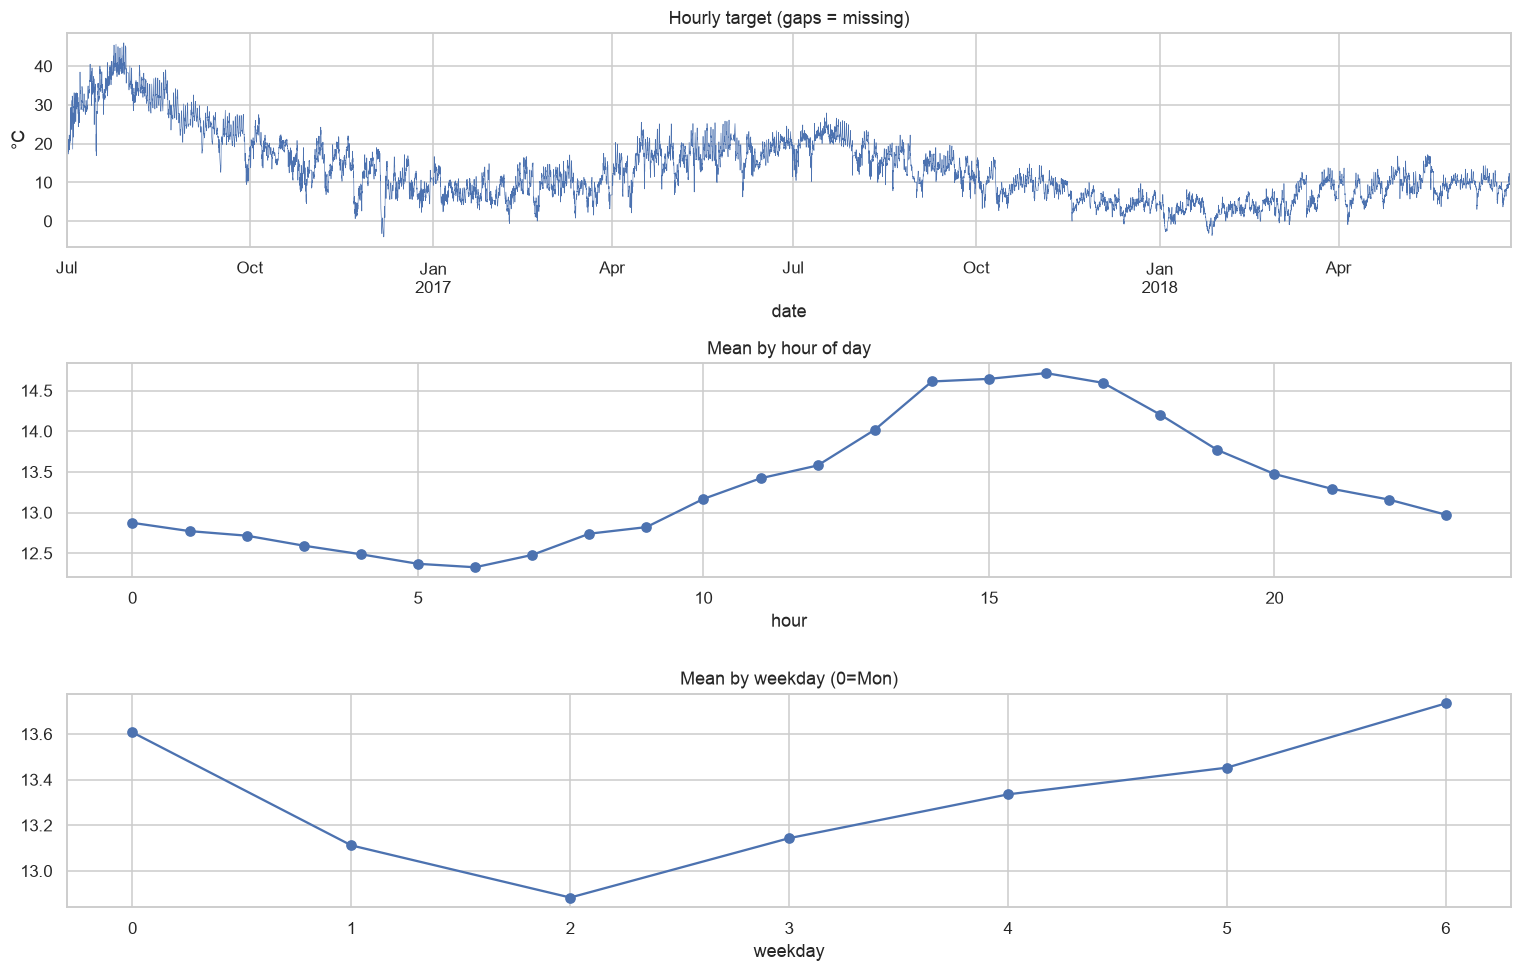


Correlation with target — SAME hour (used by old notebook = leakage) vs PREVIOUS hour (legitimate):


,corr_same_hour,corr_previous_hour
covariate,,
HUFL,0.060,0.046
HULL,0.224,0.231
MUFL,0.051,0.036
MULL,0.220,0.226
LUFL,0.119,0.119
LULL,0.067,0.070


Autocorrelation of the target itself: lag-1 = 0.994 | lag-24 = 0.941 | lag-168 = 0.870


In [6]:
# ============================================================
# CELL 5 — Data quality + EDA  (incl. direct evidence of the old leakage)
# ============================================================
def savefig(name):
    plt.savefig(OUT / 'figs' / f'{DS_NAME}_{name}.png', dpi=150, bbox_inches='tight')

_df = DS['df']; _y = _df['y']
# --- missing-data gaps ---
_miss = _y.isna().astype(int)
_grp = (_miss.diff().fillna(0) != 0).cumsum()
_gaps = _miss.groupby(_grp).agg(['first', 'size'])
_gaps = _gaps[_gaps['first'] == 1]['size']
print(f"Missing blocks: {len(_gaps)} | longest gap: {int(_gaps.max()) if len(_gaps) else 0} h | total missing: {int(_miss.sum())} h")

fig, ax = plt.subplots(3, 1, figsize=(14, 9))
_y.plot(ax=ax[0], lw=.4); ax[0].set_title('Hourly target (gaps = missing)'); ax[0].set_ylabel(UNIT)
_y.groupby(_y.index.hour).mean().plot(ax=ax[1], marker='o'); ax[1].set_title('Mean by hour of day'); ax[1].set_xlabel('hour')
_y.groupby(_y.index.dayofweek).mean().plot(ax=ax[2], marker='o'); ax[2].set_title('Mean by weekday (0=Mon)'); ax[2].set_xlabel('weekday')
plt.tight_layout(); savefig('eda_overview'); plt.show()

# --- leakage evidence: how well do covariates explain the target? ---
if DS['covariates']:
    rows = []
    for c in DS['covariates']:
        rows.append(dict(covariate=c,
                         corr_same_hour=_y.corr(_df[c]),
                         corr_previous_hour=_y.corr(_df[c].shift(1))))
    lk = pd.DataFrame(rows).set_index('covariate').round(3)
    print("\nCorrelation with target — SAME hour (used by old notebook = leakage) vs PREVIOUS hour (legitimate):")
    display(lk)
    print("Autocorrelation of the target itself: lag-1 = %.3f | lag-24 = %.3f | lag-168 = %.3f"
          % (_y.autocorr(1), _y.autocorr(24), _y.autocorr(168)))

In [7]:
# ============================================================
# CELL 6 — Leakage-safe data bundle
#   * train/val/test = 70/10/20 chronological (by TARGET time)
#   * imputation is causal (forward-fill); leading NaNs use train median
#   * covariate clipping + all scalers fit on TRAIN only; target is NOT clipped
#   * loss/metrics are masked to hours where the target was really observed
#   Setting A: inputs = past target + past covariates + calendar (known in advance)
#   Setting B: additionally the covariates AT the target hours (old, leaky setup — reference only)
# ============================================================
def calendar_features(idx, country=None):
    h = idx.hour.values; dow = idx.dayofweek.values; doy = idx.dayofyear.values
    cols = [np.sin(2*np.pi*h/24), np.cos(2*np.pi*h/24),
            np.sin(2*np.pi*dow/7), np.cos(2*np.pi*dow/7),
            np.sin(2*np.pi*doy/365.25), np.cos(2*np.pi*doy/365.25),
            (dow >= 5).astype(float)]
    if country and AVAILABLE.get('holidays'):
        try:
            hol = holidays.country_holidays(country, years=range(idx.year.min(), idx.year.max() + 1))
            cols.append(np.array([d in hol for d in idx.date], dtype=float))
        except Exception:
            pass
    return np.column_stack(cols).astype(np.float32)

class Bundle:
    pass

def build_bundle(ds, setting, max_hours=None):
    b = Bundle()
    df = ds['df'].copy()
    if max_hours: df = df.iloc[-max_hours:]
    b.setting, b.idx, b.T = setting, df.index, len(df)
    b.n_tr, b.n_val = int(0.7 * b.T), int(0.1 * b.T)
    b.n_te = b.T - b.n_tr - b.n_val
    covs = ds['covariates']; b.cov_names = covs; C = len(covs)

    b.y_raw = df['y'].values.astype(float)                # NaN where missing
    b.obs = ~np.isnan(b.y_raw)                            # observed-target mask
    dfi = df.ffill()                                      # causal imputation
    dfi = dfi.fillna(dfi.iloc[:b.n_tr].median())          # leading NaNs → train median
    b.y_imp = dfi['y'].values.astype(float)               # kWh, imputed (used for lags / FM context)
    cov = dfi[covs].values.astype(float) if C else np.zeros((b.T, 0))
    if C:                                                 # clip covariates on TRAIN quantiles
        lo, hi = np.quantile(cov[:b.n_tr], 0.005, axis=0), np.quantile(cov[:b.n_tr], 0.995, axis=0)
        cov = np.clip(cov, lo, hi)
    b.cov_imp = cov
    b.y_mu = float(np.nanmean(b.y_raw[:b.n_tr])); b.y_sd = float(np.nanstd(b.y_raw[:b.n_tr]))
    b.y_s = ((b.y_imp - b.y_mu) / b.y_sd).astype(np.float32)
    if C:
        c_mu, c_sd = cov[:b.n_tr].mean(0), cov[:b.n_tr].std(0) + 1e-8
        b.cov_s = ((cov - c_mu) / c_sd).astype(np.float32)
    else:
        b.cov_s = np.zeros((b.T, 0), np.float32)
    b.cal = calendar_features(b.idx, ds.get('holiday_country'))
    b.feat_past = np.column_stack([b.y_s, b.cov_s, b.cal]).astype(np.float32)      # channel 0 = target
    # covariates available for the forecast hours: ALL of them in Setting B; in Setting A only those declared known-in-advance
    # by the dataset loader (e.g. weather forecasts) -- never a quantity that is only measured during the target hour
    kf = set(ds.get('known_future', []))
    b.fut_cov_idx = list(range(C)) if setting == 'B' else [i for i, c in enumerate(covs) if c in kf]
    b.fut = np.column_stack([b.cal, b.cov_s[:, b.fut_cov_idx]]).astype(np.float32)
    ref = ds.get('reference_forecast')                                   # e.g. the grid operator's own day-ahead forecast
    b.ref = None if ref is None else pd.Series(ref.reindex(df.index).values).ffill().bfill().values.astype(float)
    te0 = b.n_tr + b.n_val
    b.mean_load = float(np.nanmean(b.y_raw[te0:]))                                 # for NRMSE / NMAE
    tr_y = b.y_raw[:b.n_tr]; d = np.abs(tr_y[24:] - tr_y[:-24]); b.mase_scale = float(np.nanmean(d))
    b._torch = None
    return b

def _to_torch(b, device):
    if b._torch is None or b._torch['device'] != device:
        b._torch = dict(device=device,
                        feat=torch.as_tensor(b.feat_past, device=device),
                        fut=torch.as_tensor(b.fut, device=device),
                        y=torch.as_tensor(b.y_s, device=device),
                        obs=torch.as_tensor(b.obs.astype(np.float32), device=device))
    return b._torch
Bundle.torch = lambda self, device=None: _to_torch(self, device or DEVICE)

def get_origins(b, split, L, H):
    """Forecast origins t (last observed hour). Targets are y[t+1..t+H] and always lie inside the split.
    `split` may be a name ('train'/'val'/'trainval'/'test') or an explicit (start, end) index range
    (used by rolling-origin CV below, so fold windows reuse exactly the same origin logic)."""
    if isinstance(split, tuple):
        a, e = split
    else:
        a, e = {'train': (0, b.n_tr), 'val': (b.n_tr, b.n_tr + b.n_val),
                'trainval': (0, b.n_tr + b.n_val), 'test': (b.n_tr + b.n_val, b.T)}[split]
    lo, hi = max(a - 1, L - 1), e - H - 1
    return np.arange(lo, hi + 1)

def cv_folds(b, n_folds):
    """Rolling-origin folds carved out of train+val (test is never touched by tuning).
    Fold 0 is the most recent window and exactly matches the plain train/val split used elsewhere,
    so n_folds=1 reproduces the original single-split behaviour; n_folds>1 gives true rolling CV
    (walk the validation window backwards in time, always training on everything before it)."""
    end = b.n_tr + b.n_val; val_w = max(b.n_val, 1); folds = []
    for k in range(n_folds):
        ve = end - k * val_w; vs = ve - val_w; te = vs
        if te < max(2 * val_w, 200): break        # require a reasonably sized training window
        folds.append((0, te, vs, ve))
    return folds or [(0, b.n_tr, b.n_tr, end)]

def targets(b, origins, H):
    idx = origins[:, None] + np.arange(1, H + 1)
    return b.y_raw[idx], b.obs[idx]            # (N,H) kWh with NaN where missing, and observed mask

def gather(T, o, L, H):
    dev = o.device
    ap = torch.arange(-L + 1, 1, device=dev); af = torch.arange(1, H + 1, device=dev)
    xp = T['feat'][o[:, None] + ap]; ip = o[:, None] + af
    return xp, T['fut'][ip], T['y'][ip], T['obs'][ip]

BUNDLES = {}
def get_bundle(setting):
    k = (DS_NAME, setting)                                               # keyed by dataset: safe to switch DATASET in one kernel
    if k not in BUNDLES:
        BUNDLES[k] = build_bundle(DS, setting, M['max_hours'])
    return BUNDLES[k]

b0 = get_bundle('A')
print(f"Hours used: {b0.T} | train {b0.n_tr} | val {b0.n_val} | test {b0.n_te}")
print(f"Test period: {b0.idx[b0.n_tr+b0.n_val]} → {b0.idx[-1]} | mean test load = {b0.mean_load:.3f}")
print(f"Past channels: 1 target + {len(b0.cov_names)} covariates + {b0.cal.shape[1]} calendar = {b0.feat_past.shape[1]} | "
      f"known-future channels in Setting A: {b0.fut.shape[1]} ({b0.fut.shape[1]-b0.cal.shape[1]} covariates known in advance)")

Hours used: 17420 | train 12194 | val 1742 | test 3484
Test period: 2018-02-01 16:00:00 → 2018-06-26 19:00:00 | mean test load = 7.721
Past channels: 1 target + 6 covariates + 7 calendar = 14 | known-future channels in Setting A: 7 (0 covariates known in advance)


In [8]:
# ============================================================
# CELL 7 — Metrics, result store, finalize()
# ============================================================
def masked_metrics(yt, yp, mask, mean_load, mase_scale):
    m = mask & np.isfinite(yp)
    e = (yp - yt)[m]; t = yt[m]
    rmse = float(np.sqrt(np.mean(e**2))); mae = float(np.mean(np.abs(e)))
    sst = float(np.sum((t - t.mean())**2))
    return dict(RMSE=rmse, MAE=mae, NRMSE=100*rmse/mean_load, NMAE=100*mae/mean_load,
                sMAPE=float(200*np.mean(np.abs(e)/(np.abs(t)+np.abs(yp[m])+1e-8))),
                MASE=mae/mase_scale, R2=1 - float(np.sum(e**2))/sst)

def quantile_metrics(yt, q, mask, taus=(0.1, 0.5, 0.9)):
    m = mask; pin = []
    for j, tau in enumerate(taus):
        d = (yt - q[..., j])[m]; pin.append(np.mean(np.maximum(tau*d, (tau-1)*d)))
    inside = ((yt >= q[..., 0]) & (yt <= q[..., -1]))[m]
    return dict(Pinball=float(np.mean(pin)), PICP80=float(100*inside.mean()), Width80=float(np.mean((q[..., -1]-q[..., 0])[m])))

RES_PATH = OUT / 'results.csv'
RESULTS = pd.read_csv(RES_PATH) if RES_PATH.exists() else pd.DataFrame()
FAILED = []

def safe(s): return ''.join(ch if ch.isalnum() or ch in '-_.' else '_' for ch in s)
def make_key(setting, H, model): return f"{DS_NAME}|{setting}|H{H}|{model}"
def pred_path(key): return OUT / 'preds' / (safe(key) + '.npz')

def is_done(key):
    if CFG['FORCE_RERUN'] or RESULTS.empty: return False
    return (key in set(RESULTS['key'])) and pred_path(key).exists()

def finalize(name, family, b, H, key, out):
    """Turn a model output dict (predictions in kWh) into a results row + saved predictions."""
    global RESULTS
    ov, ot = get_origins(b, 'val', 1, H), get_origins(b, 'test', 1, H)
    yv, mv = targets(b, ov, H); yt, mt = targets(b, ot, H)
    per_seed = [masked_metrics(yt, p, mt, b.mean_load, b.mase_scale) for p in out['pred_test_seeds']]
    row = {k: float(np.mean([s[k] for s in per_seed])) for k in per_seed[0]}
    row['RMSE_std'] = float(np.std([s['RMSE'] for s in per_seed]))
    row['val_RMSE'] = masked_metrics(yv, out['pred_val'], mv, b.mean_load, b.mase_scale)['RMSE']
    pt_mean = np.mean(out['pred_test_seeds'], axis=0)
    if out.get('q_test') is not None: row.update(quantile_metrics(yt, out['q_test'], mt))
    row.update(dict(key=key, dataset=DS_NAME, setting=b.setting, horizon=H, model=name, family=family,
                    n_seeds=len(out['pred_test_seeds']), train_time_s=out.get('train_time', np.nan),
                    infer_ms_per_1k=out.get('infer_ms', np.nan), n_params=out.get('n_params', np.nan),
                    best_params=json.dumps(out.get('best_params', {}), default=str), run_mode=CFG['RUN_MODE']))
    np.savez_compressed(pred_path(key), val=out['pred_val'], test=pt_mean,
                        test_seeds=np.array(out['pred_test_seeds']),
                        q_test=out['q_test'] if out.get('q_test') is not None else np.zeros(0))
    RESULTS = pd.concat([RESULTS[RESULTS['key'] != key] if not RESULTS.empty else RESULTS, pd.DataFrame([row])], ignore_index=True)
    RESULTS.to_csv(RES_PATH, index=False)
    print(f"   ✓ {name:<20} H={H:<3} RMSE={row['RMSE']:.4f}  MAE={row['MAE']:.4f}  NRMSE={row['NRMSE']:.2f}%  "
          f"MASE={row['MASE']:.3f}  (val RMSE {row['val_RMSE']:.4f})")
    return row

# ---- Optuna helper ----------------------------------------------------------------
def suggest_from(trial, spec):
    p = {}
    for k, v in spec.items():
        if   v[0] == 'cat':   p[k] = trial.suggest_categorical(k, v[1])
        elif v[0] == 'float': p[k] = trial.suggest_float(k, v[1], v[2], log=v[3])
        elif v[0] == 'int':   p[k] = trial.suggest_int(k, v[1], v[2])
    return p

def tune(key, spec, default, objective, n_trials):
    """Generic Optuna tuner. objective(params, trial)->val loss. Saves trials CSV + best params JSON (resumable)."""
    path = OUT / 'tuning' / (safe(key) + '.json')
    if path.exists() and not CFG['FORCE_RERUN']:
        return json.load(open(path))
    study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=3))
    study.enqueue_trial(default)                       # a sensible default is always trial 0
    def _obj(trial): return objective(suggest_from(trial, spec), trial)
    study.optimize(_obj, n_trials=n_trials, timeout=M['tune_timeout_min'] * 60, gc_after_trial=True)
    done = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
    best = dict(params=(study.best_trial.params if done else default),
                value=(study.best_value if done else None), n_trials=len(study.trials), n_complete=len(done))
    try: study.trials_dataframe().to_csv(OUT / 'tuning' / (safe(key) + '_trials.csv'), index=False)
    except Exception: pass
    json.dump(best, open(path, 'w'), default=str)
    return best

print("Metrics + result store ready. Existing results loaded:", 0 if RESULTS.empty else len(RESULTS))


# ---- Crash recovery: if the kernel dies, the next run knows which model was running ----------------------------
# Before each model (and each device probe) a small marker file is written; it is deleted when the step ends.
# If the marker is still there on restart, the kernel died inside that step:
#   * neural net on the Apple/NVIDIA GPU  -> retried on CPU from now on
#   * Chronos on GPU                      -> Chronos uses CPU from now on
#   * anything else (or it died on CPU)   -> that model/horizon is skipped (delete state/skip.json to retry)
STATE = OUT / 'state'; STATE.mkdir(exist_ok=True)
def _jload(p, default):
    try: return json.load(open(p))
    except Exception: return default
def _jsave(p, obj): json.dump(obj, open(p, 'w'))
CPU_ONLY = set(_jload(STATE / 'cpu_only.json', []))
SKIPPED = _jload(STATE / 'skip.json', {})
if (STATE / 'fm_cpu.flag').exists(): CFG['FM_DEVICE'] = 'cpu'
def mark_start(**kw): _jsave(STATE / '_marker.json', kw)
def mark_end():
    try: (STATE / '_marker.json').unlink()
    except FileNotFoundError: pass
def recover_from_crash():
    mk = STATE / '_marker.json'
    if not mk.exists(): return
    info = _jload(mk, {}); mk.unlink()
    kind, model, dev = info.get('kind'), info.get('model', '?'), info.get('device', 'cpu')
    print(f"CRASH RECOVERY: the kernel died last time while {'probing' if kind == 'probe' else 'running'} '{model}' on '{dev}'.")
    if kind == 'probe' or (model in NN_CLASSES and dev != 'cpu'):
        CPU_ONLY.add(model); _jsave(STATE / 'cpu_only.json', sorted(CPU_ONLY)); print(f"   -> '{model}' will run on CPU from now on.")
    elif model.startswith('Chronos') and dev != 'cpu':
        (STATE / 'fm_cpu.flag').write_text('1'); CFG['FM_DEVICE'] = 'cpu'; print("   -> Chronos will use the CPU from now on.")
    else:
        k = info.get('key', model); SKIPPED[k] = f"kernel crashed while running on {dev}"; _jsave(STATE / 'skip.json', SKIPPED)
        print(f"   -> '{k}' will be skipped. Delete {STATE / 'skip.json'} to retry it.")

Metrics + result store ready. Existing results loaded: 58


In [9]:
# ============================================================
# CELL 8 — Baselines + tabular features + ML models (Ridge, XGBoost, LightGBM, CatBoost, RF, ExtraTrees)
# All runners return predictions in kWh:
#   dict(pred_val (Nv,H), pred_test_seeds [(Nt,H),...], train_time, infer_ms, n_params, best_params)
# ============================================================
# ---------------- naive baselines ----------------
def run_seasonal(period):
    def fn(name, b, H, key):
        def pred(split):
            o = get_origins(b, split, 1, H); h = np.arange(1, H + 1)
            lag = period * np.ceil(h / period).astype(int)         # most recent same-phase hour already observed
            return b.y_imp[o[:, None] + h[None, :] - lag[None, :]]
        t0 = time.time(); pv, pt = pred('val'), pred('test')
        return dict(pred_val=pv, pred_test_seeds=[pt], train_time=0.0, infer_ms=1e6*(time.time()-t0)/max(len(pt),1),
                    n_params=0, best_params={'period': period})
    return fn

def run_reference(name, b, H, key):
    """Forecast published by the data owner (e.g. the grid operator's day-ahead forecast) used as a reference baseline."""
    ar = np.arange(1, H + 1); pred = lambda split: b.ref[get_origins(b, split, 1, H)[:, None] + ar]
    return dict(pred_val=pred('val'), pred_test_seeds=[pred('test')], train_time=0.0, infer_ms=0.0, n_params=0,
                best_params={'source': 'operator forecast shipped with the dataset'})

# ---------------- tabular features ----------------
LAGS = list(range(24)) + [47, 71, 95, 143, 167]
CAL_NAMES = ['sin_hour', 'cos_hour', 'sin_dow', 'cos_dow', 'sin_doy', 'cos_doy', 'weekend', 'holiday']

class TabData:
    """Builds lag/rolling/calendar/covariate features for a set of forecast origins.
    Named splits ('train','val','trainval','test') are built eagerly; `add_range` builds and
    caches features for an arbitrary extra origin array on demand — used by rolling-origin CV
    (Cell 7b) so each fold's train/val window reuses exactly the same feature logic, computed once
    and shared across every Optuna trial (features don't depend on model hyperparameters)."""
    def __init__(s, b, H):
        s.b, s.H, s.d = b, H, {}
        y = b.y_s; s.C = b.cov_s.shape[1]
        s.cs, s.cs2 = np.cumsum(np.r_[0, y]), np.cumsum(np.r_[0, y**2])
        s.ar = np.arange(1, H + 1)
        s.names = [f'lag_{k}' for k in LAGS] + [f'rmean_{w}' for w in (6, 24, 168)] + ['rstd_24']
        s.names += [f'cal_{n}@t' for n in CAL_NAMES[:b.cal.shape[1]]]
        s.names += [f'{c}@t' for c in b.cov_names] + [f'{c}@t-1' for c in b.cov_names] + [f'{c}@t-23' for c in b.cov_names]
        s.fut_names = [f'fut_{n}' for n in CAL_NAMES[:b.cal.shape[1]]] + [f'fut_{b.cov_names[i]}' for i in b.fut_cov_idx]
        for split in ['train', 'val', 'trainval', 'test']:
            s.d[split] = s._features(get_origins(b, split, 168, H))

    def _features(s, o):
        b, y, C = s.b, s.b.y_s, s.C
        cols = [y[o - k] for k in LAGS]
        cols += [(s.cs[o + 1] - s.cs[o + 1 - w]) / w for w in (6, 24, 168)]
        m24 = (s.cs[o + 1] - s.cs[o - 23]) / 24; v = (s.cs2[o + 1] - s.cs2[o - 23]) / 24 - m24**2
        cols.append(np.sqrt(np.maximum(v, 0)))
        base = np.column_stack(cols + [b.cal[o][:, j] for j in range(b.cal.shape[1])])
        if C: base = np.column_stack([base, b.cov_s[o], b.cov_s[o - 1], b.cov_s[o - 23]])
        idx = o[:, None] + s.ar
        return dict(base=base.astype(np.float32), fut=b.fut[idx], Y=y[idx], M=b.obs[idx], o=o)

    def add_range(s, name, o):
        if name not in s.d: s.d[name] = s._features(o)
        return name

    def Xh(s, split, h):   d = s.d[split]; return np.hstack([d['base'], d['fut'][:, h - 1, :]])
    def Xflat(s, split):   d = s.d[split]; return np.hstack([d['base'], d['fut'].reshape(len(d['base']), -1)])
    def Y(s, split):       return s.d[split]['Y']
    def M(s, split):       return s.d[split]['M']
    def n(s, split):       return len(s.d[split]['base'])

TABS = {}
def get_tab(b, H):
    k = (DS_NAME, b.setting, H)
    if k not in TABS: TABS[k] = TabData(b, H)
    return TABS[k]

FOLD_CACHE = {}
def get_fold_splits(b, H):
    """Rolling-origin CV folds inside train+val, as (train_name, val_name) pairs registered on
    this (setting,H)'s TabData under 'cv{k}_tr' / 'cv{k}_va'. M['cv_folds']=1 reproduces the plain
    train/val split (fold 0 IS that split); SMOKE/STANDARD default to 1 fold, FULL to 3 (see Cell 2)."""
    key = (DS_NAME, b.setting, H)
    if key not in FOLD_CACHE:
        tab = get_tab(b, H); names = []
        for k, (ts, te, vs, ve) in enumerate(cv_folds(b, M['cv_folds'])):
            tr_name = tab.add_range(f'cv{k}_tr', get_origins(b, (ts, te), 168, H))
            va_name = tab.add_range(f'cv{k}_va', get_origins(b, (vs, ve), 168, H))
            names.append((tr_name, va_name))
        FOLD_CACHE[key] = names
    return FOLD_CACHE[key]

def to_kwh(b, p): return p * b.y_sd + b.y_mu
def rmse_masked(p, y, m):
    p = np.asarray(p).reshape(np.shape(y)); return float(np.sqrt(np.mean((p - y)[m]**2)))
def pred2d(model, X): return np.asarray(model.predict(X)).reshape(len(X), -1)

# ---------------- GBMs (one model per horizon step, "direct" strategy) ----------------
def gbm_specs(name):
    cap = M['n_est_cap'] if name != 'CatBoost' else min(M['n_est_cap'], 800)
    lo = min(50, cap); nd = min(300, cap)
    if name == 'XGBoost':
        spec = dict(n_estimators=('int', lo, cap), max_depth=('int', 3, 12), lr=('float', 0.01, 0.3, True),
                    subsample=('float', 0.5, 1.0, False), colsample=('float', 0.5, 1.0, False),
                    min_child_weight=('int', 1, 20), reg_alpha=('float', 1e-8, 10, True), reg_lambda=('float', 1e-3, 10, True))
        dflt = dict(n_estimators=nd, max_depth=6, lr=0.05, subsample=0.8, colsample=0.8, min_child_weight=1, reg_alpha=1e-8, reg_lambda=1.0)
    elif name == 'LightGBM':
        spec = dict(n_estimators=('int', lo, cap), num_leaves=('int', 15, 255), lr=('float', 0.01, 0.3, True),
                    subsample=('float', 0.5, 1.0, False), colsample=('float', 0.5, 1.0, False),
                    min_child_samples=('int', 5, 100), reg_alpha=('float', 1e-8, 10, True), reg_lambda=('float', 1e-3, 10, True))
        dflt = dict(n_estimators=nd, num_leaves=31, lr=0.05, subsample=0.8, colsample=0.8, min_child_samples=20, reg_alpha=1e-8, reg_lambda=1.0)
    else:  # CatBoost
        spec = dict(n_estimators=('int', lo, cap), depth=('int', 4, 10), lr=('float', 0.01, 0.3, True), l2_leaf_reg=('float', 1, 20, True))
        dflt = dict(n_estimators=nd, depth=6, lr=0.05, l2_leaf_reg=3.0)
    return spec, dflt

def gbm_make(name, p, seed):
    if name == 'XGBoost':
        return XGBRegressor(n_estimators=p['n_estimators'], max_depth=p['max_depth'], learning_rate=p['lr'], subsample=p['subsample'],
                            colsample_bytree=p['colsample'], min_child_weight=p['min_child_weight'], reg_alpha=p['reg_alpha'],
                            reg_lambda=p['reg_lambda'], tree_method='hist', n_jobs=-1, random_state=seed, verbosity=0)
    if name == 'LightGBM':
        return LGBMRegressor(n_estimators=p['n_estimators'], num_leaves=p['num_leaves'], learning_rate=p['lr'], subsample=p['subsample'],
                             subsample_freq=1, colsample_bytree=p['colsample'], min_child_samples=p['min_child_samples'],
                             reg_alpha=p['reg_alpha'], reg_lambda=p['reg_lambda'], n_jobs=-1, random_state=seed, verbose=-1)
    return CatBoostRegressor(iterations=p['n_estimators'], depth=p['depth'], learning_rate=p['lr'], l2_leaf_reg=p['l2_leaf_reg'],
                             random_seed=seed, verbose=0, thread_count=-1, allow_writing_files=False)

def gbm_fit_predict(name, p, td, H, fit_split, pred_splits, seed, want_imp=False):
    preds = {s: np.zeros((td.n(s), H)) for s in pred_splits}; imp = None
    for h in range(1, H + 1):
        X, y, m = td.Xh(fit_split, h), td.Y(fit_split)[:, h - 1], td.M(fit_split)[:, h - 1]
        mdl = gbm_make(name, p, seed); mdl.fit(X[m], y[m])
        for s in pred_splits: preds[s][:, h - 1] = mdl.predict(td.Xh(s, h))
        if h == 1 and want_imp and hasattr(mdl, 'feature_importances_'):
            imp = pd.DataFrame({'feature': td.names + td.fut_names, 'importance': np.asarray(mdl.feature_importances_, float)})
    return preds, imp

def run_gbm(name, b, H, key):
    td = get_tab(b, H); spec, dflt = gbm_specs(name); steps = sorted({1, H}); folds = get_fold_splits(b, H)
    def obj(p, trial):
        errs = []
        for tr_s, va_s in folds:                         # rolling-origin CV (M['cv_folds'] windows)
            for h in steps:
                m = td.M(tr_s)[:, h - 1]
                mdl = gbm_make(name, p, 0); mdl.fit(td.Xh(tr_s, h)[m], td.Y(tr_s)[:, h - 1][m])
                errs.append(rmse_masked(mdl.predict(td.Xh(va_s, h)), td.Y(va_s)[:, h - 1], td.M(va_s)[:, h - 1]))
        return float(np.mean(errs))
    best = tune(key, spec, dflt, obj, M['trials_gbm']); p = best['params']
    t0 = time.time()
    refit = CFG['REFIT_TRAINVAL']
    pr, imp0 = gbm_fit_predict(name, p, td, H, 'train', ['val'] + ([] if refit else ['test']), 0, want_imp=not refit)
    train_time = time.time() - t0
    pv = to_kwh(b, pr['val']); tests = []; imp = imp0
    for s in M['seeds']:
        if refit:
            pt, imp_s = gbm_fit_predict(name, p, td, H, 'trainval', ['test'], s, want_imp=(s == M['seeds'][0]))
            if imp_s is not None: imp = imp_s
            tests.append(to_kwh(b, pt['test']))
        else:
            tests.append(to_kwh(b, pr['test']))
    if imp is not None: imp.to_csv(OUT / 'artifacts' / (safe(key) + '_importance.csv'), index=False)
    return dict(pred_val=pv, pred_test_seeds=tests, train_time=train_time,
                infer_ms=np.nan, n_params=np.nan, best_params=p)

# ---------------- multi-output: Ridge / RandomForest / ExtraTrees ----------------
def run_ridge(name, b, H, key):
    td = get_tab(b, H); Xtr, Ytr = td.Xflat('train'), td.Y('train'); ok = td.M('train').all(1)
    Xv, Yv, mv = td.Xflat('val'), td.Y('val'), td.M('val')
    folds = get_fold_splits(b, H)
    best_a, best_e = None, 1e18
    for a in np.logspace(-3, 3, 13):
        es = []
        for tr_s, va_s in folds:
            ok_f = td.M(tr_s).all(1)
            es.append(rmse_masked(pred2d(Ridge(alpha=a).fit(td.Xflat(tr_s)[ok_f], td.Y(tr_s)[ok_f]), td.Xflat(va_s)), td.Y(va_s), td.M(va_s)))
        e = float(np.mean(es))
        if e < best_e: best_a, best_e = a, e
    t0 = time.time(); m1 = Ridge(alpha=best_a).fit(Xtr[ok], Ytr[ok]); train_time = time.time() - t0
    pv = to_kwh(b, pred2d(m1, Xv))
    if CFG['REFIT_TRAINVAL']:
        okv = td.M('trainval').all(1); m2 = Ridge(alpha=best_a).fit(td.Xflat('trainval')[okv], td.Y('trainval')[okv])
    else: m2 = m1
    pt = to_kwh(b, pred2d(m2, td.Xflat('test')))
    return dict(pred_val=pv, pred_test_seeds=[pt], train_time=train_time, infer_ms=np.nan,
                n_params=int(m1.coef_.size), best_params={'alpha': float(best_a)})

def run_forest(name, b, H, key):
    Cls = RandomForestRegressor if name == 'RandomForest' else ExtraTreesRegressor
    hi = min(M['n_est_cap'], 300); lo = min(50, hi)
    spec = dict(n_estimators=('int', lo, hi), max_depth=('int', 6, 30), min_samples_leaf=('int', 1, 10), max_features=('float', 0.3, 1.0, False))
    dflt = dict(n_estimators=min(100, hi), max_depth=20, min_samples_leaf=2, max_features=0.6)
    td = get_tab(b, H); ok = td.M('train').all(1); folds = get_fold_splits(b, H)
    mk = lambda p, s: Cls(n_estimators=p['n_estimators'], max_depth=p['max_depth'], min_samples_leaf=p['min_samples_leaf'],
                          max_features=p['max_features'], n_jobs=-1, random_state=s)
    def obj(p, trial):
        errs = []
        for tr_s, va_s in folds:                          # rolling-origin CV
            ok_f = td.M(tr_s).all(1)
            m = mk(p, 0).fit(td.Xflat(tr_s)[ok_f], td.Y(tr_s)[ok_f])
            errs.append(rmse_masked(pred2d(m, td.Xflat(va_s)), td.Y(va_s), td.M(va_s)))
        return float(np.mean(errs))
    best = tune(key, spec, dflt, obj, M['trials_gbm']); p = best['params']
    t0 = time.time(); m1 = mk(p, 0).fit(td.Xflat('train')[ok], td.Y('train')[ok]); train_time = time.time() - t0
    pv = to_kwh(b, pred2d(m1, td.Xflat('val'))); tests = []
    for s in M['seeds']:
        if CFG['REFIT_TRAINVAL']:
            okv = td.M('trainval').all(1); m2 = mk(p, s).fit(td.Xflat('trainval')[okv], td.Y('trainval')[okv])
        else: m2 = m1
        tests.append(to_kwh(b, pred2d(m2, td.Xflat('test'))))
    return dict(pred_val=pv, pred_test_seeds=tests, train_time=train_time, infer_ms=np.nan, n_params=np.nan, best_params=p)
print("Baselines + ML runners defined.")

Baselines + ML runners defined.


In [10]:
# ============================================================
# CELL 8b — Prophet (baseline). Setting A: seasonality only (no future covariates exist).
#            Setting B: the 6 electrical regressors, exactly like the old notebook.
# Prophet does not use recent history, so it is fitted once per setting and reused for every horizon.
# ============================================================
def _yearly(full, train_end):
    """Prophet's 'auto' switches yearly seasonality OFF below 2 years of data. With >= 300 days it can be fitted, and leaving
    it off makes Prophet blind to the season (that is why it scored ~26% NRMSE on PJM in LITE mode). Same rule for every fit."""
    return bool((full['ds'].iloc[train_end - 1] - full['ds'].iloc[0]).days >= 300)

def _prophet_regs(b):
    """Regressors Prophet may use: covariates known for the forecast hours (all of them in Setting B; known-in-advance ones in A)."""
    return [b.cov_names[i] for i in b.fut_cov_idx]

PROPHET_CACHE = {}
def run_prophet(name, b, H, key):
    if (DS_NAME, b.setting) not in PROPHET_CACHE:
        regs = _prophet_regs(b); use_reg = len(regs) > 0
        full = pd.DataFrame({'ds': b.idx.tz_localize(None) if b.idx.tz is not None else b.idx, 'y': b.y_raw})
        for j, c in enumerate(b.cov_names): full[c] = b.cov_imp[:, j]
        def fit_pred(train_end, pred_from, params):
            m = Prophet(daily_seasonality=True, weekly_seasonality=True, yearly_seasonality=_yearly(full, train_end),
                        changepoint_prior_scale=params['cps'], seasonality_mode=params['mode'])
            if use_reg:
                for c in regs: m.add_regressor(c)
            m.fit(full.iloc[:train_end].dropna(subset=['y']))
            out = np.full(b.T, np.nan); out[pred_from:] = m.predict(full.iloc[pred_from:])['yhat'].values
            return out
        spec = dict(cps=('float', 0.005, 0.5, True), mode=('cat', ['additive', 'multiplicative']))
        def obj(p, trial):
            yh = fit_pred(b.n_tr, b.n_tr, p)[b.n_tr:b.n_tr + b.n_val]
            yt, ok = b.y_raw[b.n_tr:b.n_tr + b.n_val], b.obs[b.n_tr:b.n_tr + b.n_val]
            return float(np.sqrt(np.mean((yh - yt)[ok]**2)))
        best = tune(f"{DS_NAME}|{b.setting}|Prophet", spec, dict(cps=0.05, mode='additive'), obj, min(M['trials_gbm'], 4))
        p = best['params']; t0 = time.time()
        yh_val = fit_pred(b.n_tr, b.n_tr, p)
        yh_test = fit_pred(b.n_tr + b.n_val, b.n_tr + b.n_val, p) if CFG['REFIT_TRAINVAL'] else yh_val
        PROPHET_CACHE[(DS_NAME, b.setting)] = (yh_val, yh_test, p, time.time() - t0)
    yh_val, yh_test, p, tt = PROPHET_CACHE[(DS_NAME, b.setting)]
    ar = np.arange(1, H + 1)
    pv = yh_val[get_origins(b, 'val', 1, H)[:, None] + ar]; pt = yh_test[get_origins(b, 'test', 1, H)[:, None] + ar]
    return dict(pred_val=pv, pred_test_seeds=[pt], train_time=tt, infer_ms=np.nan, n_params=np.nan, best_params=p)

# ============================================================
# CELL 8c — Prophet-Anchored (baseline, NEW in v8)
# WHY: plain Prophet only extrapolates the trend + seasonality it learned on the training window; it never looks at recent
#      observations, so after any level shift (new year, new season, demand growth) it is biased. Every other model in
#      this benchmark DOES see recent history, so plain Prophet is compared unfairly (that is why its error is so high).
#      "Anchored" fixes this in the simplest possible way: at each forecast origin t we measure the gap between the
#      Prophet curve and what was actually observed at t, and carry that gap forward with exponential decay:
#            yhat(t+h) = prophet(t+h) + phi^h * ( y(t) - prophet(t) )
#      phi and Prophet's (changepoint_prior_scale, seasonality_mode) are chosen on VALIDATION only (no test leakage).
#      Plain 'Prophet' stays in the tables unchanged (it is the model the original paper used).
# ============================================================
PROPHET_ANCH = {}
_PHI_GRID = [0.0, 0.5, 0.8, 0.9, 0.95, 0.98, 0.995]           # phi=0 reproduces plain Prophet
_PROPHET_GRID = [(c, m) for c in (0.01, 0.05, 0.2) for m in ('additive', 'multiplicative')]

def run_prophet_anchored(name, b, H, key):
    ds_ = b.idx.tz_localize(None) if b.idx.tz is not None else b.idx
    full = pd.DataFrame({'ds': ds_, 'y': b.y_raw}); regs = _prophet_regs(b)
    for c in regs: full[c] = b.cov_imp[:, b.cov_names.index(c)]
    ar = np.arange(1, H + 1)
    t0 = time.time()
    grid = _PROPHET_GRID if b.T <= 30000 else [(0.05, 'additive'), (0.05, 'multiplicative')]   # keep FULL-mode runtime sane

    def curve(train_end, cps, mode):                 # Prophet fitted on [:train_end]; returns its curve over the WHOLE timeline
        ck = (DS_NAME, b.setting, train_end, cps, mode)
        if ck not in PROPHET_ANCH:
            m = Prophet(daily_seasonality=True, weekly_seasonality=True, yearly_seasonality=_yearly(full, train_end),
                        changepoint_prior_scale=cps, seasonality_mode=mode)
            for c in regs: m.add_regressor(c)
            m.fit(full.iloc[:train_end].dropna(subset=['y']))
            PROPHET_ANCH[ck] = m.predict(full[['ds'] + regs])['yhat'].values
        return PROPHET_ANCH[ck]

    def anchored(yh, o, phi):                        # (N, H) forecasts for forecast origins o
        return yh[o[:, None] + ar] + (b.y_imp[o] - yh[o])[:, None] * (phi ** ar)[None, :]

    ov, ot = get_origins(b, 'val', 1, H), get_origins(b, 'test', 1, H)
    yv, mv = targets(b, ov, H)
    best = (np.inf, None, None, None)
    for cps, mode in grid:
        yh = curve(b.n_tr, cps, mode)
        for phi in _PHI_GRID:
            r = float(np.sqrt(np.mean((anchored(yh, ov, phi) - yv)[mv] ** 2)))
            if r < best[0]: best = (r, cps, mode, phi)
    _, cps, mode, phi = best
    pv = anchored(curve(b.n_tr, cps, mode), ov, phi)
    pt = anchored(curve(b.n_tr + b.n_val, cps, mode) if CFG['REFIT_TRAINVAL'] else curve(b.n_tr, cps, mode), ot, phi)
    return dict(pred_val=pv, pred_test_seeds=[pt], train_time=time.time() - t0, infer_ms=np.nan, n_params=np.nan,
                best_params=dict(cps=cps, mode=mode, phi=phi))

In [11]:
# ============================================================
# CELL 9 — Neural architectures (PyTorch)
# Common interface:  net(xp, xf) -> (B, H)
#   xp : (B, L, Fp)  past window; channel 0 = scaled target, then covariates, then calendar
#   xf : (B, H, Kf)  features known for the forecast hours (calendar; + covariates in Setting B)
# Every network is wrapped in `Skip`, which adds the last observed target value to the output
# (the network learns the *change* from persistence — makes all models train faster and more stably).
# ============================================================
class Head(nn.Module):
    def __init__(s, din, H, hidden, drop):
        super().__init__(); s.net = nn.Sequential(nn.Linear(din, hidden), nn.GELU(), nn.Dropout(drop), nn.Linear(hidden, H))
    def forward(s, x): return s.net(x)

class MLPNet(nn.Module):
    def __init__(s, Fp, Kf, L, H, hp):
        super().__init__(); d, w, layers = L*Fp + H*Kf, hp['width'], []
        for i in range(hp['n_layers']): layers += [nn.Linear(d if i == 0 else w, w), nn.GELU(), nn.Dropout(hp['dropout'])]
        s.net = nn.Sequential(*layers, nn.Linear(w, H))
    def forward(s, xp, xf): return s.net(torch.cat([xp.flatten(1), xf.flatten(1)], 1))

class RNNNet(nn.Module):                                   # LSTM / GRU / BiLSTM
    def __init__(s, Fp, Kf, L, H, hp, kind='lstm', bi=False):
        super().__init__(); R = nn.LSTM if kind == 'lstm' else nn.GRU
        s.rnn = R(Fp, hp['hidden'], hp['layers'], batch_first=True, bidirectional=bi,
                  dropout=hp['dropout'] if hp['layers'] > 1 else 0.0)
        s.head = Head(hp['hidden'] * (2 if bi else 1) + H*Kf, H, hp['hidden'], hp['dropout'])
    def forward(s, xp, xf):
        o, _ = s.rnn(xp); return s.head(torch.cat([o[:, -1], xf.flatten(1)], 1))

class CNNLSTMNet(nn.Module):
    def __init__(s, Fp, Kf, L, H, hp):
        super().__init__(); f, k = hp['filters'], hp['kernel']
        s.conv = nn.Sequential(nn.Conv1d(Fp, f, k, padding=k//2), nn.ReLU(), nn.Conv1d(f, f, k, padding=k//2), nn.ReLU(), nn.MaxPool1d(2))
        s.rnn = nn.LSTM(f, hp['hidden'], batch_first=True); s.head = Head(hp['hidden'] + H*Kf, H, hp['hidden'], hp['dropout'])
    def forward(s, xp, xf):
        z = s.conv(xp.transpose(1, 2)).transpose(1, 2); o, _ = s.rnn(z)
        return s.head(torch.cat([o[:, -1], xf.flatten(1)], 1))

class TCNBlock(nn.Module):
    def __init__(s, ch, k, dil, drop):
        super().__init__(); s.c1 = nn.Conv1d(ch, ch, k, dilation=dil); s.c2 = nn.Conv1d(ch, ch, k, dilation=dil)
        s.pad, s.act, s.drop = (k - 1) * dil, nn.GELU(), nn.Dropout(drop)
    def forward(s, x):
        h = s.drop(s.act(s.c1(F.pad(x, (s.pad, 0))))); h = s.drop(s.act(s.c2(F.pad(h, (s.pad, 0)))))
        return s.act(x + h)

class TCNNet(nn.Module):
    def __init__(s, Fp, Kf, L, H, hp):
        super().__init__(); ch = hp['channels']
        s.inp = nn.Conv1d(Fp, ch, 1)
        s.blocks = nn.Sequential(*[TCNBlock(ch, hp['kernel'], 2**i, hp['dropout']) for i in range(hp['levels'])])
        s.head = Head(ch + H*Kf, H, ch * 2, hp['dropout'])
    def forward(s, xp, xf):
        z = s.blocks(s.inp(xp.transpose(1, 2)))[:, :, -1]; return s.head(torch.cat([z, xf.flatten(1)], 1))

class NBeatsBlock(nn.Module):
    def __init__(s, din, H, width, layers, drop):
        super().__init__(); mods, d = [], din
        for _ in range(layers): mods += [nn.Linear(d, width), nn.ReLU(), nn.Dropout(drop)]; d = width
        s.fc = nn.Sequential(*mods); s.back = nn.Linear(width, din); s.fore = nn.Linear(width, H)
    def forward(s, x): h = s.fc(x); return s.back(h), s.fore(h)

class NBeatsNet(nn.Module):                                # generic N-BEATS with known-future exogenous inputs
    def __init__(s, Fp, Kf, L, H, hp):
        super().__init__(); s.blocks = nn.ModuleList([NBeatsBlock(L + H*Kf, H, hp['width'], hp['layers'], hp['dropout']) for _ in range(hp['blocks'])])
    def forward(s, xp, xf):
        res = torch.cat([xp[..., 0], xf.flatten(1)], 1); f = 0
        for blk in s.blocks: bk, fo = blk(res); res = res - bk; f = f + fo
        return f

class NHiTSBlock(nn.Module):
    def __init__(s, L, H, Kfx, width, layers, pool, freq, drop):
        super().__init__(); s.L, s.H = L, H
        s.pool = nn.MaxPool1d(pool, pool, ceil_mode=True) if pool > 1 else nn.Identity()
        lp = math.ceil(L / pool); s.nf = max(1, math.ceil(H / freq)); mods, d = [], lp + Kfx
        for _ in range(layers): mods += [nn.Linear(d, width), nn.ReLU(), nn.Dropout(drop)]; d = width
        s.fc = nn.Sequential(*mods); s.back = nn.Linear(width, lp); s.fore = nn.Linear(width, s.nf)
    def forward(s, y, ex):
        p = s.pool(y.unsqueeze(1)).squeeze(1) if not isinstance(s.pool, nn.Identity) else y
        h = s.fc(torch.cat([p, ex], 1))
        bk = F.interpolate(s.back(h).unsqueeze(1), size=s.L, mode='linear', align_corners=False).squeeze(1)
        fo = F.interpolate(s.fore(h).unsqueeze(1), size=s.H, mode='linear', align_corners=False).squeeze(1)
        return bk, fo

class NHiTSNet(nn.Module):
    def __init__(s, Fp, Kf, L, H, hp):
        super().__init__(); pools, freqs = [hp['pool1'], hp['pool2'], 1], [max(1, H // 2), max(1, H // 6), 1]
        s.blocks = nn.ModuleList([NHiTSBlock(L, H, H*Kf, hp['width'], hp['layers'], p, f, hp['dropout']) for p, f in zip(pools, freqs)])
    def forward(s, xp, xf):
        res, ex, f = xp[..., 0], xf.flatten(1), 0
        for blk in s.blocks: bk, fo = blk(res, ex); res = res - bk; f = f + fo
        return f

class TransformerNet(nn.Module):                           # vanilla encoder-only Transformer over hourly tokens
    def __init__(s, Fp, Kf, L, H, hp):
        super().__init__(); d = hp['d_model']
        s.inp = nn.Linear(Fp, d); s.pos = nn.Parameter(torch.randn(1, L, d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, hp['heads'], d * hp['ff'], hp['dropout'], batch_first=True, norm_first=True, activation='gelu')
        s.enc = nn.TransformerEncoder(layer, hp['layers'], enable_nested_tensor=False); s.norm = nn.LayerNorm(d)
        s.head = Head(2*d + H*Kf, H, 2*d, hp['dropout'])
    def forward(s, xp, xf):
        z = s.norm(s.enc(s.inp(xp) + s.pos)); return s.head(torch.cat([z[:, -1], z.mean(1), xf.flatten(1)], 1))

class PatchTSTNet(nn.Module):                              # PatchTST-style: patch tokens (all channels per patch) + Transformer
    def __init__(s, Fp, Kf, L, H, hp):
        super().__init__(); d, P = hp['d_model'], hp['patch_len']; S = max(1, P // hp['stride_div'])
        s.P, s.S, s.Np = P, S, (L - P) // S + 1
        s.emb = nn.Linear(P * Fp, d); s.pos = nn.Parameter(torch.randn(1, s.Np, d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, hp['heads'], d * hp['ff'], hp['dropout'], batch_first=True, norm_first=True, activation='gelu')
        s.enc = nn.TransformerEncoder(layer, hp['layers'], enable_nested_tensor=False); s.norm = nn.LayerNorm(d)
        s.drop = nn.Dropout(hp['dropout']); s.out = nn.Linear(s.Np * d + H*Kf, H)
    def forward(s, xp, xf):
        p = xp.unfold(1, s.P, s.S); p = p.reshape(p.shape[0], p.shape[1], -1)
        z = s.norm(s.enc(s.emb(p) + s.pos)); return s.out(torch.cat([s.drop(z.flatten(1)), xf.flatten(1)], 1))

class ITransformerNet(nn.Module):                          # iTransformer-style: each variable's whole history = one token
    def __init__(s, Fp, Kf, L, H, hp):
        super().__init__(); d = hp['d_model']
        s.ep, s.ef = nn.Linear(L, d), nn.Linear(H, d)
        layer = nn.TransformerEncoderLayer(d, hp['heads'], d * hp['ff'], hp['dropout'], batch_first=True, norm_first=True, activation='gelu')
        s.enc = nn.TransformerEncoder(layer, hp['layers'], enable_nested_tensor=False); s.norm = nn.LayerNorm(d); s.out = nn.Linear(d, H)
    def forward(s, xp, xf):
        z = s.norm(s.enc(torch.cat([s.ep(xp.transpose(1, 2)), s.ef(xf.transpose(1, 2))], 1))); return s.out(z[:, 0])

class DLinearNet(nn.Module):                               # DLinear (+ linear term on known-future features)
    def __init__(s, Fp, Kf, L, H, hp):
        super().__init__(); s.k = hp['kernel']
        s.lt, s.ls, s.lx = nn.Linear(L, H), nn.Linear(L, H), nn.Linear(H*Kf, H)
    def forward(s, xp, xf):
        y = xp[..., 0]; pad = (s.k - 1) // 2
        yy = torch.cat([y[:, :1].expand(-1, pad), y, y[:, -1:].expand(-1, pad)], 1)
        trend = F.avg_pool1d(yy.unsqueeze(1), s.k, 1).squeeze(1)
        return s.lt(trend) + s.ls(y - trend) + s.lx(xf.flatten(1))

class CVAENet(nn.Module):                                  # conditional VAE: generative, gives a forecast *distribution*
    def __init__(s, Fp, Kf, L, H, hp):
        super().__init__(); hid, s.zd, s.beta = hp['hidden'], hp['latent'], hp['beta']
        s.ctx = nn.GRU(Fp, hid, batch_first=True); s.cf = nn.Linear(hid + H*Kf, hid)
        s.enc = nn.Sequential(nn.Linear(hid + H, hid), nn.GELU(), nn.Linear(hid, 2 * s.zd))
        s.dec = nn.Sequential(nn.Linear(hid + s.zd, hid), nn.GELU(), nn.Dropout(hp['dropout']), nn.Linear(hid, H))
    def cond(s, xp, xf): o, _ = s.ctx(xp); return F.gelu(s.cf(torch.cat([o[:, -1], xf.flatten(1)], 1)))
    def forward(s, xp, xf):                                # deterministic forecast = decode the prior mode (z = 0)
        c = s.cond(xp, xf); return s.dec(torch.cat([c, torch.zeros(c.shape[0], s.zd, device=c.device)], 1))
    def sample(s, xp, xf, K):
        c = s.cond(xp, xf); outs = [s.dec(torch.cat([c, torch.randn(c.shape[0], s.zd, device=c.device)], 1)) for _ in range(K)]
        return torch.stack(outs, 0)                        # (K,B,H)
    def loss(s, xp, xf, yt, mk):
        c = s.cond(xp, xf); mu, lv = s.enc(torch.cat([c, yt], 1)).chunk(2, -1)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * lv); rec = s.dec(torch.cat([c, z], 1))
        mse = (((rec - yt)**2) * mk).sum() / mk.sum().clamp(min=1)
        kl = (-0.5 * (1 + lv - mu**2 - lv.exp()).sum(1)).mean()
        return mse + s.beta * kl

class Skip(nn.Module):
    """Adds last observed target value: net predicts change from persistence."""
    def __init__(s, core): super().__init__(); s.core = core
    def forward(s, xp, xf): return s.core(xp, xf) + xp[:, -1, :1]
    def loss(s, xp, xf, yt, mk):
        base = xp[:, -1, :1]
        if hasattr(s.core, 'loss'): return s.core.loss(xp, xf, yt - base, mk)
        return (((s.core(xp, xf) - (yt - base))**2) * mk).sum() / mk.sum().clamp(min=1)
    def sample(s, xp, xf, K): return s.core.sample(xp, xf, K) + xp[:, -1, :1]

NN_CLASSES = {
    'MLP': MLPNet, 'LSTM': lambda *a: RNNNet(*a, kind='lstm'), 'GRU': lambda *a: RNNNet(*a, kind='gru'),
    'BiLSTM': lambda *a: RNNNet(*a, kind='lstm', bi=True), 'CNN-LSTM': CNNLSTMNet, 'TCN': TCNNet,
    'N-BEATS': NBeatsNet, 'N-HiTS': NHiTSNet, 'Transformer': TransformerNet, 'PatchTST': PatchTSTNet,
    'iTransformer': ITransformerNet, 'DLinear': DLinearNet, 'CVAE': CVAENet,
}
GROUP = {n: 'dl' for n in NN_CLASSES}; GROUP.update({'Transformer': 'tf', 'PatchTST': 'tf', 'iTransformer': 'tf'})

# ---------------- search spaces + default trial (trial 0) ----------------
_COMMON = dict(L=('cat', [48, 96, 168, 336]), lr=('float', 1e-4, 3e-3, True), wd=('float', 1e-6, 1e-2, True), bs=('cat', [64, 128, 256]))
_COMMON_D = dict(L=168, lr=1e-3, wd=1e-5, bs=128)
_DR = ('float', 0.0, 0.4, False)
_TF = dict(d_model=('cat', [32, 64, 128]), heads=('cat', [2, 4]), layers=('int', 1, 3), ff=('cat', [2, 4]), dropout=_DR)
_TF_D = dict(d_model=64, heads=4, layers=2, ff=2, dropout=0.1)
NN_SPACE = {
    'MLP':      (dict(width=('cat', [64, 128, 256, 512]), n_layers=('int', 1, 3), dropout=_DR), dict(width=256, n_layers=2, dropout=0.1)),
    'LSTM':     (dict(hidden=('cat', [32, 64, 128, 256]), layers=('int', 1, 3), dropout=_DR), dict(hidden=64, layers=1, dropout=0.1)),
    'GRU':      (dict(hidden=('cat', [32, 64, 128, 256]), layers=('int', 1, 3), dropout=_DR), dict(hidden=64, layers=1, dropout=0.1)),
    'BiLSTM':   (dict(hidden=('cat', [32, 64, 128]), layers=('int', 1, 2), dropout=_DR), dict(hidden=64, layers=1, dropout=0.1)),
    'CNN-LSTM': (dict(filters=('cat', [16, 32, 64]), kernel=('cat', [3, 5, 7]), hidden=('cat', [32, 64, 128]), dropout=_DR), dict(filters=32, kernel=3, hidden=64, dropout=0.1)),
    'TCN':      (dict(channels=('cat', [16, 32, 64]), kernel=('cat', [2, 3, 5]), levels=('int', 3, 7), dropout=_DR), dict(channels=32, kernel=3, levels=5, dropout=0.1)),
    'N-BEATS':  (dict(width=('cat', [128, 256, 512]), blocks=('int', 2, 6), layers=('int', 2, 4), dropout=_DR), dict(width=256, blocks=3, layers=3, dropout=0.1)),
    'N-HiTS':   (dict(width=('cat', [128, 256, 512]), layers=('int', 2, 3), pool1=('cat', [4, 8, 12]), pool2=('cat', [2, 4]), dropout=_DR), dict(width=256, layers=2, pool1=8, pool2=2, dropout=0.1)),
    'Transformer': (_TF, _TF_D),
    'PatchTST': (dict(_TF, patch_len=('cat', [8, 12, 16, 24]), stride_div=('cat', [1, 2])), dict(_TF_D, patch_len=16, stride_div=2)),
    'iTransformer': (dict(d_model=('cat', [64, 128, 256]), heads=('cat', [2, 4]), layers=('int', 1, 3), ff=('cat', [2, 4]), dropout=_DR), dict(d_model=128, heads=4, layers=2, ff=2, dropout=0.1)),
    'DLinear':  (dict(kernel=('cat', [13, 25, 49])), dict(kernel=25)),
    'CVAE':     (dict(hidden=('cat', [64, 128, 256]), latent=('cat', [4, 8, 16, 32]), beta=('float', 1e-3, 0.5, True), dropout=_DR), dict(hidden=128, latent=8, beta=0.05, dropout=0.1)),
}
def nn_space(name):
    spec, dflt = NN_SPACE[name]; return {**_COMMON, **spec}, {**_COMMON_D, **dflt}

def build_nn(name, b, H, hp):
    net = NN_CLASSES[name](b.feat_past.shape[1], b.fut.shape[1], hp['L'], H, hp)
    return Skip(net)

# quick self-test of every architecture on random tensors (catches shape bugs immediately)
def _selftest():
    class _B: pass
    fake = _B(); fake.feat_past = np.zeros((10, 15), np.float32); fake.fut = np.zeros((10, 8), np.float32)
    for H in (1, 24):
        for n in NN_CLASSES:
            spec, d = nn_space(n); hp = dict(d); net = build_nn(n, fake, H, hp)
            xp, xf = torch.randn(4, hp['L'], 15), torch.randn(4, H, 8); out = net(xp, xf)
            assert out.shape == (4, H), (n, H, out.shape)
            l = net.loss(xp, xf, torch.randn(4, H), torch.ones(4, H)); l.backward()
    print(f"Architecture self-test passed for {len(NN_CLASSES)} networks (H=1 and H=24).")
_selftest()

Architecture self-test passed for 13 networks (H=1 and H=24).


In [12]:
# ============================================================
# CELL 9b — Additional architectures: TSMixer, Informer-style (ProbSparse attention),
#            Autoformer-style (series decomposition + autocorrelation), TimesNet-style
#            (FFT period detection + inception blocks), and a compact Temporal Fusion Transformer.
# Same interface as Cell 9: net(xp, xf) -> (B, H). All wrapped in Skip (persistence + learned residual).
# ============================================================

# ---------------- TSMixer : all-MLP mixing across time and channels ----------------
class TSMixerLayer(nn.Module):
    def __init__(s, L, C, hid, drop):
        super().__init__()
        s.norm1 = nn.LayerNorm(C); s.tmix = nn.Sequential(nn.Linear(L, hid), nn.GELU(), nn.Dropout(drop), nn.Linear(hid, L))
        s.norm2 = nn.LayerNorm(C); s.cmix = nn.Sequential(nn.Linear(C, hid), nn.GELU(), nn.Dropout(drop), nn.Linear(hid, C))
    def forward(s, x):                                          # x: (B, L, C)
        z = s.norm1(x); x = x + s.tmix(z.transpose(1, 2)).transpose(1, 2)
        z = s.norm2(x); x = x + s.cmix(z)
        return x

class TSMixerNet(nn.Module):
    def __init__(s, Fp, Kf, L, H, hp):
        super().__init__()
        s.layers = nn.ModuleList([TSMixerLayer(L, Fp, hp['hidden'], hp['dropout']) for _ in range(hp['depth'])])
        s.head = Head(L * Fp + H*Kf, H, hp['hidden'], hp['dropout'])
    def forward(s, xp, xf):
        z = xp
        for lyr in s.layers: z = lyr(z)
        return s.head(torch.cat([z.flatten(1), xf.flatten(1)], 1))

# ---------------- Informer-style: ProbSparse self-attention ----------------
class ProbSparseAttention(nn.Module):
    """Approximates full attention by scoring queries via a sparsity measure and only computing
    attention exactly for the top-u queries; the rest use the mean value (as in the Informer paper)."""
    def __init__(s, d, heads, factor=5, drop=0.0):
        super().__init__(); s.h, s.dh = heads, d // heads; s.factor = factor
        s.qkv = nn.Linear(d, 3 * d); s.out = nn.Linear(d, d); s.drop = nn.Dropout(drop)
    def forward(s, x):
        B, L, D = x.shape; q, k, v = s.qkv(x).chunk(3, -1)
        q = q.view(B, L, s.h, s.dh).transpose(1, 2); k = k.view(B, L, s.h, s.dh).transpose(1, 2); v = v.view(B, L, s.h, s.dh).transpose(1, 2)
        u = max(1, min(L, int(s.factor * math.log(max(L, 2)))))
        sample_k = max(1, min(L, int(s.factor * math.log(max(L, 2)))))
        idx = torch.randint(0, L, (sample_k,), device=x.device)
        scores_sample = torch.matmul(q, k[..., idx, :].transpose(-2, -1)) / math.sqrt(s.dh)   # (B,h,L,sample_k)
        sparsity = scores_sample.max(-1).values - scores_sample.mean(-1)                      # (B,h,L)
        top_idx = sparsity.topk(u, dim=-1).indices                                            # (B,h,u)
        v_mean = v.mean(2, keepdim=True).expand(-1, -1, L, -1).clone()                        # default: mean value
        q_top = torch.gather(q, 2, top_idx.unsqueeze(-1).expand(-1, -1, -1, s.dh))
        attn = torch.softmax(torch.matmul(q_top, k.transpose(-2, -1)) / math.sqrt(s.dh), -1)   # (B,h,u,L)
        upd = torch.matmul(attn, v)                                                           # (B,h,u,dh)
        v_mean.scatter_(2, top_idx.unsqueeze(-1).expand(-1, -1, -1, s.dh), upd)
        out = v_mean.transpose(1, 2).reshape(B, L, D)
        return s.drop(s.out(out))

class InformerBlock(nn.Module):
    def __init__(s, d, heads, ff, drop, factor):
        super().__init__(); s.attn = ProbSparseAttention(d, heads, factor, drop); s.n1 = nn.LayerNorm(d)
        s.ff = nn.Sequential(nn.Linear(d, ff), nn.GELU(), nn.Dropout(drop), nn.Linear(ff, d)); s.n2 = nn.LayerNorm(d)
    def forward(s, x): x = x + s.attn(s.n1(x)); x = x + s.ff(s.n2(x)); return x

class InformerNet(nn.Module):
    def __init__(s, Fp, Kf, L, H, hp):
        super().__init__(); d = hp['d_model']
        s.inp = nn.Linear(Fp, d); s.pos = nn.Parameter(torch.randn(1, L, d) * 0.02)
        s.blocks = nn.ModuleList([InformerBlock(d, hp['heads'], d * hp['ff'], hp['dropout'], hp['factor']) for _ in range(hp['layers'])])
        s.norm = nn.LayerNorm(d); s.head = Head(2*d + H*Kf, H, 2*d, hp['dropout'])
    def forward(s, xp, xf):
        z = s.inp(xp) + s.pos
        for blk in s.blocks: z = blk(z)
        z = s.norm(z); return s.head(torch.cat([z[:, -1], z.mean(1), xf.flatten(1)], 1))

# ---------------- Autoformer-style: series decomposition + autocorrelation attention ----------------
class SeriesDecomp(nn.Module):
    def __init__(s, k): super().__init__(); s.k = k if k % 2 == 1 else k + 1
    def forward(s, x):                                   # x: (B, L, C) -> (seasonal, trend)
        pad = (s.k - 1) // 2
        xp = F.pad(x.transpose(1, 2), (pad, pad), mode='replicate')
        trend = F.avg_pool1d(xp, s.k, 1).transpose(1, 2)
        return x - trend, trend

class AutoCorrelation(nn.Module):
    """FFT-based autocorrelation attention: finds the top-k lag correlations and aggregates
    time-delayed values weighted by their correlation (Autoformer's core mechanism)."""
    def __init__(s, d, heads, topk=4, drop=0.0):
        super().__init__(); s.h, s.dh, s.topk = heads, d // heads, topk
        s.qkv = nn.Linear(d, 3 * d); s.out = nn.Linear(d, d); s.drop = nn.Dropout(drop)
    def forward(s, x):
        B, L, D = x.shape; q, k, v = s.qkv(x).chunk(3, -1)
        q = q.view(B, L, s.h, s.dh).permute(0, 2, 3, 1)   # (B,h,dh,L)
        k = k.view(B, L, s.h, s.dh).permute(0, 2, 3, 1); v = v.view(B, L, s.h, s.dh).permute(0, 2, 3, 1)
        qf, kf = torch.fft.rfft(q, dim=-1), torch.fft.rfft(k, dim=-1)
        corr = torch.fft.irfft(qf * torch.conj(kf), n=L, dim=-1)              # (B,h,dh,L) correlation per lag
        mean_corr = corr.mean(2)                                              # (B,h,L)
        topk = min(s.topk, L); w, idx = mean_corr.topk(topk, dim=-1)          # (B,h,topk)
        w = torch.softmax(w, -1)
        pos = torch.arange(L, device=x.device).view(1, 1, 1, L)              # vectorized gather version of the lag roll
        out = 0
        for i in range(topk):
            shift = idx[:, :, i].view(B, s.h, 1, 1)                           # (B,h,1,1)
            gather_idx = ((pos + shift) % L).expand(B, s.h, s.dh, L)
            rolled = torch.gather(v, -1, gather_idx)
            out = out + rolled * w[:, :, i].view(B, s.h, 1, 1)
        out = out.permute(0, 3, 1, 2).reshape(B, L, D)
        return s.drop(s.out(out))

class AutoformerBlock(nn.Module):
    def __init__(s, d, heads, ff, drop, kernel):
        super().__init__(); s.ac = AutoCorrelation(d, heads, drop=drop); s.decomp1 = SeriesDecomp(kernel)
        s.ff = nn.Sequential(nn.Linear(d, ff), nn.GELU(), nn.Dropout(drop), nn.Linear(ff, d)); s.decomp2 = SeriesDecomp(kernel)
    def forward(s, x):
        s_part, _ = s.decomp1(x + s.ac(x)); s_part2, _ = s.decomp2(s_part + s.ff(s_part)); return s_part2

class AutoformerNet(nn.Module):
    def __init__(s, Fp, Kf, L, H, hp):
        super().__init__(); d = hp['d_model']
        s.decomp0 = SeriesDecomp(hp['kernel']); s.inp = nn.Linear(Fp, d); s.pos = nn.Parameter(torch.randn(1, L, d) * 0.02)
        s.blocks = nn.ModuleList([AutoformerBlock(d, hp['heads'], d * hp['ff'], hp['dropout'], hp['kernel']) for _ in range(hp['layers'])])
        s.trend_proj = nn.Linear(L, H); s.head = Head(2*d + H*Kf, H, 2*d, hp['dropout'])
    def forward(s, xp, xf):
        seasonal, trend = s.decomp0(xp)
        z = s.inp(seasonal) + s.pos
        for blk in s.blocks: z = blk(z)
        trend_fore = s.trend_proj(trend[..., 0])                               # trend of the target channel only
        return s.head(torch.cat([z[:, -1], z.mean(1), xf.flatten(1)], 1)) + trend_fore

# ---------------- TimesNet-style: FFT period detection + 2D inception blocks ----------------
class InceptionBlock1x1(nn.Module):
    def __init__(s, c, hid, ksizes=(1, 3, 5)):
        super().__init__(); s.convs = nn.ModuleList([nn.Conv2d(c, hid, k, padding=k // 2) for k in ksizes])
        s.proj = nn.Conv2d(hid * len(ksizes), c, 1)
    def forward(s, x): return s.proj(torch.cat([F.gelu(cv(x)) for cv in s.convs], 1))

class TimesBlock(nn.Module):
    def __init__(s, C, hid, k_periods, drop):
        super().__init__(); s.k = k_periods; s.inc = InceptionBlock1x1(C, hid); s.drop = nn.Dropout(drop)
    def forward(s, x):                                      # x: (B, L, C)
        B, L, C = x.shape
        xf = torch.fft.rfft(x, dim=1).abs().mean(-1).mean(0)                   # (F,) amplitude spectrum
        xf[0] = 0
        k = min(s.k, len(xf) - 1)
        if k < 1: return x
        freqs = torch.topk(xf, k).indices.clamp(min=1)
        outs = []
        for f in freqs:
            period = max(1, L // int(f.item()))
            pad_len = ((L + period - 1) // period) * period
            xp = x if pad_len == L else F.pad(x, (0, 0, 0, pad_len - L))
            img = xp.reshape(B, pad_len // period, period, C).permute(0, 3, 1, 2)   # (B,C,rows,period)
            out = s.inc(img).permute(0, 2, 3, 1).reshape(B, pad_len, C)[:, :L]
            outs.append(out)
        stacked = torch.stack(outs, -1)
        w = torch.softmax(xf[freqs], 0).view(1, 1, 1, -1)
        agg = (stacked * w).sum(-1)
        return x + s.drop(agg)

class TimesNetNet(nn.Module):
    def __init__(s, Fp, Kf, L, H, hp):
        super().__init__(); d = hp['d_model']
        s.inp = nn.Linear(Fp, d)
        s.blocks = nn.ModuleList([TimesBlock(d, hp['hidden'], hp['k_periods'], hp['dropout']) for _ in range(hp['layers'])])
        s.norm = nn.LayerNorm(d); s.head = Head(d + H*Kf, H, d, hp['dropout'])
    def forward(s, xp, xf):
        z = s.inp(xp)
        for blk in s.blocks: z = blk(z)
        z = s.norm(z); return s.head(torch.cat([z[:, -1], xf.flatten(1)], 1))

# ---------------- Compact Temporal Fusion Transformer (variable selection + GRN + LSTM + attention) ----------------
class GRN(nn.Module):
    def __init__(s, din, dhid, dout, drop):
        super().__init__(); s.fc1 = nn.Linear(din, dhid); s.fc2 = nn.Linear(dhid, dout)
        s.gate = nn.Linear(dout, 2 * dout); s.skip = nn.Linear(din, dout) if din != dout else nn.Identity()
        s.norm = nn.LayerNorm(dout); s.drop = nn.Dropout(drop)
    def forward(s, x):
        h = F.elu(s.fc1(x)); h = s.drop(s.fc2(h)); g, v = s.gate(h).chunk(2, -1)
        return s.norm(s.skip(x) + torch.sigmoid(g) * v)

class VariableSelection(nn.Module):
    def __init__(s, n_vars, dmodel, drop):
        super().__init__(); s.n = n_vars
        s.flat_grn = GRN(n_vars * dmodel, dmodel, n_vars, drop)
        s.var_grns = nn.ModuleList([GRN(dmodel, dmodel, dmodel, drop) for _ in range(n_vars)])
    def forward(s, x):                                     # x: (B, T, n_vars, dmodel)
        B, T = x.shape[0], x.shape[1]
        w = torch.softmax(s.flat_grn(x.reshape(B, T, -1)), -1).unsqueeze(-1)          # (B,T,n,1)
        proc = torch.stack([g(x[:, :, i]) for i, g in enumerate(s.var_grns)], 2)      # (B,T,n,d)
        return (proc * w).sum(2)                                                     # (B,T,d)

class TFTNet(nn.Module):
    def __init__(s, Fp, Kf, L, H, hp):
        super().__init__(); d = hp['d_model']
        s.Fp, s.Kf = Fp, Kf
        s.in_proj = nn.Linear(1, d)                                                   # per-scalar-variable embedding
        s.vsn_past = VariableSelection(Fp, d, hp['dropout'])
        s.vsn_fut = VariableSelection(max(Kf, 1), d, hp['dropout'])
        s.enc_lstm = nn.LSTM(d, d, batch_first=True); s.dec_lstm = nn.LSTM(d, d, batch_first=True)
        s.attn = nn.MultiheadAttention(d, hp['heads'], dropout=hp['dropout'], batch_first=True)
        s.grn_out = GRN(d, d, d, hp['dropout']); s.head = nn.Linear(d, 1)
        s.H = H
    def forward(s, xp, xf):
        B, L, _ = xp.shape; H = xf.shape[1]
        ep = s.in_proj(xp.unsqueeze(-1))                                              # (B,L,Fp,d)
        zp = s.vsn_past(ep)                                                           # (B,L,d)
        if s.Kf > 0:
            ef = s.in_proj(xf.unsqueeze(-1)); zf = s.vsn_fut(ef)                      # (B,H,d)
        else:
            zf = torch.zeros(B, H, zp.shape[-1], device=xp.device)
        enc, (h, c) = s.enc_lstm(zp); dec, _ = s.dec_lstm(zf, (h, c))
        seq = torch.cat([enc, dec], 1)
        attn_out, _ = s.attn(dec, seq, seq, need_weights=False)
        out = s.grn_out(dec + attn_out)
        return s.head(out).squeeze(-1)                                                # (B,H)

NN_CLASSES.update({'TSMixer': TSMixerNet, 'Informer': InformerNet, 'Autoformer': AutoformerNet,
                   'TimesNet': TimesNetNet, 'TFT': TFTNet})
for _n in ['TSMixer', 'Informer', 'Autoformer', 'TimesNet', 'TFT']: GROUP[_n] = 'tf'

NN_SPACE.update({
    'TSMixer':   (dict(hidden=('cat', [32, 64, 128]), depth=('int', 2, 6), dropout=_DR), dict(hidden=64, depth=3, dropout=0.1)),
    'Informer':  (dict(_TF, factor=('cat', [3, 5, 8])), dict(_TF_D, factor=5)),
    'Autoformer':(dict(_TF, kernel=('cat', [13, 25])), dict(_TF_D, kernel=25)),
    'TimesNet':  (dict(d_model=('cat', [32, 64]), hidden=('cat', [16, 32]), layers=('int', 1, 3), k_periods=('cat', [2, 3, 5]), dropout=_DR),
                 dict(d_model=64, hidden=32, layers=2, k_periods=3, dropout=0.1)),
    'TFT':       (dict(d_model=('cat', [32, 64, 128]), heads=('cat', [2, 4]), dropout=_DR), dict(d_model=64, heads=4, dropout=0.1)),
})

# self-test just the new architectures (faster than re-running the full cell-9 self-test)
def _selftest_v2():
    class _B: pass
    fake = _B(); fake.feat_past = np.zeros((10, 15), np.float32); fake.fut = np.zeros((10, 8), np.float32)
    for H in (1, 24):
        for n in ['TSMixer', 'Informer', 'Autoformer', 'TimesNet', 'TFT']:
            spec, d = nn_space(n); hp = dict(d); net = build_nn(n, fake, H, hp)
            L = hp['L']; xp, xf = torch.randn(4, L, 15), torch.randn(4, H, 8)
            out = net(xp, xf); assert out.shape == (4, H), (n, H, out.shape)
            l = net.loss(xp, xf, torch.randn(4, H), torch.ones(4, H)); l.backward()
    print(f"Extended architecture self-test passed: TSMixer, Informer, Autoformer, TimesNet, TFT (H=1 and H=24).")
_selftest_v2()

Extended architecture self-test passed: TSMixer, Informer, Autoformer, TimesNet, TFT (H=1 and H=24).


In [13]:
# ============================================================
# CELL 10 — Training engine + tuning for all neural models   (v10: optimised for Apple GPU / CUDA / CPU)
# What changed vs v9 and why  (v9 PJM log: first "MPS out of memory" at TFT, then nearly every later network failed in
# 0-40 s although each needed <1 GiB  =>  memory was never handed back, and the GPU stayed full for the rest of the run):
#   1. free_memory() after EVERY trial, fit and model (gc + synchronize + empty_cache)      -> stops the slow filling of the GPU
#   2. constant tensor shapes: partial last batches are dropped (train) or padded (eval)    -> the Apple GPU caches one compiled
#      graph per distinct shape, and many shapes (varying batch / lookback / last-batch sizes) make that cache grow
#   3. best-epoch weights are kept on the CPU, evaluation batches shrink for long lookbacks -> no big attention tensors
#   4. batch order is generated on the device and the validation loss is accumulated on the device (no per-step host sync)
#   5. out-of-memory is recovered: free + retry once, then continue on the CPU (and remember it)
#   6. choose_device(): 10-second CPU-vs-GPU speed test per model (small nets are often faster on the CPU)
# ============================================================
import gc

def mem_info():
    try:
        if DEVICE == 'mps': return f"mps tensors {torch.mps.current_allocated_memory()/2**30:.2f} GiB, driver {torch.mps.driver_allocated_memory()/2**30:.2f} GiB"
        if DEVICE == 'cuda': return f"cuda {torch.cuda.memory_allocated()/2**30:.2f} GiB allocated, {torch.cuda.memory_reserved()/2**30:.2f} GiB reserved"
    except Exception: pass
    return DEVICE

def _sync(dev):
    try:
        if dev == 'cuda': torch.cuda.synchronize()
        elif dev == 'mps': torch.mps.synchronize()
    except Exception: pass

def free_memory():
    """Return cached accelerator memory (the single most important fix for 'MPS backend out of memory')."""
    gc.collect()
    try:
        if torch.cuda.is_available(): torch.cuda.synchronize(); torch.cuda.empty_cache()
        if getattr(torch.backends, 'mps', None) and torch.backends.mps.is_available(): torch.mps.synchronize(); torch.mps.empty_cache()
    except Exception: pass

def _is_oom(e):
    t = str(e).lower(); return 'out of memory' in t or ('mps' in t and 'allocat' in t)

def _eval_bs(L): return 1024 if L <= 96 else (512 if L <= 168 else 256)      # attention memory grows with L^2

def _batches(origins, bs):
    """Fixed-size batches of forecast origins; the last one is padded by repeating the final origin (valid rows are returned)."""
    n = len(origins)
    for i in range(0, n, bs):
        o = origins[i:i + bs]; v = len(o)
        if v < bs: o = np.concatenate([o, np.repeat(o[-1:], bs - v)])
        yield torch.as_tensor(o, device=DEVICE), v

@torch.no_grad()
def eval_loss(model, T, origins, L, H, bs=None):
    bs = bs or _eval_bs(L); model.eval()
    num = torch.zeros((), device=DEVICE); den = torch.zeros((), device=DEVICE)
    for o, v in _batches(origins, bs):
        xp, xf, yt, mk = gather(T, o, L, H)
        if v < bs: mk = mk.clone(); mk[v:] = 0                     # padded rows must not count
        pr = model(xp, xf); num += (((pr - yt) ** 2) * mk).sum(); den += mk.sum()
    return float(num / den.clamp(min=1.0))

def fit_nn(name, hp, b, H, seed, split, epochs=None, patience=None, trial=None, fixed_epochs=None, val_split='val'):
    set_seed(seed); L = hp['L']; T = b.torch()
    model = build_nn(name, b, H, hp).to(DEVICE)
    tr = get_origins(b, split, L, H); va = get_origins(b, val_split, L, H) if fixed_epochs is None else None
    tr_t = torch.as_tensor(tr, device=DEVICE); n = len(tr_t)
    bs = min(hp['bs'], n); n_steps = max(1, n // bs)                # constant batch shape; partial last batch dropped
    n_ep = fixed_epochs or epochs
    opt = torch.optim.AdamW(model.parameters(), lr=hp['lr'], weight_decay=hp['wd'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(n_ep, 1))
    best, best_state, best_ep, bad = float('inf'), None, 0, 0
    for ep in range(n_ep):
        model.train(); perm = torch.randperm(n, device=DEVICE)       # new random order every epoch, generated on-device
        for i in range(n_steps):
            o = tr_t[perm[i * bs:(i + 1) * bs]]; xp, xf, yt, mk = gather(T, o, L, H)
            loss = model.loss(xp, xf, yt, mk)
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        sched.step()
        if va is not None:
            v = eval_loss(model, T, va, L, H)
            if not np.isfinite(v): raise optuna.TrialPruned() if trial is not None else RuntimeError('diverged')
            if v < best - 1e-7: best, best_ep, bad = v, ep + 1, 0; best_state = {k: x.detach().to('cpu', copy=True) for k, x in model.state_dict().items()}
            else: bad += 1
            if trial is not None:
                trial.report(v, ep)
                if trial.should_prune(): raise optuna.TrialPruned()
            if bad >= patience: break
    if best_state is not None: model.load_state_dict(best_state)
    del opt, sched, tr_t
    return model, best, best_ep

@torch.no_grad()
def predict_scaled(model, b, origins, L, H, bs=None):
    bs = bs or _eval_bs(L); model.eval(); T = b.torch(); out = []
    for o, v in _batches(origins, bs):
        xp, xf, _, _ = gather(T, o, L, H)
        out.append(model(xp, xf)[:v].float().cpu())
    return torch.cat(out).numpy()

@torch.no_grad()
def sample_quantiles_kwh(model, b, origins, L, H, K, bs=256):
    model.eval(); T = b.torch(); out = []
    for o, v in _batches(origins, bs):
        xp, xf, _, _ = gather(T, o, L, H)
        s = model.sample(xp, xf, K)[:, :v].float().cpu().numpy()                     # (K,B,H)
        out.append(np.quantile(s, [0.1, 0.5, 0.9], axis=0).transpose(1, 2, 0)) # (B,H,3)
    return np.concatenate(out) * b.y_sd + b.y_mu

def _run_nn_impl(name, b, H, key):
    spec, dflt = nn_space(name)
    spec['L'] = ('cat', [l for l in spec['L'][1] if l <= b.n_tr // 4] or [48])       # keep lookback << train length
    cv = [((ts, te), (vs, ve)) for ts, te, vs, ve in cv_folds(b, M['cv_folds'])]      # rolling-origin CV windows
    def obj(p, trial):
        # Rolling-origin CV: fold 0 keeps Optuna pruning (fast feedback); extra folds (FULL mode) are averaged in.
        for attempt in (1, 2):
            losses = []
            try:
                for i, (tr_s, va_s) in enumerate(cv):
                    m_, best, ep = fit_nn(name, p, b, H, 0, tr_s, M['epochs'], M['patience'],
                                          trial=(trial if i == 0 else None), val_split=va_s)
                    del m_; losses.append(best)
                    if i == 0: trial.set_user_attr('best_epoch', ep)
                return float(np.mean(losses))
            except RuntimeError as e:
                if _is_oom(e) and attempt == 1: free_memory(); continue      # one retry after releasing memory
                raise                                                         # still OOM -> run_nn() falls back to the CPU
            finally:
                free_memory()                                                 # every trial returns its memory
    best = tune(key, spec, dflt, obj, M['trials_' + GROUP[name]]); hp = best['params']
    L = hp['L']; ov, ot = get_origins(b, 'val', L, H), get_origins(b, 'test', L, H)
    val_preds, test_preds, times, qtest, n_params, infer = [], [], [], None, 0, np.nan
    for s in M['seeds']:
        t0 = time.time(); model, vbest, ep = fit_nn(name, hp, b, H, s, 'train', M['epochs'], M['patience']); times.append(time.time() - t0)
        val_preds.append(predict_scaled(model, b, ov, L, H))
        if CFG['REFIT_TRAINVAL']: model, _, _ = fit_nn(name, hp, b, H, s, 'trainval', fixed_epochs=max(ep, 1))
        t1 = time.time(); test_preds.append(predict_scaled(model, b, ot, L, H) * b.y_sd + b.y_mu)
        infer = 1e6 * (time.time() - t1) / max(len(ot), 1)
        n_params = sum(p.numel() for p in model.parameters())
        if name == 'CVAE' and s == M['seeds'][0]: qtest = sample_quantiles_kwh(model, b, ot, L, H, M['cvae_samples'])
        del model; free_memory()
    pv = np.mean(val_preds, 0) * b.y_sd + b.y_mu
    free_memory()
    return dict(pred_val=pv, pred_test_seeds=test_preds, q_test=qtest, train_time=float(np.mean(times)),
                infer_ms=infer, n_params=n_params, best_params=hp)


# ---- Device safety: probe every architecture on the accelerator; any that fails (or crashes the kernel) runs on CPU ----
def probe_device_support():
    if DEVICE == 'cpu': return
    b = get_bundle(CFG['SETTINGS'][0]); Fp, Kf = b.feat_past.shape[1], b.fut.shape[1]
    class _B: pass
    fk = _B(); fk.feat_past = np.zeros((4, Fp), np.float32); fk.fut = np.zeros((4, Kf), np.float32)
    for n in NN_CLASSES:
        if n in CPU_ONLY: continue                                   # already known (this run or an earlier one)
        for H in sorted({1, max(CFG['HORIZONS'])}):
            try:
                mark_start(kind='probe', model=n, device=DEVICE)     # if the kernel dies here, recovery flags this net
                _, d = nn_space(n); hp = dict(d); net = build_nn(n, fk, H, hp).to(DEVICE)
                xp, xf = torch.randn(8, hp['L'], Fp, device=DEVICE), torch.randn(8, H, Kf, device=DEVICE)
                net.loss(xp, xf, torch.randn(8, H, device=DEVICE), torch.ones(8, H, device=DEVICE)).backward()
                net(xp, xf).float().cpu(); mark_end(); del net, xp, xf; free_memory()
            except Exception as e:
                mark_end(); CPU_ONLY.add(n); _jsave(STATE / 'cpu_only.json', sorted(CPU_ONLY))
                print(f"  [{DEVICE}] {n} not supported on this device ({type(e).__name__}) -> will run on CPU"); break
    print(f"Device probe: {len(NN_CLASSES) - len(CPU_ONLY)}/{len(NN_CLASSES)} networks run on '{DEVICE}'" + (f"; CPU fallback: {sorted(CPU_ONLY)}" if CPU_ONLY else ""))
recover_from_crash()
probe_device_support()

DEVCHOICE = _jload(STATE / 'device_choice.json', {})

def _bench_steps(name, b, H, dev, n_warm=3, n_time=8, budget_s=15.0):
    """Seconds per training step of `name` (default hyperparameters) on `dev`; inf if it cannot run there."""
    global DEVICE
    old = DEVICE; DEVICE = dev
    try:
        _, d = nn_space(name); hp = dict(d); hp['L'] = min(hp['L'], max(48, b.n_tr // 4)); L = hp['L']
        T = b.torch(dev); net = build_nn(name, b, H, hp).to(dev)
        opt = torch.optim.AdamW(net.parameters(), lr=1e-3); pool = get_origins(b, 'train', L, H); bs = min(hp['bs'], len(pool))
        def step():
            o = torch.as_tensor(np.random.choice(pool, bs), device=dev); xp, xf, yt, mk = gather(T, o, L, H)
            loss = net.loss(xp, xf, yt, mk); opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        for _ in range(n_warm): step()
        _sync(dev); t0 = time.time(); k = 0
        for _ in range(n_time):
            step(); k += 1
            if time.time() - t0 > budget_s: break
        _sync(dev); return (time.time() - t0) / k
    except Exception:
        return float('inf')
    finally:
        DEVICE = old; free_memory()

def choose_device(name, b, H):
    """Accelerator unless the CPU is clearly faster (small networks have launch overhead on a GPU). Cached on disk."""
    if DEVICE == 'cpu' or name in CPU_ONLY: return 'cpu'
    if not CFG.get('AUTO_DEVICE', True): return DEVICE
    key = f"{name}|{b.feat_past.shape[1]}|{b.fut.shape[1]}|H{H}|{DEVICE}"
    if key not in DEVCHOICE:
        t_cpu, t_dev = _bench_steps(name, b, H, 'cpu'), _bench_steps(name, b, H, DEVICE)
        pick = DEVICE if (np.isfinite(t_dev) and t_dev <= 1.1 * t_cpu) else 'cpu'
        DEVCHOICE[key] = pick; _jsave(STATE / 'device_choice.json', DEVCHOICE)
        print(f"     [device] {name}: cpu {1000*t_cpu:.0f} ms/step vs {DEVICE} {1000*t_dev:.0f} ms/step -> {pick}")
    return DEVCHOICE[key]

def run_nn(name, b, H, key):
    """Run one neural model: pick the faster device, recover from GPU out-of-memory (retry, then CPU)."""
    global DEVICE
    old = DEVICE
    try:
        DEVICE = choose_device(name, b, H)
        try:
            return _run_nn_impl(name, b, H, key)
        except RuntimeError as e:
            if not (_is_oom(e) and DEVICE != 'cpu'): raise
            print(f"     [{name}] out of {DEVICE} memory ({mem_info()}) -> freeing memory and retrying once")
            free_memory()
            try:
                return _run_nn_impl(name, b, H, key)
            except RuntimeError as e2:
                if not _is_oom(e2): raise
                print(f"     [{name}] still out of memory -> continuing on the CPU (remembered for next time)")
                CPU_ONLY.add(name); _jsave(STATE / 'cpu_only.json', sorted(CPU_ONLY)); DEVICE = 'cpu'; free_memory()
                return _run_nn_impl(name, b, H, key)
    finally:
        DEVICE = old; free_memory()
print(f"Neural training engine ready (device = {DEVICE}; auto device choice = {CFG.get('AUTO_DEVICE', True)}).")

CRASH RECOVERY: the kernel died last time while running 'Prophet' on 'cpu'.
   -> 'pjm|A|H1|Prophet' will be skipped. Delete aifs_results_STANDARD/state/skip.json to retry it.
Device probe: 15/18 networks run on 'mps'; CPU fallback: ['CVAE', 'GRU', 'MLP']
Neural training engine ready (device = mps; auto device choice = True).


In [14]:
# ============================================================
# CELL 11 — Foundation models (zero-shot generative time-series transformers)
#   Chronos-Bolt (small/base) · TimesFM-2.5 · TiRex
# They see only the target history (context) — no covariates in this version.
# "Tuning" = choose the best context length on the validation set (grid).
# Each loader is wrapped in try/except: if a package/weights are unavailable the model is skipped and logged.
# ⚠ These third-party APIs change quickly and could not be exercised offline — see notebook notes.
# ============================================================
class FMWrapper:
    def __init__(s, fn, n_params=np.nan): s.fn, s.n_params = fn, n_params
    def predict(s, ctx, H, bs=256):
        med, qs = [], []
        for i in range(0, len(ctx), bs):
            m, q = s.fn(ctx[i:i+bs].astype(np.float32), H); med.append(m); qs.append(q)
        return np.concatenate(med), np.concatenate(qs)             # (N,H), (N,H,3) for taus 0.1/0.5/0.9

def _q_to_np(q):
    """Chronos versions return a tensor (B,H,Q) or a list of per-series tensors; normalise to numpy (B,H,Q)."""
    if isinstance(q, (list, tuple)): q = torch.stack([torch.as_tensor(t) for t in q])
    q = q.float().cpu().numpy()
    return q[:, 0] if q.ndim == 4 and q.shape[1] == 1 else q

def fm_device_candidates():
    """Order in which to try devices for Chronos models: cuda / mps (auto) first, CPU always last."""
    if CFG.get('FM_DEVICE', 'auto') == 'cpu': return ['cpu']
    pref = 'cuda' if torch.cuda.is_available() else ('mps' if (getattr(torch.backends, 'mps', None) and torch.backends.mps.is_available()) else 'cpu')
    return [pref] if pref == 'cpu' else [pref, 'cpu']

def _load_with_probe(make_pipe, probe):
    """Load on the preferred device, run a tiny forecast to prove it works, else fall back to CPU."""
    last = None
    for dev in fm_device_candidates():
        try:
            pipe = make_pipe(dev); probe(pipe); return pipe, dev
        except Exception as e:
            last = e; print(f"     (foundation model on '{dev}' failed: {type(e).__name__}: {str(e)[:90]} -> trying next device)")
    raise last

def load_chronos_bolt(size):
    def _load():
        from chronos import BaseChronosPipeline
        mk = lambda dev: BaseChronosPipeline.from_pretrained(f"amazon/chronos-bolt-{size}", device_map=dev, torch_dtype=torch.float32)
        pr = lambda p: p.predict_quantiles(torch.randn(2, 64), prediction_length=2, quantile_levels=[0.1, 0.5, 0.9])
        pipe, dev = _load_with_probe(mk, pr)
        def fn(x, H):
            # first argument passed POSITIONALLY: it is called `context` in chronos<2 and `inputs` in chronos>=2
            q, mean = pipe.predict_quantiles(torch.tensor(x), prediction_length=H, quantile_levels=[0.1, 0.5, 0.9])
            q = _q_to_np(q); return q[..., 1], q
        w = FMWrapper(fn, sum(p.numel() for p in pipe.model.parameters())); w.device = dev; return w
    return _load

def load_timesfm():
    import timesfm
    m = timesfm.TimesFM_2p5_200M_torch.from_pretrained("google/timesfm-2.5-200m-pytorch")
    max_ctx = int(math.ceil(max(M['fm_ctx_grid']) / 32) * 32)       # multiple of the 32-step patch; v9 always used 1024
    m.compile(timesfm.ForecastConfig(max_context=max_ctx, max_horizon=256, normalize_inputs=True, use_continuous_quantile_head=True,
                                     force_flip_invariance=True, infer_is_positive=True, fix_quantile_crossing=True))
    def fn(x, H):
        point, qf = m.forecast(horizon=H, inputs=[r for r in x])
        qf = np.asarray(qf); return np.asarray(point), qf[..., [1, 5, 9]]      # idx0=mean, 1..9 = q0.1..q0.9
    return FMWrapper(fn, 200_000_000)

def _to_np(t):
    """torch tensor or array-like -> float32 numpy."""
    if hasattr(t, 'detach'): t = t.detach().float().cpu().numpy()
    return np.asarray(t, dtype=np.float32)

def _tirex_shapes(q, mean, B, H):
    """TiRex output shapes differ across versions / batch sizes (an axis can be squeezed away when H=1 or B=1,
    which caused: IndexError 'array is 1-dimensional, but 2 were indexed'). Force (B,H) and (B,H,9) explicitly,
    then trim: TiRex may also return a longer (patch-sized) horizon than asked for."""
    q = _to_np(q).reshape(B, -1, 9)[:, :H]                  # 9 quantiles: 0.1 ... 0.9
    mean = _to_np(mean).reshape(B, -1)[:, :H]
    return mean, q[..., [0, 4, 8]]                          # -> taus 0.1 / 0.5 / 0.9

def load_tirex():
    from tirex import load_model
    m = load_model("NX-AI/TiRex")
    def fn(x, H):
        B = len(x)
        try:
            q, mean = m.forecast(context=torch.tensor(x), prediction_length=H)
            return _tirex_shapes(q, mean, B, H)
        except Exception as e:                              # fallback: one series at a time (slower, but shape-safe)
            print(f"     (TiRex batch call failed: {type(e).__name__}: {str(e)[:80]} -> falling back to 1 series per call)")
            ms, qs = [], []
            for i in range(B):
                q, mean = m.forecast(context=torch.tensor(x[i:i+1]), prediction_length=H)
                a, b_ = _tirex_shapes(q, mean, 1, H); ms.append(a); qs.append(b_)
            return np.concatenate(ms), np.concatenate(qs)
    return FMWrapper(fn, 35_000_000)

FM_LOADERS = {'Chronos-Bolt-small': load_chronos_bolt('small'), 'Chronos-Bolt-base': load_chronos_bolt('base'),
              'TimesFM-2.5': load_timesfm, 'TiRex': load_tirex}

def ctx_of(b, origins, Lc): return b.y_imp[origins[:, None] + np.arange(-Lc + 1, 1)]

def run_fm(name, b, H, key):
    fm = FM_LOADERS[name]()
    ov, ot = get_origins(b, 'val', 1, H), get_origins(b, 'test', 1, H)
    grid = [c for c in M['fm_ctx_grid'] if c <= b.n_tr]; sub = ov[::M['fm_val_stride']]
    ys, ms = targets(b, sub, H); scores = {}
    for Lc in grid:
        med, _ = fm.predict(ctx_of(b, sub, Lc), H); scores[Lc] = float(np.sqrt(np.mean((med - ys)[ms]**2)))
    Lc = min(scores, key=scores.get); json.dump(dict(ctx_grid_val_rmse=scores, best_ctx=Lc), open(OUT / 'tuning' / (safe(key) + '.json'), 'w'))
    t0 = time.time(); pv, _ = fm.predict(ctx_of(b, ov, Lc), H); pt, q = fm.predict(ctx_of(b, ot, Lc), H)
    infer = 1e6 * (time.time() - t0) / (len(ov) + len(ot))
    return dict(pred_val=pv, pred_test_seeds=[pt], q_test=q, train_time=0.0, infer_ms=infer, n_params=fm.n_params,
                best_params=dict(context_length=Lc, device=getattr(fm, 'device', 'cpu'), grid_val_rmse=scores))

# ---------------- Chronos-2 : covariate-aware foundation model ----------------
# Unlike Chronos-Bolt, Chronos-2 natively accepts past-only covariates and known-future covariates
# (docs: https://huggingface.co/amazon/chronos-2). We give it:
#   - past-only covariates = the dataset's own covariates (NOT known at the forecast horizon, Setting A)
#   - known-future covariates = calendar features (hour/day/month/holiday — genuinely known in advance)
# Each forecast origin is treated as its own "item id" so a batch of origins is scored in one call.
# The exact output column naming of predict_df is not pinned by the docs across versions, so column
# detection below is defensive: it matches columns that parse as the requested quantile floats.
def _quantile_cols(df, taus=(0.1, 0.5, 0.9)):
    out = {}
    for t in taus:
        hit = [c for c in df.columns if _is_close_float(c, t)]
        out[t] = hit[0] if hit else None
    return out

def _is_close_float(c, t):
    try: return abs(float(c) - t) < 1e-6
    except Exception: return False

def run_chronos2(name, b, H, key):
    from chronos import Chronos2Pipeline
    def _probe(p):
        ctx = pd.DataFrame({'id': 0, 'timestamp': pd.date_range('2020-01-01', periods=64, freq='h'), 'target': np.random.randn(64)})
        p.predict_df(ctx, future_df=None, prediction_length=2, quantile_levels=[0.1, 0.5, 0.9], id_column='id', timestamp_column='timestamp', target='target')
    pipe, c2_device = _load_with_probe(lambda dev: Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map=dev), _probe)
    cov_names = b.cov_names                                   # all covariates are given as history
    cal_names = CAL_NAMES[:b.cal.shape[1]]                    # known in advance
    fut_cov = set(b.fut_cov_idx)                              # covariates also known for the forecast hours (e.g. weather)

    def predict_batch_df(origins, Lc, bs=64):                 # slow reference path (one DataFrame per window)
        preds = np.zeros((len(origins), H)); qs = np.zeros((len(origins), H, 3))
        for i in range(0, len(origins), bs):
            chunk = origins[i:i + bs]; ctx_rows, fut_rows = [], []
            for j, o in enumerate(chunk):
                sl = slice(o - Lc + 1, o + 1); slf = slice(o + 1, o + 1 + H)
                row = {'id': j, 'timestamp': b.idx[sl], 'target': b.y_imp[sl]}
                for ci, c in enumerate(cov_names): row[c] = b.cov_imp[sl, ci]
                for ci, c in enumerate(cal_names): row[c] = b.cal[sl, ci]
                ctx_rows.append(pd.DataFrame(row))
                frow = {'id': j, 'timestamp': b.idx[slf]}
                for ci, c in enumerate(cal_names): frow[c] = b.cal[slf, ci]
                for ci, c in enumerate(cov_names):
                    if ci in fut_cov: frow[c] = b.cov_imp[slf, ci]
                fut_rows.append(pd.DataFrame(frow))
            pred_df = pipe.predict_df(pd.concat(ctx_rows, ignore_index=True), future_df=pd.concat(fut_rows, ignore_index=True),
                                      prediction_length=H, quantile_levels=[0.1, 0.5, 0.9], id_column='id', timestamp_column='timestamp', target='target')
            qc = _quantile_cols(pred_df)
            for j in range(len(chunk)):
                sub = pred_df[pred_df['id'] == j].sort_values('timestamp')
                preds[i + j] = sub[qc[0.5]].values[:H] if qc[0.5] else sub.iloc[:, -2].values[:H]
                for ti, t in enumerate((0.1, 0.5, 0.9)):
                    if qc[t]: qs[i + j, :, ti] = sub[qc[t]].values[:H]
        return preds, qs

    def predict_batch_fast(origins, Lc, bs=256):              # v10: plain arrays in, tensors out (no DataFrame overhead)
        preds = np.zeros((len(origins), H)); qs = np.zeros((len(origins), H, 3))
        for i in range(0, len(origins), bs):
            chunk = origins[i:i + bs]; inputs = []
            for o in chunk:
                sl = slice(o - Lc + 1, o + 1); slf = slice(o + 1, o + 1 + H)
                past = {c: b.cov_imp[sl, ci].astype(np.float32) for ci, c in enumerate(cov_names)}
                past.update({c: b.cal[sl, ci].astype(np.float32) for ci, c in enumerate(cal_names)})
                fut = {c: b.cal[slf, ci].astype(np.float32) for ci, c in enumerate(cal_names)}
                fut.update({c: b.cov_imp[slf, ci].astype(np.float32) for ci, c in enumerate(cov_names) if ci in fut_cov})
                inputs.append({'target': b.y_imp[sl].astype(np.float32), 'past_covariates': past, 'future_covariates': fut})
            q, _ = pipe.predict_quantiles(inputs, prediction_length=H, quantile_levels=[0.1, 0.5, 0.9], batch_size=bs)
            arr = np.stack([_to_np(t) for t in q])                          # (B, n_variates, H, 3)
            arr = arr[:, 0] if arr.ndim == 4 else arr
            preds[i:i + len(chunk)] = arr[..., 1]; qs[i:i + len(chunk)] = arr
        return preds, qs

    _fast_ok = {'v': True}
    def predict_batch(origins, Lc):
        if _fast_ok['v']:
            try: return predict_batch_fast(origins, Lc)
            except Exception as e:
                _fast_ok['v'] = False; print(f"     (Chronos-2 fast path unavailable: {type(e).__name__}: {str(e)[:80]} -> using predict_df)")
        return predict_batch_df(origins, Lc)

    ov, ot = get_origins(b, 'val', 1, H), get_origins(b, 'test', 1, H)
    grid = [c for c in M['fm_ctx_grid'] if c <= b.n_tr]; sub = ov[::M['fm_val_stride']]
    ys, ms = targets(b, sub, H); scores = {}
    for Lc in grid:
        med, _ = predict_batch(sub, Lc); scores[Lc] = float(np.sqrt(np.mean((med - ys)[ms]**2)))
    Lc = min(scores, key=scores.get)
    json.dump(dict(ctx_grid_val_rmse=scores, best_ctx=Lc), open(OUT / 'tuning' / (safe(key) + '.json'), 'w'))
    t0 = time.time(); pv, _ = predict_batch(ov, Lc); pt, q = predict_batch(ot, Lc)
    infer = 1e6 * (time.time() - t0) / (len(ov) + len(ot))
    return dict(pred_val=pv, pred_test_seeds=[pt], q_test=q, train_time=0.0, infer_ms=infer, n_params=np.nan,
                best_params=dict(context_length=Lc, device=c2_device, grid_val_rmse=scores, covariates_used=cov_names, future_known=cal_names + [cov_names[i] for i in sorted(fut_cov)]))

FM_LOADERS['Chronos-2'] = None   # special-cased: uses its own runner (covariate-aware), not FMWrapper
print("Foundation-model wrappers defined (Chronos-Bolt x2, TimesFM-2.5, TiRex, Chronos-2).")

Foundation-model wrappers defined (Chronos-Bolt x2, TimesFM-2.5, TiRex, Chronos-2).


In [15]:
# ============================================================
# CELL 12 — Model registry + experiment runner
# ============================================================
FAMILY = {}
RUNNERS = {}
def _reg(name, family, fn): FAMILY[name] = family; RUNNERS[name] = fn

_reg('Persistence',      'Baseline', run_seasonal(1))
_reg('SeasonalNaive-24', 'Baseline', run_seasonal(24));   _reg('SeasonalNaive-168', 'Baseline', run_seasonal(168))
_reg('Ridge',            'Baseline', run_ridge)
if DS.get('reference_forecast') is not None:                 # e.g. Spain: the grid operator's published day-ahead forecast
    _reg(DS.get('reference_name', 'Reference-forecast'), 'Baseline', run_reference)
if AVAILABLE.get('prophet') and CFG['RUN_PROPHET']:
    _reg('Prophet', 'Baseline', run_prophet)
    _reg('Prophet-Anchored', 'Baseline', run_prophet_anchored)      # v8: fair Prophet (uses recent level; Setting A only)
for n, lib in [('XGBoost', 'xgboost'), ('LightGBM', 'lightgbm'), ('CatBoost', 'catboost')]:
    if AVAILABLE.get(lib): _reg(n, 'Tree/ML', run_gbm)
_reg('RandomForest', 'Tree/ML', run_forest); _reg('ExtraTrees', 'Tree/ML', run_forest)
for n in ['MLP', 'LSTM', 'GRU', 'BiLSTM', 'CNN-LSTM', 'TCN', 'N-BEATS', 'N-HiTS']: _reg(n, 'Deep learning', run_nn)
for n in ['Transformer', 'PatchTST', 'iTransformer', 'DLinear', 'TSMixer', 'Informer', 'Autoformer', 'TimesNet', 'TFT']:
    _reg(n, 'Transformer', run_nn)
_reg('CVAE', 'Generative', run_nn)
if CFG['RUN_FOUNDATION']:
    for n in FM_LOADERS:
        if n == 'Chronos-2': _reg(n, 'Foundation', run_chronos2)
        else: _reg(n, 'Foundation', run_fm)

COVARIATE_MODELS = {'Ridge', 'Prophet', 'XGBoost', 'LightGBM', 'CatBoost', 'RandomForest', 'ExtraTrees'} | set(NN_CLASSES)
ACTIVE = [m for m in RUNNERS if (CFG['MODELS'] is None or m in CFG['MODELS']) and m not in CFG['EXCLUDE']]
print(f"{len(ACTIVE)} models active:", ACTIVE)

def _marker_device(name):
    if name in NN_CLASSES: return 'cpu' if (DEVICE == 'cpu' or name in CPU_ONLY) else DEVICE
    if name.startswith('Chronos'): return 'cpu' if CFG.get('FM_DEVICE') == 'cpu' else 'auto'
    return 'cpu'

def run_experiment(setting, H, models=None, force=False):
    b = get_bundle(setting); models = models or ACTIVE
    print(f"\n{'#'*72}\n# dataset={DS_NAME}  setting={setting}  horizon={H}h  mode={CFG['RUN_MODE']}\n{'#'*72}")
    for name in models:
        if setting == 'B' and name not in COVARIATE_MODELS:      # B only matters for models that use covariates
            continue
        key = make_key(setting, H, name)
        if is_done(key) and not force: print(f"   · {name:<20} (already done — skipped)"); continue
        if key in SKIPPED: print(f"   - {name:<20} SKIPPED ({SKIPPED[key]}; delete {STATE/'skip.json'} to retry)"); continue
        t0 = time.time()
        try:
            mark_start(kind='run', model=name, key=key, device=_marker_device(name))   # survives a kernel crash
            out = RUNNERS[name](name, b, H, key)
            finalize(name, FAMILY[name], b, H, key, out)
        except KeyboardInterrupt:
            mark_end(); raise
        except Exception as e:
            msg = f"{type(e).__name__}: {str(e)[:150]}"; FAILED.append((key, msg))
            print(f"   ✗ {name:<20} FAILED → {msg}")
            if os.environ.get('AIFS_DEBUG'): traceback.print_exc()
        finally:
            mark_end(); free_memory()                          # release accelerator memory after EVERY model
        print(f"     [{name} took {time.time()-t0:.0f}s | {mem_info()}]")
    return b

33 models active: ['Persistence', 'SeasonalNaive-24', 'SeasonalNaive-168', 'Ridge', 'Prophet', 'Prophet-Anchored', 'XGBoost', 'LightGBM', 'RandomForest', 'ExtraTrees', 'MLP', 'LSTM', 'GRU', 'BiLSTM', 'CNN-LSTM', 'TCN', 'N-BEATS', 'N-HiTS', 'Transformer', 'PatchTST', 'iTransformer', 'DLinear', 'TSMixer', 'Informer', 'Autoformer', 'TimesNet', 'TFT', 'CVAE', 'Chronos-Bolt-small', 'Chronos-Bolt-base', 'TimesFM-2.5', 'TiRex', 'Chronos-2']


In [16]:
# ============================================================
# CELL 13 — RUN THE BENCHMARK
# Resumable: finished models are skipped on re-run. Interrupt (or Kaggle timeout) any time and run this cell again.
# ============================================================
T_START = time.time()
for setting in CFG['SETTINGS']:
    for H in CFG['HORIZONS']:
        run_experiment(setting, H)
print(f"\nDone in {(time.time()-T_START)/60:.1f} min | rows in results.csv: {len(RESULTS)} | failed: {len(FAILED)}")
if FAILED:
    print("\nFailed models (skipped, not fatal):")
    for k, m in FAILED: print("  ", k, "→", m)


########################################################################
# dataset=etth1  setting=A  horizon=1h  mode=STANDARD
########################################################################
   · Persistence          (already done — skipped)
   · SeasonalNaive-24     (already done — skipped)
   · SeasonalNaive-168    (already done — skipped)
   · Ridge                (already done — skipped)
   · Prophet              (already done — skipped)
   · Prophet-Anchored     (already done — skipped)
   · XGBoost              (already done — skipped)
   · LightGBM             (already done — skipped)
   · RandomForest         (already done — skipped)
   · ExtraTrees           (already done — skipped)
   - MLP                  SKIPPED (kernel crashed while running on cpu; delete aifs_results_STANDARD/state/skip.json to retry)
   · LSTM                 (already done — skipped)
   · GRU                  (already done — skipped)
   · BiLSTM               (already done — skipped)
   · CNN-

W1102 15:32:10.075000 95472 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 143/143 [00:00<00:00, 17176.97it/s]


   ✓ Chronos-Bolt-small   H=24  RMSE=1.7710  MAE=1.2604  NRMSE=22.94%  MASE=0.534  (val RMSE 1.5380)
     [Chronos-Bolt-small took 15s | mps tensors 0.00 GiB, driver 0.01 GiB]


Loading weights: 100%|██████████| 269/269 [00:00<00:00, 31242.70it/s]


   ✓ Chronos-Bolt-base    H=24  RMSE=1.8174  MAE=1.2976  NRMSE=23.54%  MASE=0.550  (val RMSE 1.5297)
     [Chronos-Bolt-base took 24s | mps tensors 0.00 GiB, driver 0.01 GiB]


   ✓ TimesFM-2.5          H=24  RMSE=1.7469  MAE=1.2626  NRMSE=22.62%  MASE=0.535  (val RMSE 1.4475)
     [TimesFM-2.5 took 2844s | mps tensors 0.00 GiB, driver 0.01 GiB]
   ✓ TiRex                H=24  RMSE=1.7111  MAE=1.2326  NRMSE=22.16%  MASE=0.522  (val RMSE 1.4460)
     [TiRex took 913s | mps tensors 0.00 GiB, driver 0.01 GiB]


Loading weights: 100%|██████████| 170/170 [00:00<00:00, 40352.67it/s]


   ✓ Chronos-2            H=24  RMSE=1.7379  MAE=1.2493  NRMSE=22.51%  MASE=0.529  (val RMSE 1.4927)
     [Chronos-2 took 1115s | mps tensors 0.00 GiB, driver 0.01 GiB]

Done in 288.0 min | rows in results.csv: 79 | failed: 0


In [17]:
# ============================================================
# CELL 14 — Ensembles (top-3 mean, top-5 inverse-MSE) — weights chosen on VALIDATION only
# ============================================================
def load_pred(key): z = np.load(pred_path(key)); return z['val'], z['test']

def build_ensembles(setting, H):
    global RESULTS
    b = get_bundle(setting)
    sub = RESULTS[(RESULTS.dataset == DS_NAME) & (RESULTS.setting == setting) & (RESULTS.horizon == H) &
                  (~RESULTS.family.isin(['Ensemble', 'Baseline']))].sort_values('val_RMSE')
    if len(sub) < 3: print(f"   (H={H}) need ≥3 non-baseline models for ensembles — skipped"); return
    ov = get_origins(b, 'val', 1, H); yv, mv = targets(b, ov, H)
    for tag, k, weighted in [('Ens-Top3-Mean', 3, False), ('Ens-Top5-InvMSE', min(5, len(sub)), True)]:
        top = sub.head(k); pv = [load_pred(x)[0] for x in top.key]; pt = [load_pred(x)[1] for x in top.key]
        if weighted:
            w = np.array([1.0 / np.mean(((p - yv)[mv])**2) for p in pv]); w /= w.sum()
        else: w = np.ones(k) / k
        out = dict(pred_val=np.tensordot(w, pv, 1), pred_test_seeds=[np.tensordot(w, pt, 1)], train_time=np.nan, infer_ms=np.nan,
                   n_params=np.nan, best_params=dict(members=list(top.model), weights=[round(float(x), 3) for x in w]))
        finalize(tag, 'Ensemble', b, H, make_key(setting, H, tag), out)

for setting in CFG['SETTINGS']:
    for H in CFG['HORIZONS']:
        build_ensembles(setting, H)

   ✓ Ens-Top3-Mean        H=1   RMSE=0.6130  MAE=0.4106  NRMSE=7.94%  MASE=0.174  (val RMSE 0.5275)
   ✓ Ens-Top5-InvMSE      H=1   RMSE=0.6140  MAE=0.4116  NRMSE=7.95%  MASE=0.174  (val RMSE 0.5308)
   ✓ Ens-Top3-Mean        H=24  RMSE=1.7012  MAE=1.2297  NRMSE=22.03%  MASE=0.521  (val RMSE 1.4223)
   ✓ Ens-Top5-InvMSE      H=24  RMSE=1.6906  MAE=1.2133  NRMSE=21.89%  MASE=0.514  (val RMSE 1.4292)



===== LEADERBOARD  etth1 | Setting A | horizon 1h | (lower = better; MASE<1 beats seasonal-naive-24) =====
                 model         family    RMSE     MAE    NRMSE    MASE      R2  val_RMSE  train_time_s beats_snaive24
1        Ens-Top3-Mean       Ensemble  0.6130  0.4106   7.9387  0.1740  0.9684    0.5275           NaN            YES
2      Ens-Top5-InvMSE       Ensemble  0.6140  0.4116   7.9518  0.1744  0.9683    0.5308           NaN            YES
3                TiRex     Foundation  0.6224  0.4182   8.0608  0.1771  0.9674    0.5404        0.0000            YES
4            Chronos-2     Foundation  0.6235  0.4214   8.0754  0.1785  0.9673    0.5380        0.0000            YES
5             Informer    Transformer  0.6256  0.4266   8.1025  0.1807  0.9670    0.5538      197.4750            YES
6          TimesFM-2.5     Foundation  0.6282  0.4223   8.1358  0.1789  0.9668    0.5448        0.0000            YES
7          Transformer    Transformer  0.6304  0.4333   8.1641  0.

,model,family,RMSE,RMSE_std,MAE,NRMSE,NMAE,sMAPE,MASE,R2,val_RMSE,train_time_s,infer_ms_per_1k,n_params,beats_snaive24
1,Ens-Top3-Mean,Ensemble,0.6130,0.0000,0.4106,7.9387,5.3184,9.2376,0.1740,0.9684,0.5275,nan,nan,nan,YES
2,Ens-Top5-InvMSE,Ensemble,0.6140,0.0000,0.4116,7.9518,5.3311,9.2753,0.1744,0.9683,0.5308,nan,nan,nan,YES
3,TiRex,Foundation,0.6224,0.0000,0.4182,8.0608,5.4158,9.4540,0.1771,0.9674,0.5404,0.0000,118064.2293,35000000.0000,YES
4,Chronos-2,Foundation,0.6235,0.0000,0.4214,8.0754,5.4582,9.5002,0.1785,0.9673,0.5380,0.0000,124792.5521,nan,YES
5,Informer,Transformer,0.6256,0.0000,0.4266,8.1025,5.5250,9.5553,0.1807,0.9670,0.5538,197.4750,28554.5873,41601.0000,YES
6,TimesFM-2.5,Foundation,0.6282,0.0000,0.4223,8.1358,5.4689,9.4993,0.1789,0.9668,0.5448,0.0000,342546.1388,200000000.0000,YES
7,Transformer,Transformer,0.6304,0.0000,0.4333,8.1641,5.6123,9.5347,0.1836,0.9665,0.5577,62.4541,11295.0795,79361.0000,YES
8,TCN,Deep learning,0.6307,0.0000,0.4310,8.1683,5.5822,9.4044,0.1826,0.9665,0.5552,16.1864,2375.4810,133569.0000,YES
9,N-BEATS,Deep learning,0.6329,0.0000,0.4304,8.1970,5.5747,9.6041,0.1823,0.9663,0.5519,11.9043,815.3028,189536.0000,YES
10,DLinear,Transformer,0.6330,0.0000,0.4343,8.1979,5.6246,9.6264,0.1840,0.9663,0.5512,0.8624,1.5700,346.0000,YES



===== LEADERBOARD  etth1 | Setting A | horizon 24h | (lower = better; MASE<1 beats seasonal-naive-24) =====
                 model         family    RMSE     MAE    NRMSE    MASE      R2  val_RMSE  train_time_s beats_snaive24
1      Ens-Top5-InvMSE       Ensemble  1.6906  1.2133  21.8950  0.5139  0.7596    1.4292           NaN            YES
2        Ens-Top3-Mean       Ensemble  1.7012  1.2297  22.0322  0.5209  0.7566    1.4223           NaN            YES
3                TiRex     Foundation  1.7111  1.2326  22.1604  0.5221  0.7537    1.4460        0.0000            YES
4            Chronos-2     Foundation  1.7379  1.2493  22.5084  0.5292  0.7459    1.4927        0.0000            YES
5          TimesFM-2.5     Foundation  1.7469  1.2626  22.6242  0.5349  0.7433    1.4475        0.0000            YES
6   Chronos-Bolt-small     Foundation  1.7710  1.2604  22.9370  0.5339  0.7362    1.5380        0.0000            YES
7                  MLP  Deep learning  1.7871  1.2886  23.1451  0

,model,family,RMSE,RMSE_std,MAE,NRMSE,NMAE,sMAPE,MASE,R2,val_RMSE,train_time_s,infer_ms_per_1k,n_params,beats_snaive24
1,Ens-Top5-InvMSE,Ensemble,1.6906,0.0000,1.2133,21.8950,15.7132,21.0784,0.5139,0.7596,1.4292,nan,nan,nan,YES
2,Ens-Top3-Mean,Ensemble,1.7012,0.0000,1.2297,22.0322,15.9257,21.2977,0.5209,0.7566,1.4223,nan,nan,nan,YES
3,TiRex,Foundation,1.7111,0.0000,1.2326,22.1604,15.9639,21.3943,0.5221,0.7537,1.4460,0.0000,158146.2369,35000000.0000,YES
4,Chronos-2,Foundation,1.7379,0.0000,1.2493,22.5084,16.1802,22.2198,0.5292,0.7459,1.4927,0.0000,199295.9427,nan,YES
5,TimesFM-2.5,Foundation,1.7469,0.0000,1.2626,22.6242,16.3524,21.9970,0.5349,0.7433,1.4475,0.0000,493280.6096,200000000.0000,YES
6,Chronos-Bolt-small,Foundation,1.7710,0.0000,1.2604,22.9370,16.3235,22.5216,0.5339,0.7362,1.5380,0.0000,1960.5077,47718016.0000,YES
7,MLP,Deep learning,1.7871,0.0000,1.2886,23.1451,16.6889,22.8980,0.5459,0.7314,1.5555,6.3723,10.3328,717336.0000,YES
8,TimesNet,Transformer,1.7964,0.0000,1.3014,23.2656,16.8549,22.9919,0.5513,0.7286,1.6220,124.4890,389.0933,95544.0000,YES
9,BiLSTM,Deep learning,1.8055,0.0000,1.3025,23.3836,16.8685,23.4370,0.5517,0.7258,1.6206,28.8285,373.4008,160856.0000,YES
10,Ridge,Baseline,1.8080,0.0000,1.3084,23.4156,16.9456,22.0315,0.5543,0.7251,1.5470,0.1665,nan,5424.0000,YES


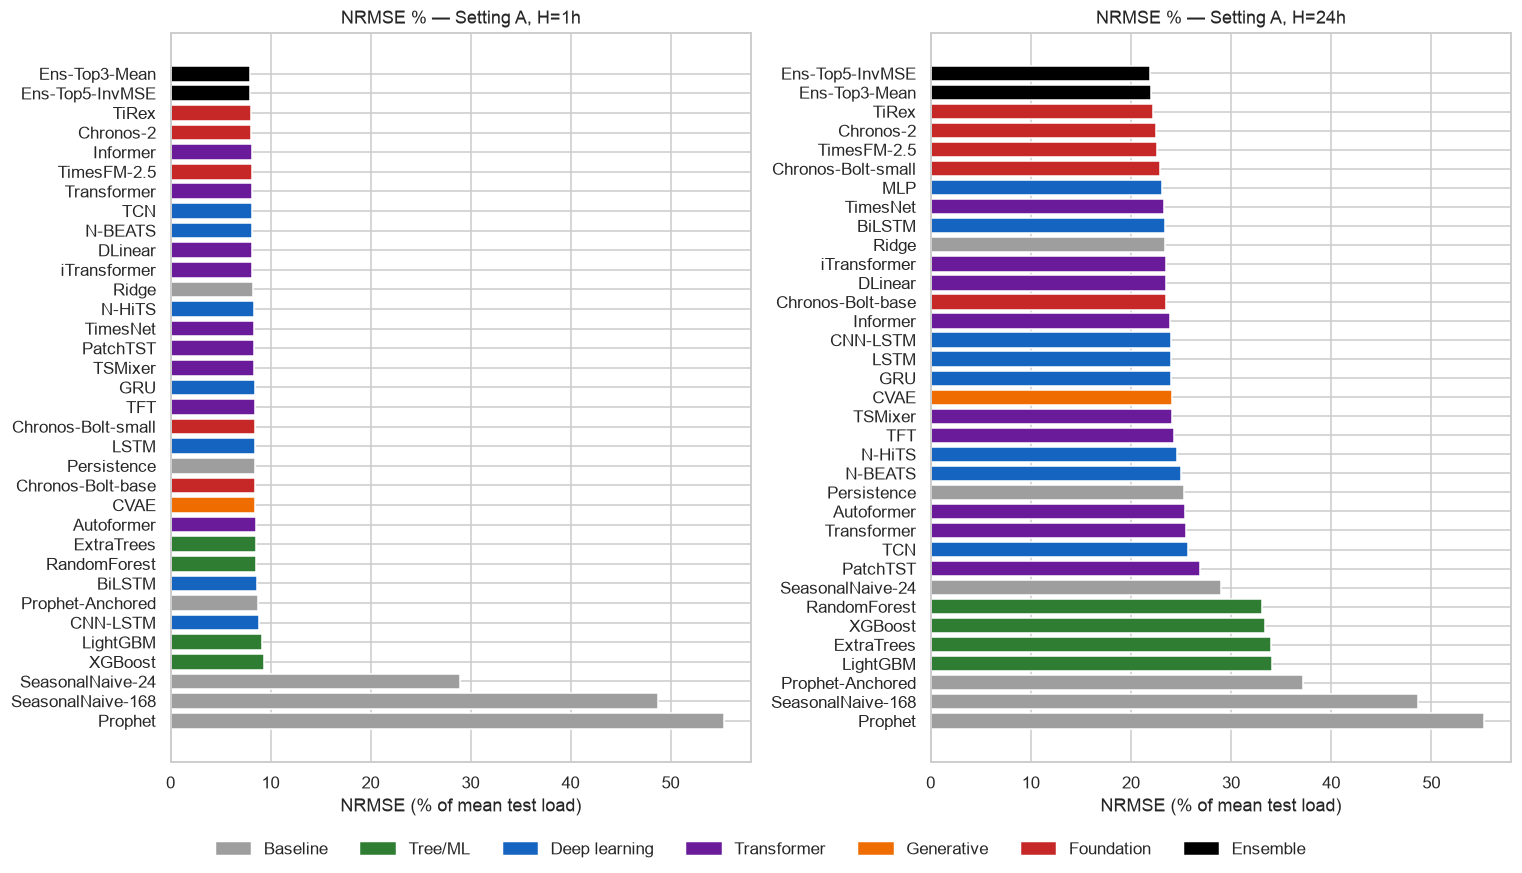

In [18]:
# ============================================================
# CELL 15 — Leaderboard
# ============================================================
RES = pd.read_csv(RES_PATH)
RES = RES[RES.dataset == DS_NAME]
COLS = ['model', 'family', 'RMSE', 'RMSE_std', 'MAE', 'NRMSE', 'NMAE', 'sMAPE', 'MASE', 'R2', 'val_RMSE', 'train_time_s', 'infer_ms_per_1k', 'n_params']
def leaderboard(setting, H):
    t = RES[(RES.setting == setting) & (RES.horizon == H)].sort_values('RMSE')[COLS].reset_index(drop=True)
    t['beats_snaive24'] = np.where(t['MASE'] < 1, 'YES', 'no')     # MASE<1 -> better than seasonal-naive-24
    t.index += 1; return t

for setting in CFG['SETTINGS']:
    for H in CFG['HORIZONS']:
        t = leaderboard(setting, H)
        if t.empty: print(f"\n(no results yet for setting {setting}, H={H})"); continue
        print(f"\n===== LEADERBOARD  {DS_NAME} | Setting {setting} | horizon {H}h | (lower = better; MASE<1 beats seasonal-naive-24) =====")
        # plain-text table: always readable, even where the styled table below does not render
        SHOW = ['model', 'family', 'RMSE', 'MAE', 'NRMSE', 'MASE', 'R2', 'val_RMSE', 'train_time_s', 'beats_snaive24']
        print(t[SHOW].round(4).to_string())
        print(f"\n--- best model per family (H={H}h) ---")
        print(t.drop_duplicates('family')[['family', 'model', 'RMSE', 'NRMSE', 'MASE']].round(4).to_string(index=False))
        try:
            display(t.round(4).style.background_gradient(subset=['RMSE'], cmap='RdYlGn_r').format(precision=4))
        except Exception as _e:
            print('(styled table not available:', _e, ')')
        t.round(5).to_csv(OUT / f'leaderboard_{DS_NAME}_{setting}_H{H}.csv')

# ---- bar chart of NRMSE by model ----
palette = {'Baseline': '#9e9e9e', 'Tree/ML': '#2e7d32', 'Deep learning': '#1565c0', 'Transformer': '#6a1b9a',
           'Generative': '#ef6c00', 'Foundation': '#c62828', 'Ensemble': '#000000'}
for setting in CFG['SETTINGS']:
    fig, axes = plt.subplots(1, len(CFG['HORIZONS']), figsize=(7 * len(CFG['HORIZONS']), 8), squeeze=False)
    for ax, H in zip(axes[0], CFG['HORIZONS']):
        t = leaderboard(setting, H).sort_values('NRMSE', ascending=False)
        if t.empty: continue
        ax.barh(t.model, t.NRMSE, color=[palette.get(f, '#333') for f in t.family])
        ax.set_title(f'NRMSE % — Setting {setting}, H={H}h'); ax.set_xlabel('NRMSE (% of mean test load)')
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()]
    fig.legend(handles, palette.keys(), loc='lower center', ncol=len(palette), frameon=False)
    plt.tight_layout(rect=(0, 0.04, 1, 1)); savefig(f'nrmse_bars_{setting}'); plt.show()

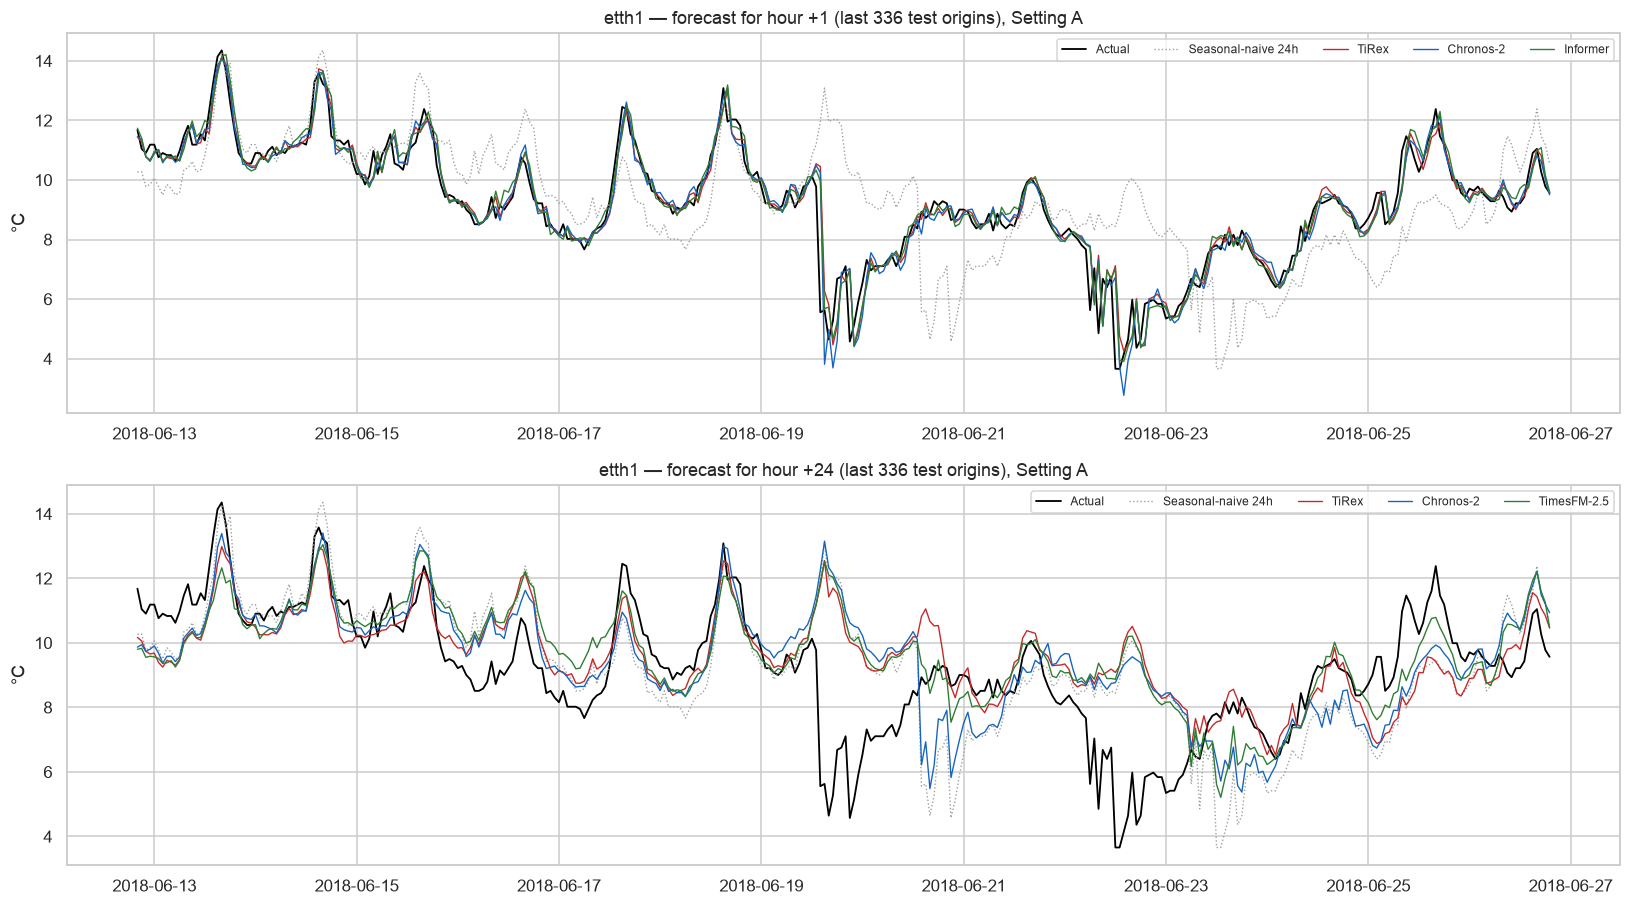

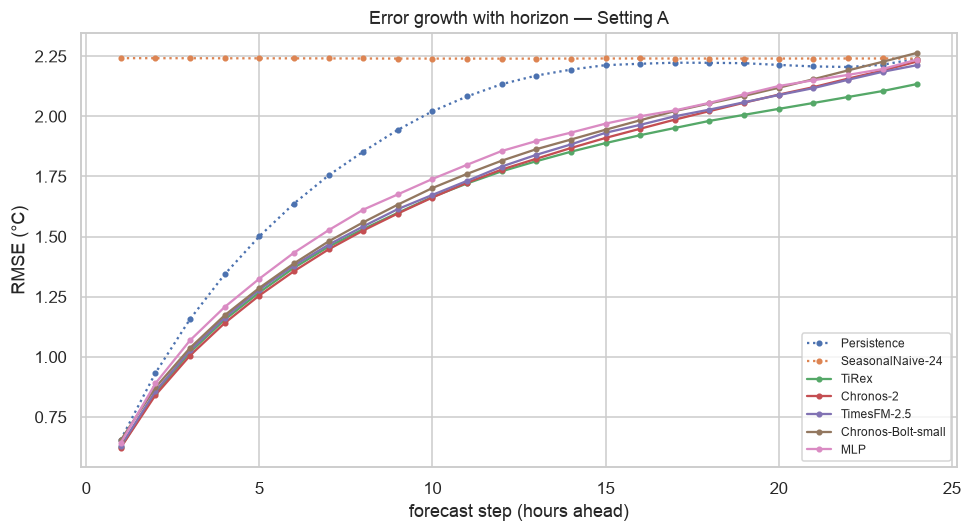

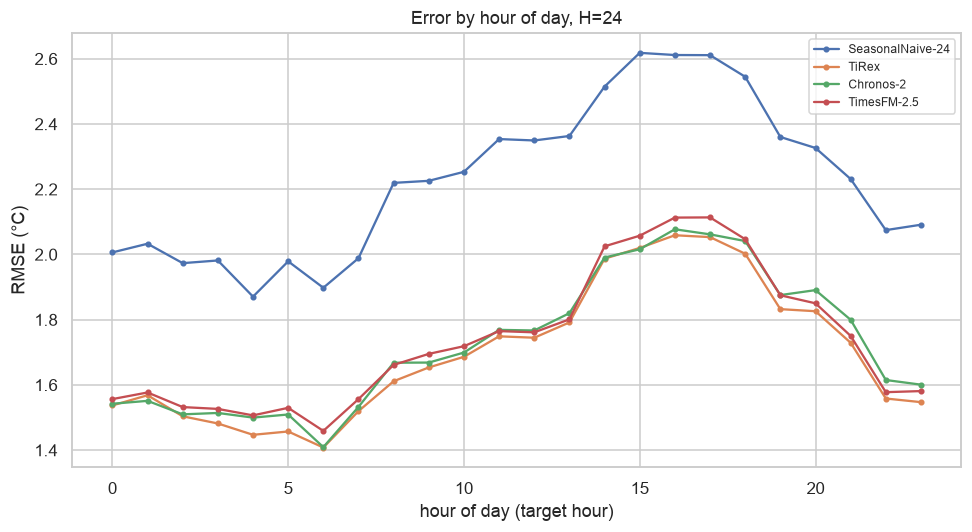

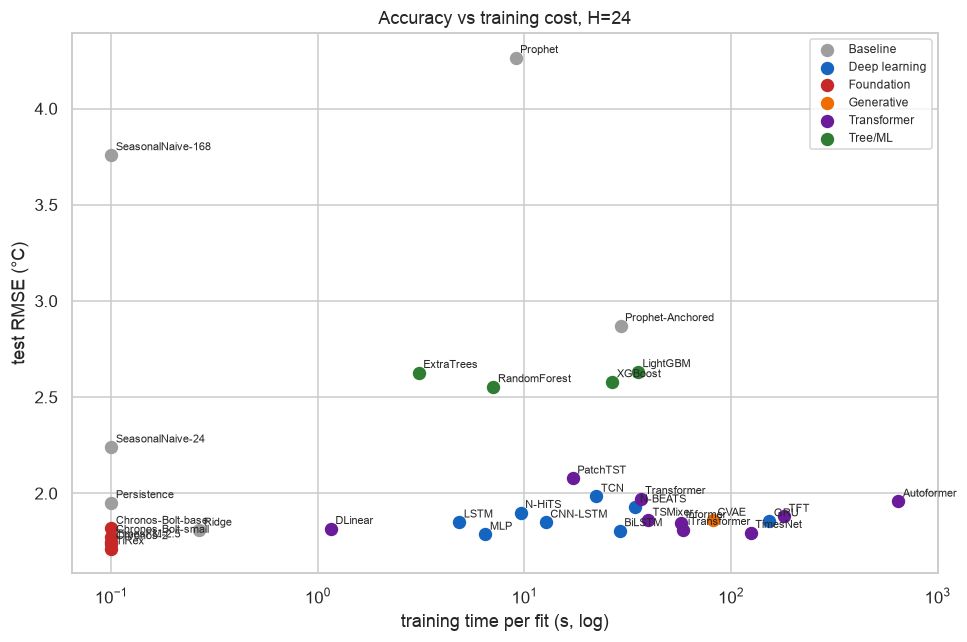

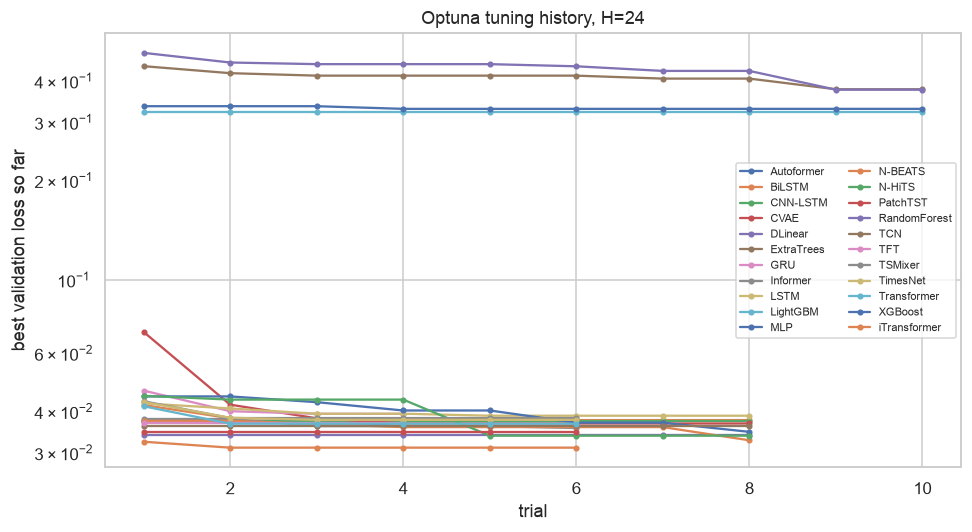

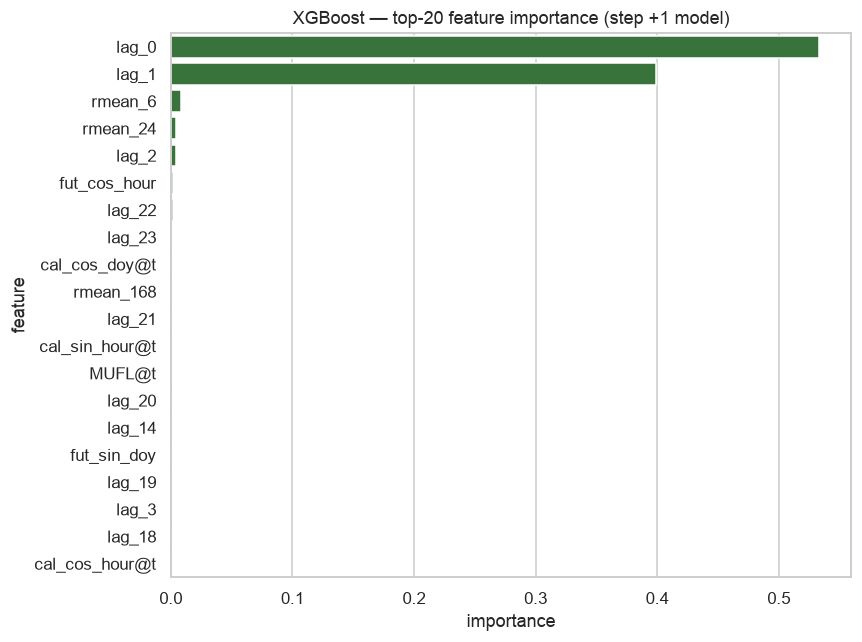

In [19]:
# ============================================================
# CELL 16 — Diagnostics: forecasts vs actual, error by horizon step, error by hour, efficiency, tuning history, importance
# ============================================================
MAIN_SETTING = CFG['SETTINGS'][0]; Hmax = max(CFG['HORIZONS']); bM = get_bundle(MAIN_SETTING)
def rows(setting, H): return RES[(RES.setting == setting) & (RES.horizon == H)]
def best_models(setting, H, n=3, exclude=('Ensemble', 'Baseline')):
    r = rows(setting, H); return list(r[~r.family.isin(exclude)].sort_values('RMSE').model.head(n))
def test_pred(setting, H, name): return np.load(pred_path(make_key(setting, H, name)))['test']
def have(setting, H, name): return pred_path(make_key(setting, H, name)).exists()    # model may have been skipped / not run

# ---- (1) actual vs predicted, last 14 days of the test set ----
fig, axes = plt.subplots(len(CFG['HORIZONS']), 1, figsize=(15, 4.2 * len(CFG['HORIZONS'])), squeeze=False)
for ax, H in zip(axes[:, 0], CFG['HORIZONS']):
    ot = get_origins(bM, 'test', 1, H); yt, mt = targets(bM, ot, H); tt = bM.idx[ot + H].to_numpy()
    n = min(336, len(ot)); sl = slice(-n, None)
    ax.plot(tt[sl], yt[sl, H-1], color='black', lw=1.2, label='Actual')
    if have(MAIN_SETTING, H, 'SeasonalNaive-24'):
        ax.plot(tt[sl], test_pred(MAIN_SETTING, H, 'SeasonalNaive-24')[sl, H-1], color='#9e9e9e', lw=0.9, ls=':', label='Seasonal-naive 24h')
    for nm, c in zip(best_models(MAIN_SETTING, H, 3), ['#c62828', '#1565c0', '#2e7d32']):
        ax.plot(tt[sl], test_pred(MAIN_SETTING, H, nm)[sl, H-1], color=c, lw=0.9, label=nm)
    ax.set_title(f'{DS_NAME} — forecast for hour +{H} (last {n} test origins), Setting {MAIN_SETTING}'); ax.set_ylabel(UNIT); ax.legend(ncol=5, fontsize=8)
plt.tight_layout(); savefig('actual_vs_pred'); plt.show()

# ---- (2) RMSE by forecast step (longest horizon) ----
if Hmax > 1:
    ot = get_origins(bM, 'test', 1, Hmax); yt, mt = targets(bM, ot, Hmax); plt.figure(figsize=(9, 5))
    for nm in [m for m in ['Persistence', 'SeasonalNaive-24'] + best_models(MAIN_SETTING, Hmax, 5) if have(MAIN_SETTING, Hmax, m)]:
        p = test_pred(MAIN_SETTING, Hmax, nm)
        r = [np.sqrt(np.mean(((p - yt)[:, h][mt[:, h]])**2)) for h in range(Hmax)]
        plt.plot(range(1, Hmax + 1), r, marker='o', ms=3, label=nm, ls=':' if nm in ('Persistence', 'SeasonalNaive-24') else '-')
    plt.xlabel('forecast step (hours ahead)'); plt.ylabel(f'RMSE ({UNIT})'); plt.title(f'Error growth with horizon — Setting {MAIN_SETTING}')
    plt.legend(fontsize=8); plt.tight_layout(); savefig('rmse_by_step'); plt.show()

# ---- (3) error by hour of day (target hour) ----
ot = get_origins(bM, 'test', 1, Hmax); yt, mt = targets(bM, ot, Hmax); hrs = bM.idx.hour.values[ot[:, None] + np.arange(1, Hmax + 1)]
plt.figure(figsize=(9, 5))
for nm in [m for m in ['SeasonalNaive-24'] + best_models(MAIN_SETTING, Hmax, 3) if have(MAIN_SETTING, Hmax, m)]:
    e = (test_pred(MAIN_SETTING, Hmax, nm) - yt)**2
    plt.plot(range(24), [np.sqrt(np.mean(e[(hrs == h) & mt])) for h in range(24)], marker='o', ms=3, label=nm)
plt.xlabel('hour of day (target hour)'); plt.ylabel(f'RMSE ({UNIT})'); plt.title(f'Error by hour of day, H={Hmax}'); plt.legend(fontsize=8)
plt.tight_layout(); savefig('rmse_by_hour'); plt.show()

# ---- (4) accuracy vs cost ----
r = rows(MAIN_SETTING, Hmax); r = r[~r.family.isin(['Ensemble'])]
plt.figure(figsize=(9, 6))
for fam, g in r.groupby('family'):
    plt.scatter(g.train_time_s.fillna(0) + 0.1, g.RMSE, s=60, color=palette.get(fam, '#333'), label=fam)
    for _, x in g.iterrows(): plt.annotate(x.model, (x.train_time_s + 0.1 if pd.notna(x.train_time_s) else 0.1, x.RMSE), fontsize=7, xytext=(3, 3), textcoords='offset points')
plt.xscale('log'); plt.xlabel('training time per fit (s, log)'); plt.ylabel(f'test RMSE ({UNIT})'); plt.title(f'Accuracy vs training cost, H={Hmax}')
plt.legend(fontsize=8); plt.tight_layout(); savefig('accuracy_vs_cost'); plt.show()

# ---- (5) tuning history ----
plt.figure(figsize=(9, 5)); any_curve = False
for f in sorted((OUT / 'tuning').glob(f"{safe(DS_NAME)}_{MAIN_SETTING}_H{Hmax}_*_trials.csv")):
    t = pd.read_csv(f)
    if 'value' in t and t['value'].notna().any():
        plt.plot(t['number'] + 1, t['value'].cummin(), marker='.', label=f.stem.replace(f"{safe(DS_NAME)}_{MAIN_SETTING}_H{Hmax}_", '').replace('_trials', '')); any_curve = True
if any_curve:
    plt.yscale('log'); plt.xlabel('trial'); plt.ylabel('best validation loss so far'); plt.title(f'Optuna tuning history, H={Hmax}')
    plt.legend(fontsize=7, ncol=2); plt.tight_layout(); savefig('tuning_history'); plt.show()
else: plt.close()

# ---- (6) tree feature importance (if available) ----
for nm in ['XGBoost', 'LightGBM']:
    f = OUT / 'artifacts' / (safe(make_key(MAIN_SETTING, Hmax, nm)) + '_importance.csv')
    if f.exists():
        imp = pd.read_csv(f).sort_values('importance', ascending=False).head(20)
        plt.figure(figsize=(8, 6)); sns.barplot(x='importance', y='feature', data=imp, color='#2e7d32')
        plt.title(f'{nm} — top-20 feature importance (step +1 model)'); plt.tight_layout(); savefig(f'importance_{nm}'); plt.show(); break

In [20]:
# ============================================================
# CELL 17 — Statistical significance (Diebold–Mariano) + best-model summary
# ============================================================
def dm_test(e1, e2, H):
    """H0: equal squared-error accuracy. stat>0 => model 1 WORSE than model 2.
    Newey-West HAC variance with lag = max(H-1, round(n^(1/3))) (v9). The old lag H-1 means NO correction at H=1, although
    hourly forecast errors are serially correlated; in a simulation that inflated false 'significant' verdicts from 5% to 24-52%."""
    d = np.nanmean(e1**2 - e2**2, axis=1); d = d[np.isfinite(d)]; n = len(d); dbar = d.mean(); dc = d - dbar
    L = max(H - 1, int(round(n ** (1 / 3))))
    var = np.sum(dc * dc) / n
    for k in range(1, L + 1): var += 2 * (1 - k / (L + 1)) * np.sum(dc[k:] * dc[:-k]) / n
    stat = dbar / math.sqrt(max(var, 1e-18) / n); p = math.erfc(abs(stat) / math.sqrt(2)); return stat, p

for setting in CFG['SETTINGS']:
    for H in CFG['HORIZONS']:
        b = get_bundle(setting); ot = get_origins(b, 'test', 1, H); yt, mt = targets(b, ot, H)
        r = rows(setting, H).sort_values('RMSE'); top = list(r.model.head(6))
        top = [m for m in top if have(setting, H, m)]
        if len(top) < 2: print(f"\nDiebold–Mariano | Setting {setting} | H={H}h: need at least 2 models with saved predictions — skipped"); continue
        best = top[0]
        err = lambda nm: np.where(mt, test_pred(setting, H, nm) - yt, np.nan)
        out = []
        for nm in top[1:]:
            s, p = dm_test(err(nm), err(best), H); out.append(dict(vs_best=nm, DM_stat=round(s, 2), p_value=round(p, 4),
                                                                   significantly_worse_at_5pct=bool(p < 0.05 and s > 0)))
        print(f"\nDiebold–Mariano | Setting {setting} | H={H}h | best = {best}")
        display(pd.DataFrame(out))

print("\n" + "=" * 70 + "\nBEST INDIVIDUAL MODEL PER SETTING/HORIZON (ensembles excluded)\n" + "=" * 70)
summary = {}
for setting in CFG['SETTINGS']:
    for H in CFG['HORIZONS']:
        r = rows(setting, H); r = r[r.family != 'Ensemble'].sort_values('RMSE')
        if r.empty: continue
        x = r.iloc[0]; sn = r[r.model == 'SeasonalNaive-24']
        gain = f"{100 * (1 - x.RMSE / sn.iloc[0].RMSE):.1f}% lower RMSE than seasonal-naive-24" if len(sn) else ""
        print(f"[{setting}] H={H:<3} → {x.model:<18} RMSE={x.RMSE:.4f} {UNIT}  NRMSE={x.NRMSE:.2f}%  MASE={x.MASE:.3f}   {gain}")
        summary[f'{setting}_H{H}'] = dict(model=x.model, RMSE=x.RMSE, NRMSE=x.NRMSE, MASE=x.MASE, best_params=json.loads(x.best_params))
json.dump(summary, open(OUT / f'best_models_{DS_NAME}.json', 'w'), indent=2, default=str)


Diebold–Mariano | Setting A | H=1h | best = Ens-Top3-Mean


,vs_best,DM_stat,p_value,significantly_worse_at_5pct
0,Ens-Top5-InvMSE,1.02,0.3059,False
1,TiRex,4.28,0.0000,True
2,Chronos-2,3.56,0.0004,True
3,Informer,4.08,0.0000,True
4,TimesFM-2.5,4.00,0.0001,True



Diebold–Mariano | Setting A | H=24h | best = Ens-Top5-InvMSE


,vs_best,DM_stat,p_value,significantly_worse_at_5pct
0,Ens-Top3-Mean,1.18,0.2396,False
1,TiRex,1.07,0.2830,False
2,Chronos-2,1.99,0.0463,True
3,TimesFM-2.5,2.24,0.0251,True
4,Chronos-Bolt-small,2.78,0.0055,True



BEST INDIVIDUAL MODEL PER SETTING/HORIZON (ensembles excluded)
[A] H=1   → TiRex              RMSE=0.6224 °C  NRMSE=8.06%  MASE=0.177   72.2% lower RMSE than seasonal-naive-24
[A] H=24  → TiRex              RMSE=1.7111 °C  NRMSE=22.16%  MASE=0.522   23.6% lower RMSE than seasonal-naive-24


## Paper-ready tables (new in v8)
The next cell turns the saved results into tables you can paste into the paper. It writes **CSV + Markdown + LaTeX** files to `<results folder>/paper_tables/`:
- **Table 1 (full):** every model per horizon, with RMSE/MAE in the dataset's unit, NRMSE %, MASE, R², *skill vs seasonal-naive-24*, and a **Diebold–Mariano marker** (`best` / `n.s.` = not significantly worse than the best / `sig. worse`).
- **Table 2 (headline summary):** best single model, best ensemble, and the Persistence / seasonal-naive references, with % improvement.
- **Table 3 (best per family).**
- **`paper_summary_<dataset>.txt`:** a short auto-written results paragraph (numbers filled in from your run).

LaTeX tables use `booktabs` — add `\usepackage{booktabs}` to your preamble.

In [21]:
# ============================================================
# CELL 17b — PAPER-READY TABLES  (CSV + Markdown + LaTeX in <OUT>/paper_tables/)
# ============================================================
PAPER = OUT / 'paper_tables'; PAPER.mkdir(exist_ok=True)
RES_P = pd.read_csv(RES_PATH); RES_P = RES_P[RES_P.dataset == DS_NAME]
NAIVE = {'Persistence', 'SeasonalNaive-24', 'SeasonalNaive-168'}

def _md_table(df):
    cols = list(df.columns)
    lines = ['| ' + ' | '.join(map(str, cols)) + ' |', '|' + '|'.join(['---'] * len(cols)) + '|']
    for _, r in df.iterrows(): lines.append('| ' + ' | '.join('' if pd.isna(v) else str(v) for v in r.values) + ' |')
    return '\n'.join(lines)

def _tex(s):
    s = str(s)
    for a, b_ in [('\\', r'\textbackslash{}'), ('&', r'\&'), ('%', r'\%'), ('_', r'\_'), ('#', r'\#'),
                  ('\u00b1', r'$\pm$'), ('\u00b2', r'$^2$'), ('\u00b0', r'$^\circ$'), ('\u2020', r'$^\dagger$')]:
        s = s.replace(a, b_)
    return s

def _latex_table(df, caption, label, n_text):
    cols = list(df.columns)
    out = [r'\begin{table}[ht]', r'\centering', r'\small', r'\caption{' + _tex(caption) + '}', r'\label{' + label + '}',
           r'\begin{tabular}{' + 'l' * n_text + 'r' * (len(cols) - n_text) + '}', r'\toprule',
           ' & '.join(_tex(c) for c in cols) + r' \\', r'\midrule']
    for _, r in df.iterrows(): out.append(' & '.join('' if pd.isna(v) else _tex(v) for v in r.values) + r' \\')
    return '\n'.join(out + [r'\bottomrule', r'\end{tabular}', r'\end{table}'])

def _save(df, stem, caption, n_text):
    df.to_csv(PAPER / f'{stem}.csv', index=False)
    (PAPER / f'{stem}.md').write_text(_md_table(df))
    (PAPER / f'{stem}.tex').write_text(_latex_table(df, caption, 'tab:' + stem, n_text))

def _test_info(b):
    return (f"Test period {b.idx[b.n_tr + b.n_val]:%Y-%m-%d} to {b.idx[-1]:%Y-%m-%d} ({b.n_te} h); "
            f"mean test load {b.mean_load:.1f} {UNIT}")

def paper_full(setting, H):
    t = RES_P[(RES_P.setting == setting) & (RES_P.horizon == H)].sort_values('RMSE').reset_index(drop=True)
    if t.empty: return None
    b = get_bundle(setting); ot = get_origins(b, 'test', 1, H); yt, mt = targets(b, ot, H)
    best = t.model.iloc[0]; dec = 2 if b.mean_load >= 50 else 4
    sn = t[t.model == 'SeasonalNaive-24']; sn_rmse = float(sn.RMSE.iloc[0]) if len(sn) else np.nan
    err = lambda nm: np.where(mt, test_pred(setting, H, nm) - yt, np.nan)
    marks = []
    for nm in t.model:
        if nm == best: marks.append('best')
        elif not (have(setting, H, nm) and have(setting, H, best)): marks.append('-')
        else:
            s, p = dm_test(err(nm), err(best), H); marks.append('sig. worse' if (p < 0.05 and s > 0) else 'n.s.')
    rm = [f"{r:.{dec}f}" + (f" \u00b1 {s:.{dec}f}" if pd.notna(s) and s > 0 else '') for r, s in zip(t.RMSE, t.RMSE_std)]
    out = pd.DataFrame({'Rank': np.arange(1, len(t) + 1), 'Model': t.model, 'Family': t.family,
                        f'RMSE ({UNIT})': rm, f'MAE ({UNIT})': t.MAE.map(lambda x: f"{x:.{dec}f}"),
                        'NRMSE (%)': t.NRMSE.map(lambda x: f"{x:.2f}"), 'MASE': t.MASE.map(lambda x: f"{x:.3f}"),
                        'R\u00b2': t.R2.map(lambda x: f"{x:.3f}"),
                        'Skill vs SN-24 (%)': [f"{100 * (1 - r / sn_rmse):.1f}" if np.isfinite(sn_rmse) else '' for r in t.RMSE],
                        'vs best (DM, 5%)': marks})
    return out, t, b, dec

def paper_summary(setting):
    recs = []
    for H in CFG['HORIZONS']:
        t = RES_P[(RES_P.setting == setting) & (RES_P.horizon == H)]
        if t.empty: continue
        b = get_bundle(setting); dec = 2 if b.mean_load >= 50 else 4
        ref = lambda m: float(t[t.model == m].RMSE.iloc[0]) if (t.model == m).any() else np.nan
        sn, pe = ref('SeasonalNaive-24'), ref('Persistence')
        picks = [('Best single model', t[(t.family != 'Ensemble') & (~t.model.isin(NAIVE))].sort_values('RMSE')),
                 ('Best ensemble', t[t.family == 'Ensemble'].sort_values('RMSE')),
                 ('Persistence', t[t.model == 'Persistence']), ('Seasonal-naive-24', t[t.model == 'SeasonalNaive-24'])]
        for role, sub in picks:
            if sub.empty: continue
            x = sub.iloc[0]
            recs.append({'Horizon (h)': H, 'Role': role, 'Model': x.model, f'RMSE ({UNIT})': f"{x.RMSE:.{dec}f}",
                         'NRMSE (%)': f"{x.NRMSE:.2f}", 'MASE': f"{x.MASE:.3f}",
                         'vs Persistence (%)': f"{100 * (1 - x.RMSE / pe):.1f}" if np.isfinite(pe) else '',
                         'vs SN-24 (%)': f"{100 * (1 - x.RMSE / sn):.1f}" if np.isfinite(sn) else ''})
    return pd.DataFrame(recs)

def paper_by_family(setting):
    recs = []
    for H in CFG['HORIZONS']:
        t = RES_P[(RES_P.setting == setting) & (RES_P.horizon == H)].sort_values('RMSE')
        if t.empty: continue
        dec = 2 if get_bundle(setting).mean_load >= 50 else 4
        for _, x in t.drop_duplicates('family').iterrows():
            recs.append({'Horizon (h)': H, 'Family': x.family, 'Model': x.model, f'RMSE ({UNIT})': f"{x.RMSE:.{dec}f}",
                         'NRMSE (%)': f"{x.NRMSE:.2f}", 'MASE': f"{x.MASE:.3f}"})
    return pd.DataFrame(recs)

para = []
for setting in CFG['SETTINGS']:
    b = get_bundle(setting)
    tinfo = _test_info(b)
    for H in CFG['HORIZONS']:
        res = paper_full(setting, H)
        if res is None: continue
        full_t, raw_t, _, dec = res
        _save(full_t, f'{DS_NAME}_{setting}_H{H}_full', f'{DS_NAME}, Setting {setting}, horizon {H} h. {tinfo}. '
              f'Skill = RMSE reduction vs seasonal-naive-24; DM = Diebold-Mariano test vs the best model.', 3)
        n_ns = int((full_t['vs best (DM, 5%)'] == 'n.s.').sum())
        top = raw_t[(raw_t.family != 'Ensemble') & (~raw_t.model.isin(NAIVE))].iloc[0]
        _best = raw_t.model.iloc[0]
        _tie = (f"{n_ns} other model(s) were not significantly worse than the overall best ({_best}) under a Diebold-Mariano "
                f"test at the 5% level, so the ranking among these models should be read as a statistical tie."
                if n_ns > 0 else
                f"Every other model was significantly worse than the overall best ({_best}) under a Diebold-Mariano test "
                f"at the 5% level.")
        para.append(f"At a {H}-hour horizon the best individual model on {DS_NAME} (Setting {setting}) was {top.model} "
                    f"(RMSE {top.RMSE:.{dec}f} {UNIT}, NRMSE {top.NRMSE:.2f}%, MASE {top.MASE:.3f}). " + _tie)
    summ = paper_summary(setting); fam = paper_by_family(setting)
    _save(summ, f'{DS_NAME}_{setting}_summary', f'Headline results, {DS_NAME}, Setting {setting}. {tinfo}.', 3)
    _save(fam, f'{DS_NAME}_{setting}_by_family', f'Best model per family, {DS_NAME}, Setting {setting}.', 3)
    if setting == CFG['SETTINGS'][0]:
        print(f"===== TABLE 2 — headline summary ({DS_NAME}, Setting {setting}) =====\n{tinfo}\n")
        print(_md_table(summ))
        print(f"\n===== TABLE 3 — best model per family =====\n"); print(_md_table(fam))
(PAPER / f'paper_summary_{DS_NAME}.txt').write_text(f"{_test_info(get_bundle(CFG['SETTINGS'][0]))}.\n\n" + "\n\n".join(para))
print("\n===== AUTO-WRITTEN RESULTS PARAGRAPH =====\n" + "\n\n".join(para))
print(f"\nFiles written to: {PAPER}  (Table 1 per horizon: *_full.*, plus *_summary.* and *_by_family.*; formats .csv/.md/.tex)")

===== TABLE 2 — headline summary (etth1, Setting A) =====
Test period 2018-02-01 to 2018-06-26 (3484 h); mean test load 7.7 °C

| Horizon (h) | Role | Model | RMSE (°C) | NRMSE (%) | MASE | vs Persistence (%) | vs SN-24 (%) |
|---|---|---|---|---|---|---|---|
| 1 | Best single model | TiRex | 0.6224 | 8.06 | 0.177 | 4.9 | 72.2 |
| 1 | Best ensemble | Ens-Top3-Mean | 0.6130 | 7.94 | 0.174 | 6.3 | 72.6 |
| 1 | Persistence | Persistence | 0.6542 | 8.47 | 0.190 | 0.0 | 70.7 |
| 1 | Seasonal-naive-24 | SeasonalNaive-24 | 2.2365 | 28.97 | 0.726 | -241.9 | 0.0 |
| 24 | Best single model | TiRex | 1.7111 | 22.16 | 0.522 | 12.3 | 23.6 |
| 24 | Best ensemble | Ens-Top5-InvMSE | 1.6906 | 21.89 | 0.514 | 13.3 | 24.5 |
| 24 | Persistence | Persistence | 1.9510 | 25.27 | 0.611 | 0.0 | 12.9 |
| 24 | Seasonal-naive-24 | SeasonalNaive-24 | 2.2406 | 29.02 | 0.727 | -14.8 | 0.0 |

===== TABLE 3 — best model per family =====

| Horizon (h) | Family | Model | RMSE (°C) | NRMSE (%) | MASE |
|---|---|---|---

In [22]:
# ============================================================
# CELL 18 — Leakage ablation (Setting A vs B)  →  quantifies how much the OLD setup flattered the results
# Setting B feeds the covariates measured DURING the target hour (Global_intensity, Voltage, sub-meters ...).
# ============================================================
ABL_MODELS = ['Ridge', 'XGBoost', 'LSTM']
ABL_MODELS = [m for m in ABL_MODELS if m in RUNNERS]
if len(DS['covariates']) == 0:
    print("This dataset has no covariates — ablation not applicable.")
else:
    for st in ['A', 'B']: run_experiment(st, 1, models=ABL_MODELS)
    RES = pd.read_csv(RES_PATH); RES = RES[RES.dataset == DS_NAME]
    a = RES[(RES.setting == 'A') & (RES.horizon == 1) & RES.model.isin(ABL_MODELS)].set_index('model')
    bb = RES[(RES.setting == 'B') & (RES.horizon == 1) & RES.model.isin(ABL_MODELS)].set_index('model')
    tbl = pd.DataFrame({'RMSE_A_forecast': a.RMSE, 'RMSE_B_leaky': bb.RMSE, 'NRMSE_A_%': a.NRMSE, 'NRMSE_B_%': bb.NRMSE}).dropna()
    tbl['error_reduction_from_leakage_%'] = 100 * (1 - tbl.RMSE_B_leaky / tbl.RMSE_A_forecast)
    print("\nSame models, same data — only difference: inputs include covariates measured in the target hour (B) or not (A):")
    display(tbl.round(4)); tbl.round(5).to_csv(OUT / f'leakage_ablation_{DS_NAME}.csv')
    print("→ B numbers are NOT achievable in real forecasting (the covariates are unknown at forecast time).")


########################################################################
# dataset=etth1  setting=A  horizon=1h  mode=STANDARD
########################################################################
   · Ridge                (already done — skipped)
   · XGBoost              (already done — skipped)
   · LSTM                 (already done — skipped)

########################################################################
# dataset=etth1  setting=B  horizon=1h  mode=STANDARD
########################################################################
   ✓ Ridge                H=1   RMSE=0.6363  MAE=0.4402  NRMSE=8.24%  MASE=0.186  (val RMSE 0.5702)
     [Ridge took 1s | mps tensors 0.00 GiB, driver 0.01 GiB]
   ✓ XGBoost              H=1   RMSE=0.8663  MAE=0.6510  NRMSE=11.22%  MASE=0.276  (val RMSE 1.0259)
     [XGBoost took 33s | mps tensors 0.00 GiB, driver 0.01 GiB]
     [device] LSTM: cpu 134 ms/step vs mps 25 ms/step -> mps
   ✓ LSTM                 H=1   RMSE=0.6580  MAE=0.4508  N

,RMSE_A_forecast,RMSE_B_leaky,NRMSE_A_%,NRMSE_B_%,error_reduction_from_leakage_%
model,,,,,
Ridge,0.6377,0.6363,8.2591,8.2405,0.2241
XGBoost,0.7233,0.8663,9.3677,11.2202,-19.7751
LSTM,0.6534,0.6580,8.4619,8.5217,-0.7074


→ B numbers are NOT achievable in real forecasting (the covariates are unknown at forecast time).


Datasets with results (Setting A, mode STANDARD): ['etth1', 'ihepc', 'pjm']

1) Dataset difficulty — NRMSE (%) of naive references vs. the best single model:


Persistence  SeasonalNaive-24  best_single_model  \
dataset horizon                                                     
etth1   1               8.47             28.97               8.06   
        24             25.27             29.02              22.16   
ihepc   1              59.80             78.47              44.26   
pjm     1               3.86              8.84               1.59   

                 skill_vs_seasonal_naive_%  
dataset horizon                             
etth1   1                            72.17  
        24                           23.63  
ihepc   1                            43.60  
pjm     1                            81.99

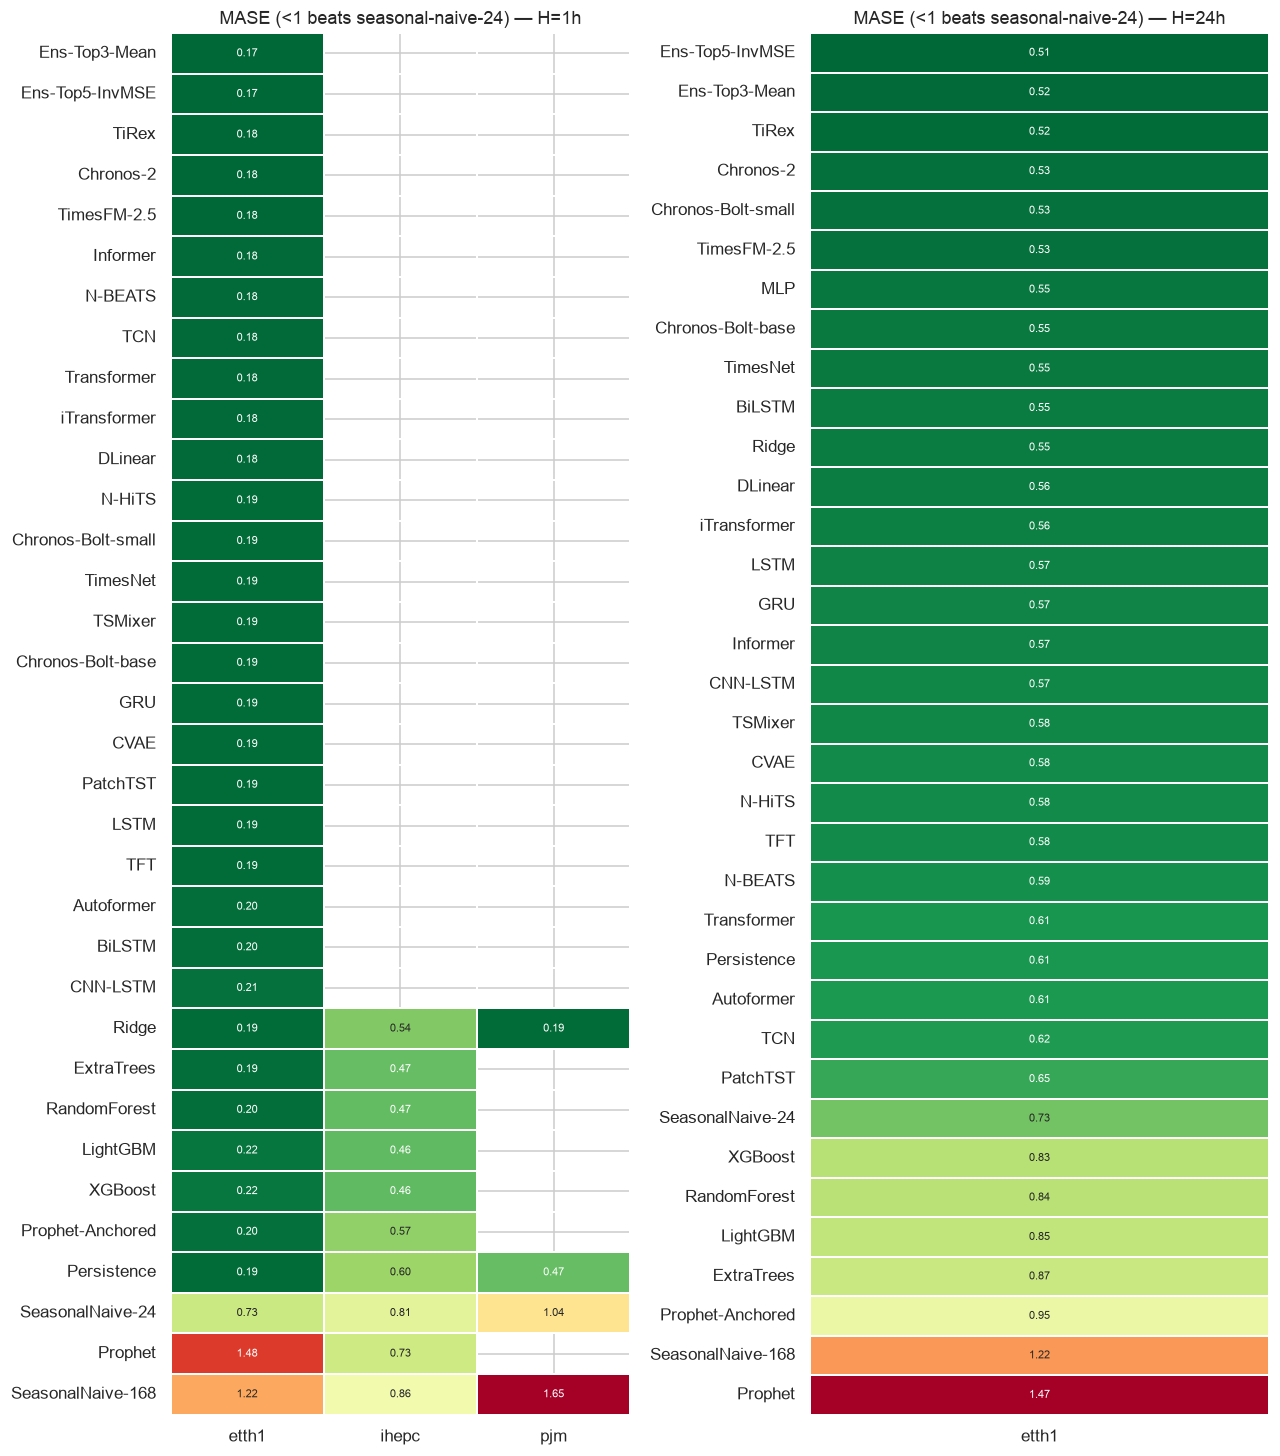

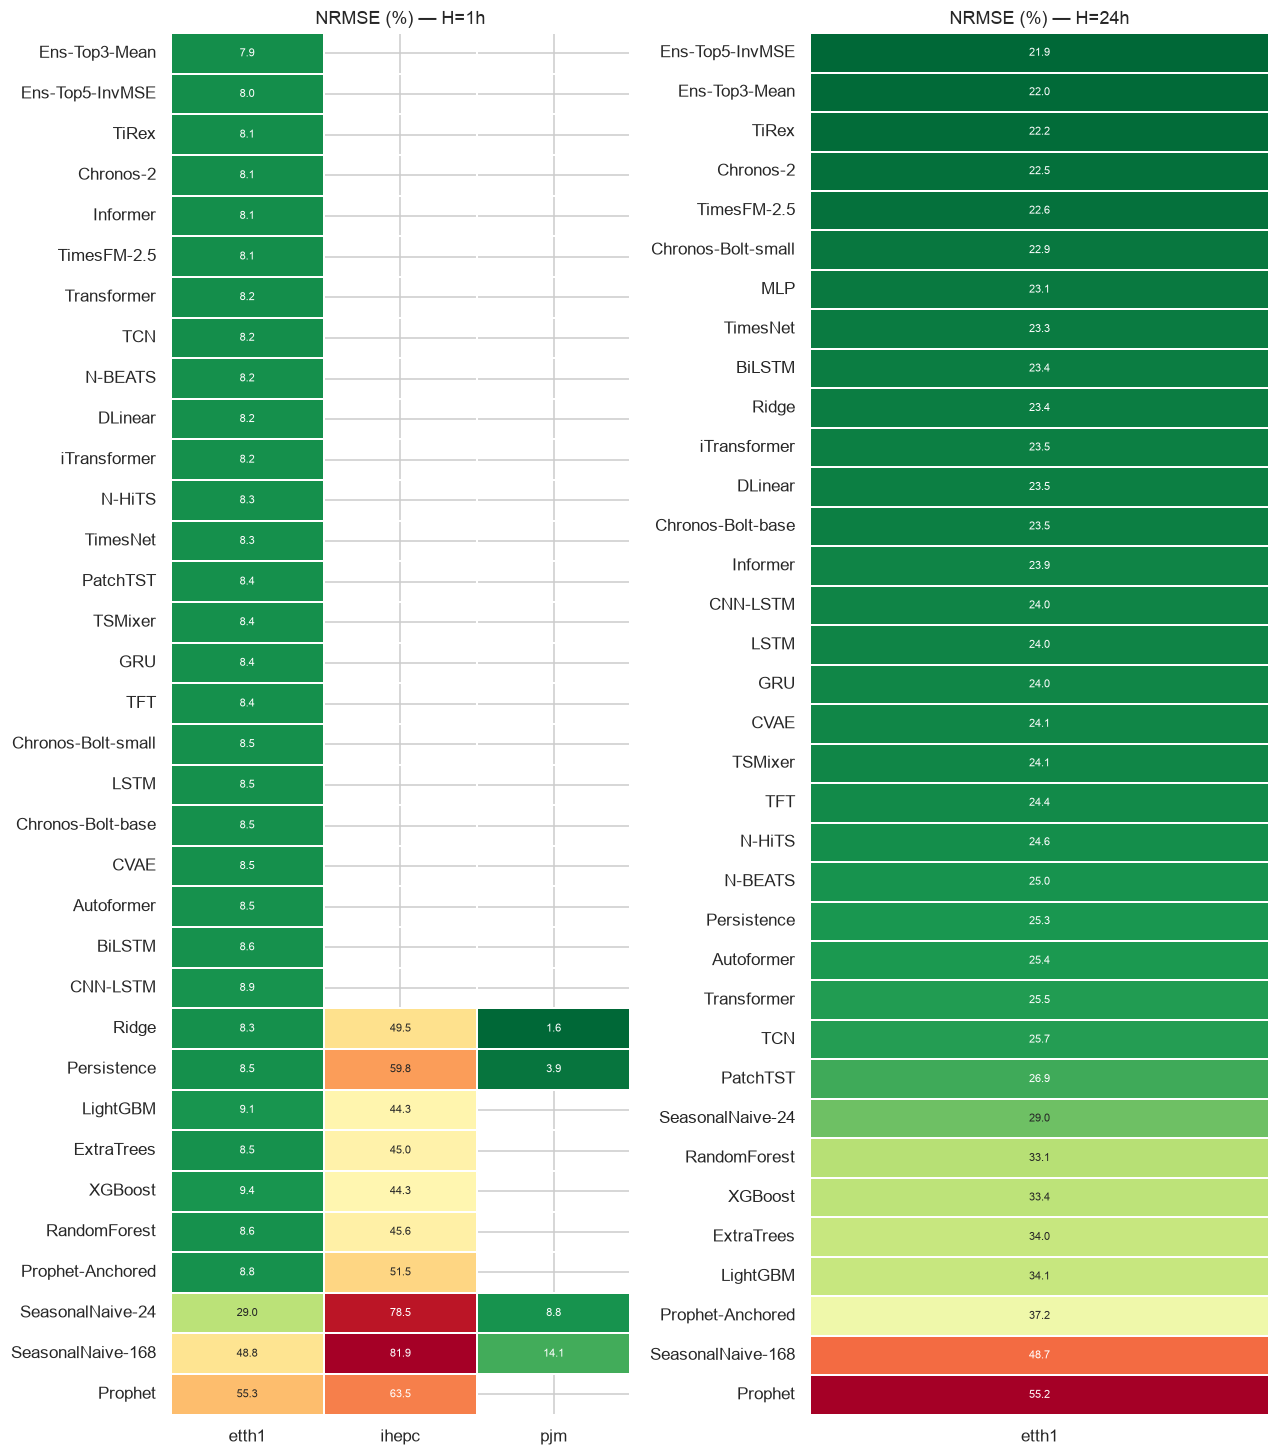


3) Top models by mean rank across datasets — H=1h (only models present on at least 2 of 3 datasets):


,model,family,datasets,mean_rank,mean_rel_RMSE,wins
0,Ridge,Baseline,3,5.333,1.048,1
1,Persistence,Baseline,3,9.333,1.608,0
2,ExtraTrees,Tree/ML,2,13.000,1.039,0
3,RandomForest,Tree/ML,2,14.000,1.047,0
4,SeasonalNaive-24,Baseline,3,14.000,3.640,0
5,LightGBM,Tree/ML,2,15.000,1.068,0
6,SeasonalNaive-168,Baseline,3,15.000,5.576,0
7,XGBoost,Tree/ML,2,15.000,1.081,1
8,Prophet-Anchored,Baseline,2,16.000,1.125,0
9,Prophet,Baseline,2,20.000,4.149,0



3) Top models by mean rank across datasets — H=24h (only models present on at least 2 of 3 datasets):


,model,family,datasets,mean_rank,mean_rel_RMSE,wins


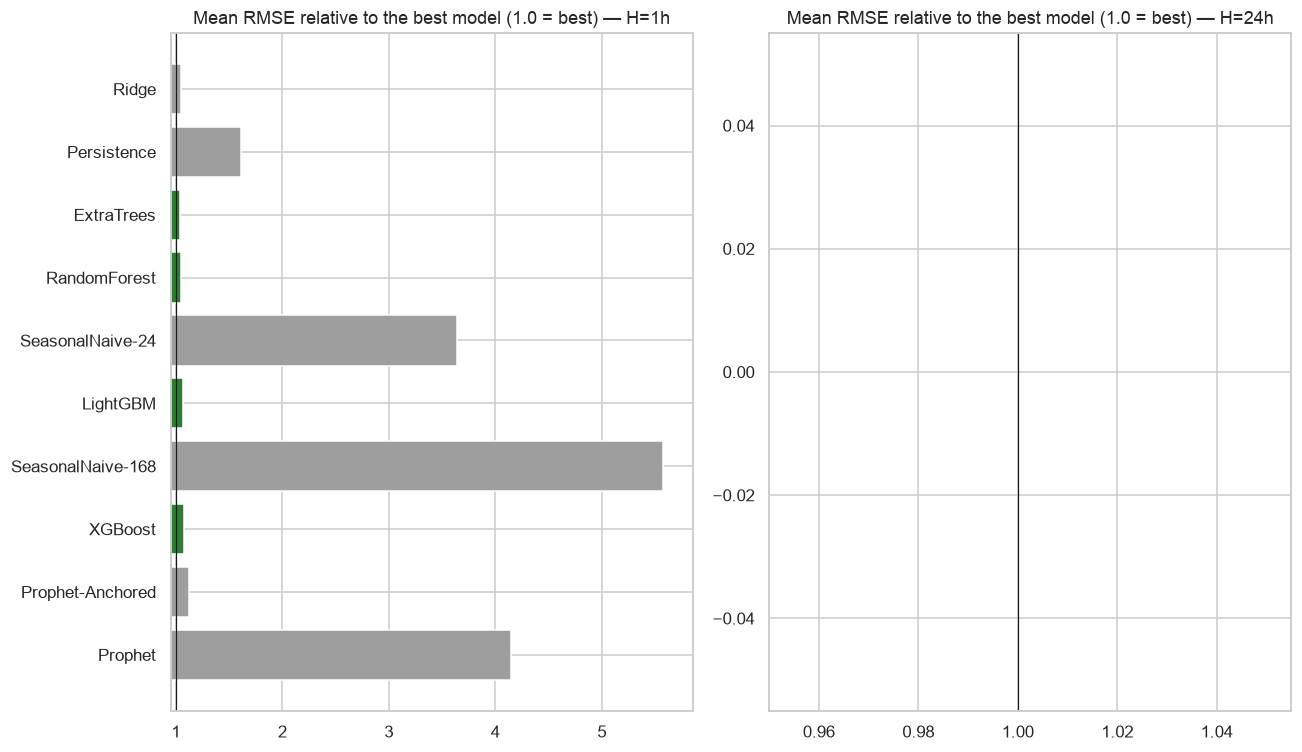


4) Best model of each family, RMSE relative to the best single model (1.00 = that family has the overall best model):


horizon           1                  24
dataset        etth1  ihepc  pjm  etth1
family                                 
Baseline       1.025  1.119  1.0  1.057
Deep learning  1.013    NaN  NaN  1.044
Foundation     1.000    NaN  NaN  1.000
Generative     1.052    NaN  NaN  1.087
Transformer    1.005    NaN  NaN  1.050
Tree/ML        1.059  1.000  NaN  1.493


5) Ensemble gain over the best single model (%, positive = ensemble better):


ensemble_gain_over_best_single_%
dataset horizon                                  
etth1   1                                    1.52
        24                                   1.20
ihepc   1                                     NaN
pjm     1                                     NaN


Saved tables and figures to aifs_results_STANDARD/cross_dataset
H=1h: best mean rank = Ridge (5.33); lowest mean relative RMSE = ExtraTrees (1.039)


In [23]:
# ============================================================
# CELL 19 — CROSS-DATASET COMPARISON  (v10)
# Reads EVERY dataset that has results in this run mode's folder (<OUT>/results.csv) and compares models across datasets.
# Workflow: run the notebook once per dataset (PRESET or CFG['DATASET']), always with the same RUN_MODE, then run this cell.
# It is self-contained: after a kernel restart, run Cell 0, Cell 2 and Cell 3 (for OUT) and then this cell.
# ============================================================
palette = globals().get('palette') or {'Baseline': '#9e9e9e', 'Tree/ML': '#2e7d32', 'Deep learning': '#1565c0', 'Transformer': '#6a1b9a',
                                        'Generative': '#ef6c00', 'Foundation': '#c62828', 'Ensemble': '#000000'}
CROSS = OUT / 'cross_dataset'; CROSS.mkdir(exist_ok=True)
_all = pd.read_csv(OUT / 'results.csv')
_set = CFG['SETTINGS'][0]
_d = _all[(_all.setting == _set)].copy()
_ds = sorted(_d.dataset.unique()); _hs = sorted(_d.horizon.unique())
print(f"Datasets with results (Setting {_set}, mode {CFG['RUN_MODE']}): {_ds}")
if len(_ds) < 2:
    print("-> only one dataset so far. Run the other datasets with the same RUN_MODE (see PRESETS in Cell 2), then re-run this cell.")

# ---- 1) dataset difficulty: how hard is each dataset for the naive references? ----
_ref = _d[_d.model.isin(['Persistence', 'SeasonalNaive-24'])].pivot_table(index=['dataset', 'horizon'], columns='model', values='NRMSE')
_best = _d[~_d.family.isin(['Ensemble'])].groupby(['dataset', 'horizon']).NRMSE.min().rename('best_single_model')
_diff = _ref.join(_best); _diff['skill_vs_seasonal_naive_%'] = 100 * (1 - _diff['best_single_model'] / _diff['SeasonalNaive-24'])
print("\n1) Dataset difficulty — NRMSE (%) of naive references vs. the best single model:")
display(_diff.round(2)); _diff.round(3).to_csv(CROSS / 'dataset_difficulty.csv')

# ---- 2) heat-maps: models x datasets (one panel per horizon). MASE is comparable across datasets; NRMSE is not scale-free in meaning ----
for _metric, _title in [('MASE', 'MASE (<1 beats seasonal-naive-24)'), ('NRMSE', 'NRMSE (%)')]:
    fig, axes = plt.subplots(1, len(_hs), figsize=(5.4 * len(_hs) + 1, 0.34 * max(10, _d.model.nunique()) + 1.5), squeeze=False)
    for ax, H in zip(axes[0], _hs):
        P = _d[_d.horizon == H].pivot_table(index='model', columns='dataset', values=_metric)
        P = P.loc[P.mean(axis=1).sort_values().index]
        sns.heatmap(P, annot=True, fmt='.2f' if _metric == 'MASE' else '.1f', cmap='RdYlGn_r', cbar=False, ax=ax, annot_kws={'size': 7}, linewidths=.3)
        ax.set_title(f'{_title} — H={H}h'); ax.set_ylabel(''); ax.set_xlabel('')
        P.round(3).to_csv(CROSS / f'matrix_{_metric}_H{H}.csv')
    plt.tight_layout(); plt.savefig(CROSS / f'heatmap_{_metric}.png', dpi=150, bbox_inches='tight'); plt.show()

# ---- 3) average rank and relative error across datasets (individual models; ensembles shown separately) ----
_ind = _d[~_d.family.isin(['Ensemble'])].copy()
_ind['rank'] = _ind.groupby(['dataset', 'horizon']).RMSE.rank(method='min')
_ind['rel_rmse'] = _ind.RMSE / _ind.groupby(['dataset', 'horizon']).RMSE.transform('min')      # 1.00 = best single model on that dataset/horizon
_rows = []
for H in _hs:
    g = _ind[_ind.horizon == H].groupby('model').agg(datasets=('dataset', 'nunique'), mean_rank=('rank', 'mean'), mean_rel_RMSE=('rel_rmse', 'mean'),
                                                     wins=('rank', lambda r: int((r == 1).sum())), family=('family', 'first')).reset_index()
    g['horizon'] = H; _rows.append(g)
_rank = pd.concat(_rows).sort_values(['horizon', 'mean_rank'])
need = max(1, int(np.ceil(0.5 * len(_ds))))
for H in _hs:
    t = _rank[(_rank.horizon == H) & (_rank.datasets >= need)].head(15)
    print(f"\n3) Top models by mean rank across datasets — H={H}h (only models present on at least {need} of {len(_ds)} datasets):")
    display(t[['model', 'family', 'datasets', 'mean_rank', 'mean_rel_RMSE', 'wins']].round(3).reset_index(drop=True))
_rank.round(4).to_csv(CROSS / 'average_rank.csv', index=False)

fig, axes = plt.subplots(1, len(_hs), figsize=(6 * len(_hs), 7), squeeze=False)
for ax, H in zip(axes[0], _hs):
    t = _rank[(_rank.horizon == H) & (_rank.datasets >= need)].head(15).iloc[::-1]
    ax.barh(t.model, t.mean_rel_RMSE, color=[palette.get(f, '#333') for f in t.family]); ax.axvline(1, color='k', lw=.8)
    ax.set_title(f'Mean RMSE relative to the best model (1.0 = best) — H={H}h'); ax.set_xlim(left=0.95)
plt.tight_layout(); plt.savefig(CROSS / 'relative_rmse.png', dpi=150, bbox_inches='tight'); plt.show()

# ---- 4) which family wins where? best single model per family, relative to the overall best ----
_fam = _ind.groupby(['dataset', 'horizon', 'family']).rel_rmse.min().reset_index().pivot_table(index=['family'], columns=['horizon', 'dataset'], values='rel_rmse')
print("\n4) Best model of each family, RMSE relative to the best single model (1.00 = that family has the overall best model):")
display(_fam.round(3)); _fam.round(4).to_csv(CROSS / 'family_summary.csv')

# ---- 5) ensembles: gain over the best single model, per dataset and horizon ----
_ens = _d[_d.family == 'Ensemble'].groupby(['dataset', 'horizon']).RMSE.min()
_gain = (100 * (1 - _ens / _ind.groupby(['dataset', 'horizon']).RMSE.min())).rename('ensemble_gain_over_best_single_%')
print("\n5) Ensemble gain over the best single model (%, positive = ensemble better):"); display(_gain.round(2).to_frame())
_gain.round(3).to_csv(CROSS / 'ensemble_gain.csv')

# ---- 6) LaTeX tables for the manuscript ----
for H in _hs:
    t = _rank[(_rank.horizon == H) & (_rank.datasets >= need)].head(12)[['model', 'family', 'datasets', 'mean_rank', 'mean_rel_RMSE', 'wins']]
    (CROSS / f'cross_dataset_rank_H{H}.tex').write_text(t.to_latex(index=False, float_format='%.2f', caption=f'Models ranked by mean rank across datasets, horizon {H} h.', label=f'tab:cross{H}'))
print(f"\nSaved tables and figures to {CROSS}")
for H in _hs:
    t = _rank[(_rank.horizon == H) & (_rank.datasets >= need)]
    if len(t): print(f"H={H}h: best mean rank = {t.iloc[0].model} ({t.iloc[0].mean_rank:.2f}); lowest mean relative RMSE = {t.sort_values('mean_rel_RMSE').iloc[0].model} ({t.sort_values('mean_rel_RMSE').iloc[0].mean_rel_RMSE:.3f})")

## How to add or run datasets
1. Put the file path in `CFG['DATA_PATHS']` and set `CFG['DATASET']`.
2. Implemented loaders: `ihepc`, `pjm`, `etth1`, `spain`. For a new dataset, add one next to `load_ihepc` — it must return `dict(df=hourly DataFrame with column 'y' + covariates, covariates=[...], holiday_country=...)`. Templates for **PJM** and **ETTh1** are already in the dataset cell (untested until you supply the files).
3. Re-run all cells. Results are keyed by dataset (`results.csv` has a `dataset` column), so runs for different datasets accumulate in the same folder without overwriting.

## Reading the results
* **Headline = Setting A.** Setting B exists only to show how much the old covariate setup inflated accuracy.
* **MASE < 1** means the model beats the seasonal-naive-24h forecast; **MASE ≈ 1** means it adds nothing over "same hour yesterday".
* `RMSE_std` is the spread across seeds (0 in SMOKE/STANDARD, which use a single seed).
* Validation predictions of each model come from the train-only fit; test predictions come from the train+val refit (`REFIT_TRAINVAL`). Ensemble weights use validation only.

## Known limitations of this version
* Tuning uses rolling-origin CV (`M['cv_folds']` windows: 1 in SMOKE/STANDARD, 3 in FULL) inside train+val only; test is touched once, at the end.
* Chronos-Bolt, TimesFM-2.5 and TiRex are zero-shot and univariate (only context length is tuned). **Chronos-2** additionally takes past covariates and known-future calendar features via its native API — still zero-shot, no fine-tuning.
* Neural models are point forecasters except the CVAE and the foundation models (which also report pinball loss and 80% interval coverage).
* PatchTST, iTransformer, Informer, Autoformer, TimesNet and the TFT here are compact re-implementations in the spirit of the originals (ProbSparse attention, FFT-based autocorrelation, FFT period detection + inception blocks, variable-selection GRNs), not the authors' reference code — useful for a fair relative comparison on this dataset, not for reproducing published absolute numbers.
* The Chronos-2 wrapper could not be executed against the real model in this sandbox (no internet access to Hugging Face). Its data-shaping logic was unit-tested against a mock pipeline (correct shapes, no NaNs) but its output-column parsing is defensive/best-effort since `predict_df`'s exact column names were not confirmed end-to-end — if it errors, check `FAILED` at the end of Cell 13 and the notebook will still complete without it.

## GPU memory and speed (Apple Silicon / CUDA) — what Cell 10 does and how to check it
* **Symptom in v9:** the first "MPS backend out of memory" appeared at TFT (1 h); afterwards almost every neural model failed within 0–40 s although each needed under 1 GiB. The GPU never gave memory back.
* **Fixes:** (1) `free_memory()` after every trial, fit and model; (2) constant tensor shapes (drop the partial last training batch, pad the last evaluation batch) because the Apple GPU keeps one compiled graph per distinct shape; (3) best-epoch weights stored on the CPU and smaller evaluation batches for long lookbacks; (4) batch order and validation loss kept on the device; (5) on out-of-memory: free and retry once, then continue on the CPU and remember the choice; (6) `choose_device()` times a few training steps on CPU and GPU and uses the faster one.
* **Check it:** each finished model prints `[<name> took Ns | mps tensors X GiB, driver Y GiB]`. "driver" should stay roughly flat from model to model; if it keeps climbing, set `CFG['NN_DEVICE']='cpu'`.
* Foundation models dominated the v9 runtime (about 60 %): they run on the CPU (TimesFM, TiRex) or try the GPU first (Chronos).